# LSST Y1 × DESI: Fisher forecasts on every DESI layout

This notebook forecasts the cosmological constraints of three probes, each through its
own cobaya model, so every derivative differentiates exactly the data vector its
likelihood scores:

1. **DESI $C_\ell^{gg}$ alone**: the angular band powers of the DESI galaxy samples,
   autos and the measured cross pairs;
2. **LSST Y1 3x2pt**: cosmic shear, galaxy-galaxy lensing and clustering of the LSST Y1
   lens and source samples (the lsst_y1 project's n(z)), in band powers
   ([EXAMPLE_EVALUATE5.yaml](EXAMPLE_EVALUATE5.yaml));
3. **LSST Y1 3x2pt + DESI $C_\ell^{gg}$**: the two together, as independent data sets.

The DESI samples enter in the four layouts of the project's example yamls
($d_\mathrm{com}$ is the comoving distance, so the first layout slices the samples into 76
bins of equal comoving width, about 62 Mpc):

| Layout | Bins | Example yaml |
| --- | --- | --- |
| $\Delta d_\mathrm{com} = 62$ Mpc | 76 bins of equal comoving width, about 62 Mpc | [EXAMPLE_EVALUATE1.yaml](EXAMPLE_EVALUATE1.yaml) |
| DR1, $\Delta z = 0.02$ | 90 | [EXAMPLE_EVALUATE2.yaml](EXAMPLE_EVALUATE2.yaml) |
| DR1, $\Delta z = 0.05$ | 36 | [EXAMPLE_EVALUATE3.yaml](EXAMPLE_EVALUATE3.yaml) |
| DR1, $\Delta z = 0.2$ | 10 | [EXAMPLE_EVALUATE4.yaml](EXAMPLE_EVALUATE4.yaml) |

The layouts divide the labor. $\Delta z = 0.2$ carries the full machinery:
derivatives at every step of `H_SCAN`, accuracy boosts 1 and 3, and the LSST
alternative models (sections 3, 5 and 6, and the tables of section 7). The other
three layouts are computed at accuracy boost 1, the single step $h = 0.02$ and a
combined $\chi$-grid factor of 64; they enter the errors table of section 4, the
per-layout Fisher biases of section 7, and section 8.

The notebook uses the same derivatives for **Fisher biases**: how far the best-fit
cosmology moves when the model fitted to the data makes a different projection choice
than the one that generated them (the FKEM split against the low-rank SVD engine,
Limber against non-Limber).

Outline: sections 1 and 2 set up the Fisher module and the settings; section 3
builds the $\Delta z = 0.2$ reference models and their alternatives; section 4
gives the marginalized errors, on $\Delta z = 0.2$ and then on every layout;
section 5 tests the stability against the step and the accuracy; section 6 draws
the forecast contours; section 7 computes the Fisher biases; section 8 tests the
amplitude cut, the prior walls and the non-Limber UV-fraction scale cuts
against every layout's forecast and ends with the $w_0$ - $w_a$ ellipses; section 9 lists the limits of the forecast.

The settings (a DESI row holds for every layout unless it says otherwise):

| Choice | Value |
| --- | --- |
| Cosmology | $w_0w_a$CDM: $10^9A_s$, $n_s$, $H_0$, $\Omega_b$, $\Omega_m$, $w_0$, $w_a$ varied; $\sum m_\nu = 0.06$ eV fixed |
| Fiducial | $10^9A_s=2.1$, $n_s=0.96605$, $H_0=67.32$, $\Omega_b=0.04$, $\Omega_m=0.3$, $w_0=-1$, $w_a=0$ |
| Nonlinear matter power | CAMB halofit (Takahashi), with the $10^{-7}$ bisection tolerance (section 2) |
| Galaxy bias | linear: one $b_1$ per DESI group (6 groups on every layout) and per LSST lens bin (5), flat priors |
| DESI redshift-space smearing | one velocity dispersion $\sigma_v$ per group, Gaussian priors (7 parameters on $\Delta z = 0.2$) |
| LSST nuisances | NLA intrinsic alignment ($A_1$, $\eta_1$; flat), photo-z shifts of the sources ($\sigma = 0.002$) and lenses ($\sigma = 0.005$), shear calibrations ($\sigma = 0.005$) |
| DESI projection | low-rank SVD engine: full nonlinear $P_{gg}$, non-Limber at every band; a combined $\chi$-grid factor of 64 on every layout |
| LSST projection | FKEM split: non-Limber below $\ell = 150$, Limber above |
| Covariance | Gaussian term only; 12,300 deg² for every probe |

Words used throughout:

- The **Fisher matrix** $F_{ab}=\sum_{ij}\partial_a m_i\,(C^{-1})_{ij}\,\partial_b m_j$,
  with $m$ the masked data vector, $C$ its covariance and $p$ the parameters,
  approximates the inverse parameter covariance at the fiducial point. Gaussian priors
  add $1/\sigma^2$ to its diagonal; flat priors add nothing.
- **Marginalized** errors are the square roots of the diagonal of $F^{-1}$: every
  other parameter, nuisances included, is free.
- The **figure of merit** $\mathrm{FoM}(w_0,w_a) = 1/\sqrt{\det \mathrm{Cov}}$, with Cov
  the $2\times2$ block of $F^{-1}$, grows as the dark-energy error ellipse shrinks.
- **The block-diagonal combination**, LSST Y1 3x2pt + DESI $C_\ell^{gg}$, has no
  covariance between the LSST and DESI vectors and no LSST×DESI cross spectra: the
  joint Fisher matrix is the sum of the two, each parameter collecting the
  information of every probe that varies it. The surveys overlap on the sky, so this
  neglects their shared cosmic variance.

## 1. Set up Python and the Fisher module

The first cell sets the number of OpenMP threads before the compiled interface loads,
moves to the `Cocoa/` folder (the EXAMPLE yamls name their files relative to it), and
imports `cnu` (`cosmolike_notebook_utils`, the Fisher and plotting helpers shared by
every project) and `fm`, this project's Fisher module
([interface/cosmolike_lssty1xdesi_fisher.py](interface/cosmolike_lssty1xdesi_fisher.py)).
`fm.ModelFisher` builds the cobaya model of an EXAMPLE yaml and evaluates its masked
data vector at any parameter values; its docstring explains the steps, the priors and
the one-model-at-a-time rule.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
import sys
import time
import pickle
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_notebook_utils as cnu
import cosmolike_lssty1xdesi_fisher as fm
print('Using cosmolike_notebook_utils at %s' % os.path.dirname(cnu.__file__))
print('Using the Fisher module at %s' % fm.__file__)

# Stock CAMB stops halofit's bisection for the nonlinear scale at
# |sigma(R) - 1| <= 1e-3, and where it stops jumps between nearby
# cosmologies: the derivatives below then move with the step h. The
# PATCH_CAMB_HALOFIT_TOLERANCE key of set_installation_options.sh
# installs CAMB with a 1e-7 tolerance; this check reads the installed
# source.
with open(ROOTDIR + '/external_modules/code/CAMB/fortran/halofit.f90') as f:
    HALOFIT_PATCHED = '1.d-7' in f.read()
print('CAMB halofit tolerance patch installed:', HALOFIT_PATCHED)
if not HALOFIT_PATCHED:
    print('WARNING: stock halofit; expect step-dependent Fisher matrices')

# Figure style of the whole notebook (mathtext needs no TeX installation)
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.alpha'] = 0.18
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['text.usetex'] = False
pd.set_option('display.float_format', '{:.4g}'.format)

Using cosmolike_notebook_utils at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py
CAMB halofit tolerance patch installed: True


## 2. The forecast settings

`COSMO` lists the seven cosmological parameters. The likelihoods sample `w` ($= w_0$)
and `w0pwa` ($= w_0 + w_a$); the Fisher module maps $w_0$ and $w_a$ onto them before
every evaluation, so the matrices below are in $(w_0, w_a)$.

**One area.** The LSST case's covariance is built at 12,300 deg², the DESI case's at
the DESI footprint of 14,000 deg². A Gaussian covariance scales as $1/f_\mathrm{sky}$,
so multiplying the DESI inverse covariance by 12,300/14,000 moves it to the common
area exactly.

**Steps.** Each derivative uses the five-point stencil of `cnu.get_ddv` at $p(1\pm h)$
and $p(1\pm 2h)$. A parameter whose fiducial is zero (the photo-z shifts, the shear
calibrations, $w_a$) takes absolute steps instead, scaled so they equal its prior width
at $h = 0.02$. Every Fisher matrix is computed at the four steps of `H_SCAN`, and a
forecast is trusted only where it does not depend on $h$. The tables quote `H_MAIN`.

**Smooth vectors.** A derivative is only as good as the smoothness of the data vector
in the parameters. Two numerical errors are not smooth, and both were measured by
scanning the vector finely along $w_0$, $w_a$ and $\Omega_m$ and fitting a smooth curve:

- Stock CAMB stops halofit's bisection for the nonlinear scale at
  $|\sigma(R) - 1| \le 10^{-3}$. Where it stops jumps between nearby cosmologies, and
  the vector jumps with it, by 0.03-0.1 in units of $\sqrt{\chi^2}$; raising the
  accuracy boosts does not change this. CAMB installed with
  `PATCH_CAMB_HALOFIT_TOLERANCE` (a $10^{-7}$ tolerance) makes the LSST vector smooth
  to $3\times10^{-4}$. The setup cell checks the installed source.
- The DESI thin bins resample their kernels onto the FFTLog $\chi$ grid, and the
  resampling moves with $\chi(z)$, so with the likelihood's grid (boost 8, enough for a
  single $\chi^2$) the vector jitters along $\Omega_m$ by 0.03. At boost 64 the jitter
  falls to $10^{-3}$: `DESI_FISHER_OVERRIDES` sets it for every DESI evaluation.

**Accuracy.** A derivative differences nearby data vectors, so it amplifies every
numerical error that is not smooth in the parameters; a Fisher matrix needs more
accurate vectors than a single $\chi^2$. `ACCURACY_BOOST` raises the accuracy of both
codes the way the lsst_y1 notebooks do (`fm.boost_accuracy` explains the split between
CAMB and cosmolike). The forecast is computed at every boost of `ACCURACY_BOOSTS`, and
the tables quote `ACCURACY_BOOST`; section 5 compares them.

**Cache.** Each boost needs four data vectors per parameter per step (49 parameters,
four steps), so the derivatives are saved to one cache file per boost. Running the
notebook again only redraws the results; `RECOMPUTE = True` rebuilds them.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
COSMO_LABELS = [r'10^9 A_\mathrm{s}', r'n_\mathrm{s}', r'H_0',
                r'\Omega_\mathrm{b}', r'\Omega_\mathrm{m}', r'w_0', r'w_a']
# one footprint for every probe [deg^2]; the DESI covariance file is built at
# DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
# relative stencil steps; the tables quote H_MAIN
H_SCAN = [0.01, 0.02, 0.03, 0.05]
H_MAIN = 0.02
# the DESI chi grid of every Fisher evaluation: the likelihood's boost (8 for
# this binning) converges a single chi2, but the derivatives need 64 (the
# vector is not smooth in the cosmology on a coarser grid)
DESI_FISHER_OVERRIDES = {'nonlimber_accuracyboost': 64.0}
# overall accuracy boosts (fm.boost_accuracy); the tables quote ACCURACY_BOOST
ACCURACY_BOOSTS = [1.0, 3.0]
ACCURACY_BOOST = 3.0
CACHE = ROOTDIR + '/projects/lssty1xdesi/chains/EXAMPLE_EVALUATE4_FISHER_AB{:g}.pkl'
RECOMPUTE = False

## 3. The reference models and their alternatives

Each probe has a **reference model**, its EXAMPLE yaml as shipped, and a set of
**alternative models**: the same yaml with a few likelihood options overridden. An
alternative is evaluated only at the fiducial point; its vector $m_\mathrm{alt}$
against the reference vector $m_\mathrm{ref}$ feeds the Fisher bias of section 7 and
the $\Delta\chi^2 = \delta^T C^{-1}\delta$, $\delta = m_\mathrm{alt} - m_\mathrm{ref}$,
of each comparison.

DESI (reference: the low-rank SVD engine, non-Limber up to $\ell = 1000$):

- **FKEM, cap 550**: the FKEM split, which projects the linear power exactly and adds
  the nonlinear correction in Limber, non-Limber at every band (the highest band
  center is 539.5). This is the comparison `tests/data_vector/test_nonlimber_fkem_fair.py`
  makes: the two methods differ only in how they treat the nonlinear part of $P_{gg}$.
  At FKEM's default cap of 150 every band above $\ell = 150$ would be Limber, and the
  comparison would measure that hand-off rather than the method.
- **Limber**: Limber at every band, cross pairs included, with cosmolike's Limber
  approximation of the redshift-space distortions.

LSST (reference: FKEM below $\ell = 150$):

- **SVD engine**: the low-rank engine with the same cap of 150.
- **Limber**: Limber for clustering and galaxy-galaxy lensing at every band.

`run_probe` builds the alternatives first, keeping only their vectors, and the
reference last: the compiled interface holds one model at a time, and the reference
must own it while its derivatives are taken.

In [3]:
DESI_YAML = PROJECT + 'EXAMPLE_EVALUATE4.yaml'
DESI_ALTERNATIVES = {
    'FKEM, cap 550': {'nonlimber_lowrank_gg': 0, 'lmax_nonlimber': 550},
    'Limber': {'nonlimber_lowrank_gg': 0, 'adopt_limber_gg': 1},
}
LSST_YAML = PROJECT + 'EXAMPLE_EVALUATE5.yaml'
LSST_ALTERNATIVES = {
    'SVD engine': {'nonlimber_lowrank_gg': 1},
    'Limber': {'adopt_limber_gg': 1, 'adopt_limber_gs': 1},
}


def run_probe(yaml_file, prefixes, alternatives, invcov_scale,
              accuracy_boost, common_overrides=None, steps=None):
    '''Every Fisher input of one probe.

    Arguments:
      yaml_file    = the probe's EXAMPLE yaml (the reference model).
      prefixes     = name prefixes of the nuisance parameters to vary.
      alternatives = {label: likelihood overrides} of the alternative
                     models.
      invcov_scale = factor on the inverse covariance (the area).
      accuracy_boost = the overall accuracy of every evaluation.
      common_overrides = likelihood overrides of every model, the
                     reference included (each alternative adds its own).
      steps        = the stencil steps h, or None for H_SCAN.

    Returns:
      dict: names, fiducial and the reference vector m_ref; the
      alternative vectors and their delta chi2; per step h the
      derivatives D, the Fisher matrix F (Gaussian priors included)
      and, per alternative, B = D^T C^-1 (m_alt - m_ref).
    '''
    common = dict(common_overrides or {})
    vectors = {}
    for label, overrides in alternatives.items():
        alt = fm.ModelFisher(yaml_file, COSMO,
                             likelihood_overrides={**common, **overrides},
                             invcov_scale=invcov_scale,
                             accuracy_boost=accuracy_boost)
        vectors[label] = alt.dv()
    ref = fm.ModelFisher(yaml_file, COSMO, extra_prefixes=prefixes,
                         likelihood_overrides=common,
                         invcov_scale=invcov_scale,
                         accuracy_boost=accuracy_boost)
    out = {'names': ref.names, 'fiducial': ref.fiducial, 'm_ref': ref.dv(),
           'vectors': vectors, 'dchi2': {}, 'D': {}, 'F': {}, 'B': {}}
    for label, m_alt in vectors.items():
        out['dchi2'][label] = ref.delta_chi2(m_alt - out['m_ref'])
    if steps is None:
        steps = H_SCAN
    for h in steps:
        start = time.time()
        D = ref.derivatives(h=h)
        out['D'][h] = D
        out['F'][h] = ref.fisher(D=D)
        out['B'][h] = {label: ref.bias_vector(D, m_alt - out['m_ref'])
                       for label, m_alt in vectors.items()}
        print(f'  h = {h}: {len(ref.names)} derivatives in '
              f'{time.time() - start:.0f} s', flush=True)
    return out

The next cell runs both probes at every boost, or reads their caches. The order
matters only for the interface (DESI first, then LSST); the results are plain arrays
and outlive the models.

In [4]:
by_boost = {}
for boost in ACCURACY_BOOSTS:
    cache = CACHE.format(boost)
    if RECOMPUTE or not os.path.exists(cache):
        out = {}
        print(f'AccuracyBoost {boost:g}: DESI C_gg, Delta z = 0.2', flush=True)
        out['desi'] = run_probe(DESI_YAML, ('DESI_',), DESI_ALTERNATIVES,
                                invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                                accuracy_boost=boost,
                                common_overrides=DESI_FISHER_OVERRIDES)
        print(f'AccuracyBoost {boost:g}: LSST Y1 3x2pt', flush=True)
        out['lsst'] = run_probe(LSST_YAML, ('LSST_',), LSST_ALTERNATIVES,
                                invcov_scale=1.0, accuracy_boost=boost)
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
    else:
        with open(cache, 'rb') as f:
            out = pickle.load(f)
    by_boost[boost] = out
results = by_boost[ACCURACY_BOOST]
desi, lsst = results['desi'], results['lsst']
print('DESI varies', len(desi['names']), 'parameters:', desi['names'][7:])
print('LSST varies', len(lsst['names']), 'parameters:', lsst['names'][7:])

DESI varies 20 parameters: ['DESI_B1_1', 'DESI_B1_3', 'DESI_B1_4', 'DESI_B1_5', 'DESI_B1_7', 'DESI_B1_9', 'DESI_SIGV_1', 'DESI_SIGV_2', 'DESI_SIGV_3', 'DESI_SIGV_4', 'DESI_SIGV_5', 'DESI_SIGV_7', 'DESI_SIGV_9']
LSST varies 29 parameters: ['LSST_DZ_L1', 'LSST_DZ_L2', 'LSST_DZ_L3', 'LSST_DZ_L4', 'LSST_DZ_L5', 'LSST_B1_1', 'LSST_B1_2', 'LSST_B1_3', 'LSST_B1_4', 'LSST_B1_5', 'LSST_DZ_S1', 'LSST_DZ_S2', 'LSST_DZ_S3', 'LSST_DZ_S4', 'LSST_DZ_S5', 'LSST_A1_1', 'LSST_A1_2', 'LSST_M1', 'LSST_M2', 'LSST_M3', 'LSST_M4', 'LSST_M5']


## 4. Marginalized errors

`fm.combine` sums Fisher matrices on their shared names: the seven cosmological
parameters collect both probes' information, each nuisance keeps its own probe's rows.
No Gaussian prior is shared between the probes, so none is counted twice.
`cosmo_errors` returns the marginalized errors of the cosmological parameters and the
dark-energy figure of merit.

In [5]:
# The forecasts' names, used as table rows and dictionary keys; probe_label
# typesets them for figures
DESI_PROBE = 'DESI C_gg'
LSST_PROBE = 'LSST Y1 3x2pt'
JOINT_PROBE = 'LSST Y1 3x2pt + DESI C_gg'


def probe_label(probe):
    '''A forecast's name for a figure, with C_gg written as C_ell^gg.'''
    return probe.replace('C_gg', r'$C_\ell^{gg}$')


def joint_fisher(h, res=None):
    '''The block-diagonal LSST Y1 3x2pt + DESI C_gg Fisher matrix at step h
    (F, names), of the results `res` (default: those at ACCURACY_BOOST).'''
    res = results if res is None else res
    return fm.combine((res['lsst']['F'][h], res['lsst']['names']),
                      (res['desi']['F'][h], res['desi']['names']))


def probes(h, res=None):
    '''{label: (F, names)} of the three forecasts at step h.'''
    res = results if res is None else res
    return {DESI_PROBE: (res['desi']['F'][h], res['desi']['names']),
            LSST_PROBE: (res['lsst']['F'][h], res['lsst']['names']),
            JOINT_PROBE: joint_fisher(h, res)}


def cosmo_errors(F, names):
    '''Marginalized sigma of COSMO and FoM(w0, wa).'''
    sigma = fm.marginalized_sigma(F, names, COSMO)
    fom = cnu.get_FoM(names.index('w0'), names.index('wa'), F)
    return sigma, fom


table = {}
for label, (F, names) in probes(H_MAIN).items():
    sigma, fom = cosmo_errors(F, names)
    table[label] = {**{f'sigma({p})': sigma[p] for p in COSMO},
                    'FoM(w0, wa)': fom}
pd.DataFrame(table).T

,sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa),"FoM(w0, wa)"
DESI C_gg,0.8423,0.1575,11.83,0.008404,0.03614,0.3162,1.109,5.666
LSST Y1 3x2pt,0.2696,0.04214,6.802,0.007167,0.02154,0.2482,0.8484,17.36
LSST Y1 3x2pt + DESI C_gg,0.1945,0.03177,3.735,0.003792,0.01696,0.1899,0.6217,32.2


### Every DESI layout

The DESI $C_\ell^{gg}$ Fisher matrices of the four layouts and their errors. The
$\Delta z = 0.2$ matrices come from the cache of section 3, at the overall accuracy
boost `ACCURACY_BOOST` = 3; at accuracy boost 1 that layout moves by about 1% (DESI
FoM 5.61 against 5.67), so the four layouts are comparable. The cells below compute
one DESI $C_\ell^{gg}$ Fisher matrix per remaining layout at accuracy boost 1 with a
combined $\chi$-grid factor of 64, or read it from
`chains/EXAMPLE_EVALUATE{n}_FISHER_AB1.pkl`: without the cache, a first run builds
the $\Delta d_\mathrm{com} = 62$ Mpc matrix in about 45 minutes and the $\Delta z = 0.02$ matrix in about 65
minutes on a laptop with 4 threads.

The combined factor is `accuracyboost` times `nonlimber_accuracyboost`, rounded up
to a power of two, and a derivative on thin bins needs at least 64 (section 2). The
$\Delta d_\mathrm{com} = 62$ Mpc layout and $\Delta z = 0.02$ ship $2 \times 32$; $\Delta z = 0.05$ ships $2 \times 16$, so
`LAYOUT_FISHER_OVERRIDES` raises it to $2 \times 32$.

The table gives each layout's marginalized errors and FoM$(w_0, w_a)$, for DESI
$C_\ell^{gg}$ alone and for LSST Y1 3x2pt + DESI $C_\ell^{gg}$ (the combination adds
the LSST block of section 3, which does not depend on the DESI layout). The figure
of merit reads:

| Layout | DESI alone | Combination |
| --- | ---: | ---: |
| $\Delta d_\mathrm{com} = 62$ Mpc | 135 | 203 |
| $\Delta z = 0.02$ | 126 | 198 |
| $\Delta z = 0.05$ | 32 | 72.5 |
| $\Delta z = 0.2$ | 5.7 | 32.2 |

LSST Y1 3x2pt alone has FoM 17.4. The errors shrink as the bins get thinner, and the
two finest layouts, $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$, agree to about 7%. The first bullet of
section 9 bounds these absolute values: the covariance bias mismatch inflates every
layout's FoM by a factor of about 2.4-3.2, while the ratios between the layouts hold.

In [6]:
# The DESI layouts of the project and their DESI C_gg Fisher matrices at the
# step H_MAIN. Delta z = 0.2 is the DESI probe of section 3 (at ACCURACY_BOOST);
# each other layout varies COSMO and its own DESI_ nuisances on its example
# yaml, with no alternative models.
from cobaya.yaml import yaml_load_file

# the largest allowed amplitude ratio (As/As_fid)(b_i/b_i,fid)^2: the cut of
# the example yamls' prior blocks
AMPLITUDE_CUT = 8.0
# the six bias groups of every layout, in the order of each layout's
# 'bias_leaders' (the n of the DESI_B1_<n> that carries the group)
BIAS_GROUP_LABELS = [
    r'b_\mathrm{BGS}',
    r'b_\mathrm{LRG1}',
    r'b_\mathrm{LRG2}',
    r'b_\mathrm{LRG3}',
    r'b_\mathrm{ELG1}',
    r'b_\mathrm{ELG2}',
]
# one cache per computed layout, n = the example yaml's number
LAYOUT_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                'EXAMPLE_EVALUATE{:d}_FISHER_AB1.pkl')
LAYOUTS = {
    'Delta d_com = 62 Mpc': {
        'title': r'DESI, $\Delta d_\mathrm{com} = 62$ Mpc: 76 comoving bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE1.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'bias_leaders': [1, 19, 30, 39, 50, 62],
        'cache': LAYOUT_CACHE.format(1),
    },
    'Delta z = 0.02': {
        'title': r'DESI DR1, $\Delta z = 0.02$: 90 bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE2.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'bias_leaders': [1, 16, 26, 36, 51, 66],
        'cache': LAYOUT_CACHE.format(2),
    },
    'Delta z = 0.05': {
        'title': r'DESI DR1, $\Delta z = 0.05$: 36 bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE3.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'bias_leaders': [1, 7, 11, 15, 21, 27],
        'cache': LAYOUT_CACHE.format(3),
    },
    # the DESI probe of section 3, cached with the LSST probe in CACHE
    'Delta z = 0.2': {
        'title': r'DESI DR1, $\Delta z = 0.2$: 10 bins',
        'yaml': DESI_YAML,
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'bias_leaders': [1, 3, 4, 5, 7, 9],
        'cache': None,
    },
}
# Likelihood overrides of the three layouts computed here, at the overall
# accuracy LAYOUT_ACCURACY_BOOST = 1 (the yamls' own reference settings). A
# derivative on thin bins needs a combined chi-grid factor
# 2^ceil(log2(accuracyboost x nonlimber_accuracyboost)) of at least 64:
# Delta d_com = 62 Mpc and Delta z = 0.02 ship 2 x 32; Delta z = 0.05 ships 2 x 16 and is
# raised to 2 x 32.
# the layouts' names and colors in figures
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': 'C0', 'Delta z = 0.02': 'C3', 'Delta z = 0.05': 'C2',
                 'Delta z = 0.2': 'C1'}
LAYOUT_FISHER_OVERRIDES = {
    'Delta d_com = 62 Mpc': {},
    'Delta z = 0.02': {},
    'Delta z = 0.05': {'nonlimber_accuracyboost': 32.0},
}
LAYOUT_ACCURACY_BOOST = 1.0


def layout_settings(key):
    '''The settings of one computed layout's DESI Fisher matrix.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict: the example yaml, the likelihood overrides, the overall
      accuracy boost, the inverse-covariance factor (the area) and the
      stencil steps. The cache stores it, so a cache computed with other
      settings is refused.
    '''
    return {
        'yaml': LAYOUTS[key]['yaml'],
        'likelihood_overrides': dict(LAYOUT_FISHER_OVERRIDES[key]),
        'accuracy_boost': LAYOUT_ACCURACY_BOOST,
        'invcov_scale': AREA_DEG2/DESI_COV_AREA_DEG2,
        'steps': [H_MAIN],
    }


def layout_fisher(key):
    '''One layout's DESI C_gg Fisher inputs, from its cache or computed.

    Computing builds the layout's reference model (run_probe with no
    alternatives) and writes the cache; RECOMPUTE = True rebuilds it.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict of run_probe at the single step H_MAIN, plus 'settings'
      (layout_settings).

    Raises:
      KeyError when the layout is not computed here; RuntimeError when the
      cache holds other settings.
    '''
    if key not in LAYOUT_FISHER_OVERRIDES:
        raise KeyError(f'{key!r} has no entry in LAYOUT_FISHER_OVERRIDES '
                       f'(computed layouts: {list(LAYOUT_FISHER_OVERRIDES)})')
    settings = layout_settings(key)
    cache = LAYOUTS[key]['cache']
    if RECOMPUTE or not os.path.exists(cache):
        print(f'{key}: DESI C_gg', flush=True)
        out = run_probe(settings['yaml'], ('DESI_',), {},
                        invcov_scale=settings['invcov_scale'],
                        accuracy_boost=settings['accuracy_boost'],
                        common_overrides=settings['likelihood_overrides'],
                        steps=settings['steps'])
        out['settings'] = settings
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
        return out
    with open(cache, 'rb') as f:
        out = pickle.load(f)
    if out.get('settings') != settings:
        raise RuntimeError(f'{cache} holds the settings '
                           f'{out.get("settings")}, but this notebook asks '
                           f'for {settings}: set RECOMPUTE = True to '
                           'rebuild it')
    return out


def layout_probes(key):
    '''{label: (F, names)} of one layout's DESI C_gg and LSST Y1 3x2pt +
    DESI C_gg forecasts at H_MAIN.

    The combination adds the LSST Y1 3x2pt block of section 3 (at
    ACCURACY_BOOST), which does not depend on the DESI layout.
    '''
    res = {'desi': layout_desi[key], 'lsst': results['lsst']}
    desi_block = (res['desi']['F'][H_MAIN], res['desi']['names'])
    return {DESI_PROBE: desi_block, JOINT_PROBE: joint_fisher(H_MAIN, res)}

In [7]:
# {layout: DESI C_gg Fisher inputs}; Delta z = 0.2 is section 3's DESI probe
layout_desi = {}
for key in LAYOUT_FISHER_OVERRIDES:
    layout_desi[key] = layout_fisher(key)
layout_desi['Delta z = 0.2'] = desi

layout_table = {}
for key in layout_desi:
    for label, (F, names) in layout_probes(key).items():
        sigma, fom = cosmo_errors(F, names)
        row = {}
        for p in COSMO:
            row[f'sigma({p})'] = sigma[p]
        row['FoM(w0, wa)'] = fom
        layout_table[(key, label)] = row
display(pd.DataFrame(layout_table).T)

sigma(As_1e9)  sigma(ns)  \
Delta d_com = 62 Mpc DESI C_gg                         0.2672    0.05234   
                     LSST Y1 3x2pt + DESI C_gg         0.1332    0.02298   
Delta z = 0.02       DESI C_gg                         0.2889    0.05678   
                     LSST Y1 3x2pt + DESI C_gg         0.1391    0.02387   
Delta z = 0.05       DESI C_gg                         0.4452    0.08488   
                     LSST Y1 3x2pt + DESI C_gg         0.1589    0.02677   
Delta z = 0.2        DESI C_gg                         0.8423     0.1575   
                     LSST Y1 3x2pt + DESI C_gg         0.1945    0.03177   

                                                sigma(H0)  sigma(omegab)  \
Delta d_com = 62 Mpc DESI C_gg                       3.73       0.002689   
                     LSST Y1 3x2pt + DESI C_gg      1.951       0.001621   
Delta z = 0.02       DESI C_gg                      4.095       0.002926   
                     LSST Y1 3x2pt + DESI C_gg      2.106       0.001774   
Delta z = 0.05       DESI C_gg                      6.132        0.00445   
                     LSST Y1 3x2pt + DESI C_gg       2.55       0.002422   
Delta z = 0.2        DESI C_gg                      11.83       0.008404   
                     LSST Y1 3x2pt + DESI C_gg      3.735       0.003792   

                                                sigma(omegam)  sigma(w0)  \
Delta d_com = 62 Mpc DESI C_gg                        0.01001    0.06454   
                     LSST Y1 3x2pt + DESI C_gg       0.006632    0.06164   
Delta z = 0.02       DESI C_gg                        0.01039    0.06311   
                     LSST Y1 3x2pt + DESI C_gg       0.006624    0.06003   
Delta z = 0.05       DESI C_gg                        0.01857     0.1378   
                     LSST Y1 3x2pt + DESI C_gg        0.01172     0.1151   
Delta z = 0.2        DESI C_gg                        0.03614     0.3162   
                     LSST Y1 3x2pt + DESI C_gg        0.01696     0.1899   

                                                sigma(wa)  FoM(w0, wa)  
Delta d_com = 62 Mpc DESI C_gg                     0.2102        135.2  
                     LSST Y1 3x2pt + DESI C_gg     0.1926        203.2  
Delta z = 0.02       DESI C_gg                      0.206        125.6  
                     LSST Y1 3x2pt + DESI C_gg     0.1867        198.2  
Delta z = 0.05       DESI C_gg                     0.4374        32.02  
                     LSST Y1 3x2pt + DESI C_gg     0.3565        72.51  
Delta z = 0.2        DESI C_gg                      1.109        5.666  
                     LSST Y1 3x2pt + DESI C_gg     0.6217         32.2

## 5. Stability against the step $h$ and the accuracy

The figure of merit and the errors at every step of `H_SCAN` and every boost of
`ACCURACY_BOOSTS`. A derivative too small for the numerical noise of the vector, or too
large for its curvature, shows up as a trend with $h$; noise that is not smooth in the
parameters (stock halofit's bisection tolerance, coarse tables) shows up as scatter
that a higher boost should shrink. A forecast is trusted where neither the step nor
the boost moves it.

In [8]:
stability = {}
for boost, res in by_boost.items():
    for h in H_SCAN:
        for label, (F, names) in probes(h, res).items():
            sigma, fom = cosmo_errors(F, names)
            stability[(label, boost, h)] = {
                'FoM(w0, wa)': fom,
                **{f'sigma({p})': sigma[p] for p in COSMO}}
stability = pd.DataFrame(stability).T
stability.index.names = ['probe', 'AccuracyBoost', 'h']
stability

,,,"FoM(w0, wa)",sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa)
probe,AccuracyBoost,h,,,,,,,,
DESI C_gg,1,0.01,6.62,0.8129,0.1532,11.66,0.00792,0.03353,0.2811,0.9556
LSST Y1 3x2pt,1,0.01,17.68,0.2675,0.04221,6.824,0.007116,0.02125,0.2437,0.8297
LSST Y1 3x2pt + DESI C_gg,1,0.01,34.37,0.1928,0.0318,3.726,0.003727,0.01632,0.1785,0.5815
DESI C_gg,1,0.02,5.61,0.8265,0.1542,11.61,0.008309,0.03637,0.3242,1.13
LSST Y1 3x2pt,1,0.02,17.67,0.2674,0.0422,6.827,0.00712,0.02126,0.2441,0.8304
LSST Y1 3x2pt + DESI C_gg,1,0.02,32.02,0.1945,0.03181,3.758,0.003794,0.01703,0.191,0.625
DESI C_gg,1,0.03,5.588,0.8304,0.1546,11.6,0.008334,0.03627,0.3214,1.139
LSST Y1 3x2pt,1,0.03,17.65,0.2674,0.0422,6.823,0.007121,0.02127,0.2443,0.831
LSST Y1 3x2pt + DESI C_gg,1,0.03,32.02,0.1945,0.03181,3.754,0.003791,0.01699,0.1905,0.6245


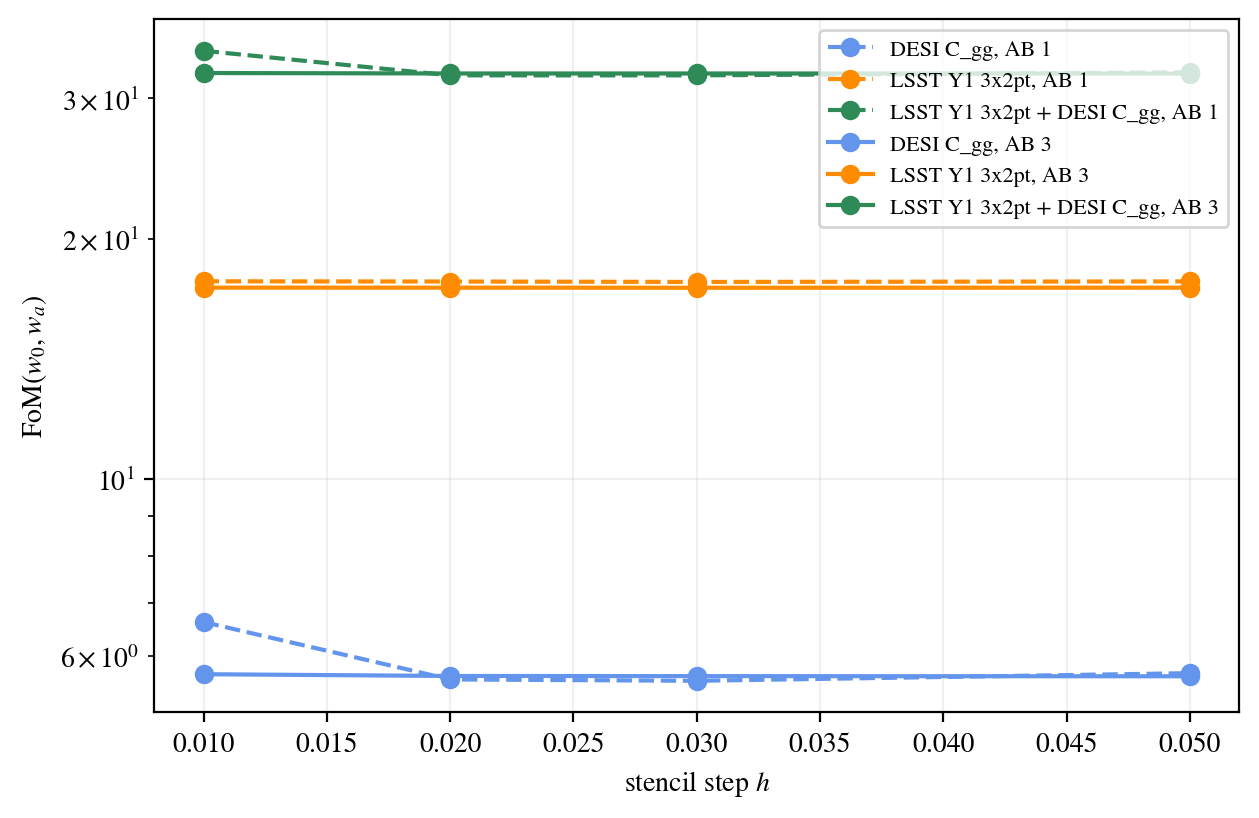

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
styles = dict(zip(ACCURACY_BOOSTS, ['--', '-', ':', '-.']))
colors = dict(zip(probes(H_MAIN), ['cornflowerblue', 'darkorange', 'seagreen']))
for boost in ACCURACY_BOOSTS:
    for label in probes(H_MAIN):
        fom = [stability.loc[(label, boost, h), 'FoM(w0, wa)'] for h in H_SCAN]
        ax.plot(H_SCAN, fom, marker='o', ls=styles[boost], color=colors[label],
                label=f'{label}, AB {boost:g}')
ax.set_xlabel(r'stencil step $h$')
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_yscale('log')
ax.legend(fontsize=8)
plt.show()

## 6. Forecast contours

`cosmo_block` marginalizes the nuisances out of a Fisher matrix: the cosmology block of
$F^{-1}$ is the marginalized covariance, and its inverse is the Fisher matrix of the
seven cosmological parameters alone. `cnu.plot_Fisher` draws Gaussian samples of each
and hands them to getdist.

Removed no burn in
Removed no burn in
Removed no burn in


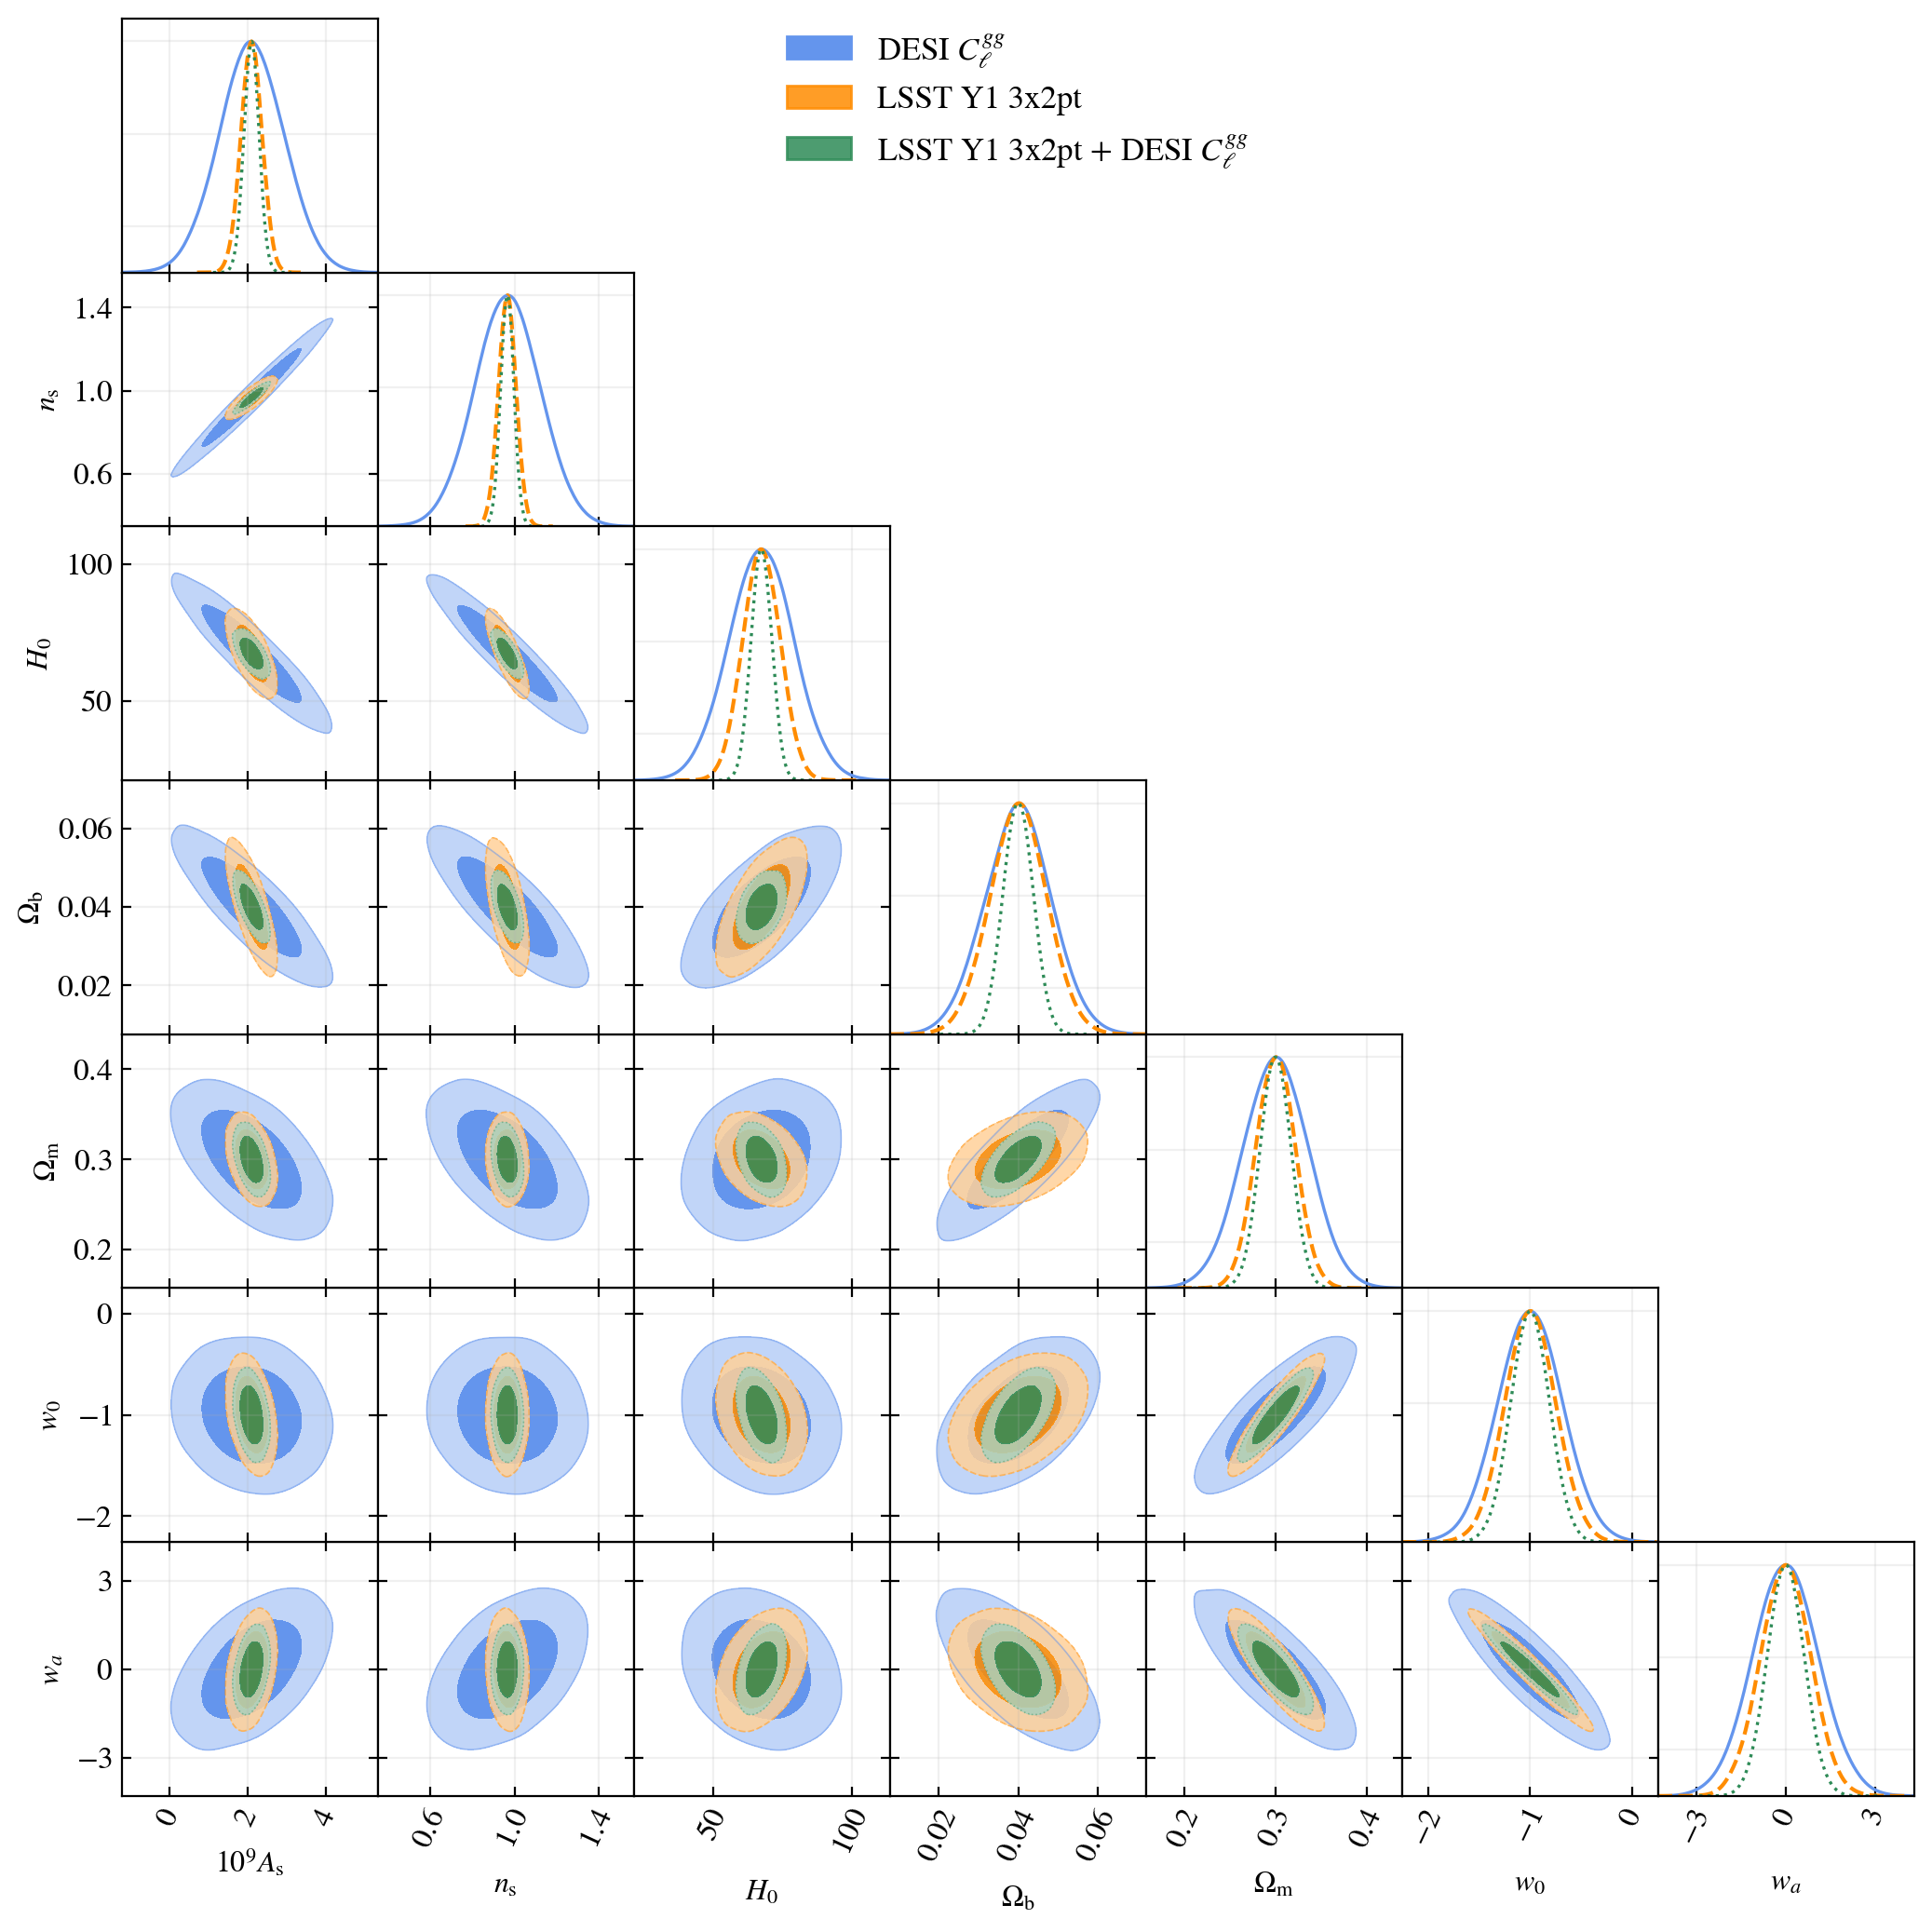

In [10]:
def cosmo_block(F, names):
    '''The Fisher matrix of COSMO with every other parameter marginalized.'''
    C = np.linalg.inv(0.5*(F + F.T))
    idx = [names.index(p) for p in COSMO]
    return np.linalg.inv(C[np.ix_(idx, idx)])


forecasts = probes(H_MAIN)
g = cnu.plot_Fisher(F=[cosmo_block(F, names) for F, names in forecasts.values()],
                    mu=desi['fiducial'][:len(COSMO)], names=COSMO,
                    labels=COSMO_LABELS, filled=True,
                    chain_names=[probe_label(p) for p in forecasts])

## 7. Fisher biases: FKEM against SVD, Limber against non-Limber

Fit the reference model to data generated by an alternative model. To linear order in
$\delta = m_\mathrm{alt} - m_\mathrm{ref}$, the best fit moves by

$$\delta p = F^{-1} B, \qquad B = D^T C^{-1} \delta$$

(Huterer et al. 2006; Amara & Refregier 2008), with $D$ the derivatives of the reference
model. The nuisance parameters are part of $F$: the biases and velocity dispersions
absorb what they can of $\delta$, and the shift left in each cosmological parameter is
the marginalized one. The tables give $\delta p/\sigma$, the shift in units of the
marginalized error. The linear order holds while the shifts stay well below one
$\sigma$; a larger value says the alternative would be detected, and its size is only
indicative.

In LSST Y1 3x2pt + DESI $C_\ell^{gg}$ the numerators of the two blocks add, as
their information does: an alternative applied to DESI alone shifts the joint fit
through the DESI block only.

The tables of the next cell are the $\Delta z = 0.2$ forecast, whose cache of
section 3 also carries the LSST alternatives; the two cells after them repeat the
two DESI alternatives on every layout.

In [11]:
def bias_in_sigma(F, names, shifts):
    '''delta_p/sigma of COSMO for the summed numerators of `shifts`.'''
    shift = fm.fisher_bias(F, names, *shifts)
    sigma = fm.marginalized_sigma(F, names, COSMO)
    return {p: shift[p]/sigma[p] for p in COSMO}


def bias_tables(h):
    '''{probe: DataFrame of delta_p/sigma and delta chi2} at step h.'''
    F_joint, names_joint = joint_fisher(h)
    cases = {
        DESI_PROBE: (desi['F'][h], desi['names'],
                              {label: [('desi', label)] for label in DESI_ALTERNATIVES}),
        LSST_PROBE: (lsst['F'][h], lsst['names'],
                          {label: [('lsst', label)] for label in LSST_ALTERNATIVES}),
        JOINT_PROBE: (F_joint, names_joint, {
            'DESI FKEM, cap 550': [('desi', 'FKEM, cap 550')],
            'DESI Limber': [('desi', 'Limber')],
            'LSST SVD engine': [('lsst', 'SVD engine')],
            'Limber in both': [('desi', 'Limber'), ('lsst', 'Limber')]}),
    }
    tables = {}
    for probe, (F, names, alternatives) in cases.items():
        rows = {}
        for label, parts in alternatives.items():
            shifts = [(results[block]['B'][h][alt], results[block]['names'])
                      for block, alt in parts]
            rows[label] = {**bias_in_sigma(F, names, shifts),
                           'delta chi2': sum(results[block]['dchi2'][alt]
                                             for block, alt in parts)}
        tables[probe] = pd.DataFrame(rows).T
    return tables


biases = bias_tables(H_MAIN)
for probe, frame in biases.items():
    print(f'\n{probe}: delta_p / sigma at h = {H_MAIN}')
    display(frame)


DESI C_gg: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"FKEM, cap 550",-0.004455,-0.002627,0.005789,0.003009,-0.002474,0.005027,-0.004091,0.1148
Limber,3.366,5.614,-4.928,-4.919,-3.474,-1.116,2.838,331.8



LSST Y1 3x2pt: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
SVD engine,-0.0001273,0.0009722,-0.00242,-0.001006,0.00235,0.001926,-0.00233,0.0001386
Limber,-0.4048,0.2673,-0.2471,-0.2042,0.294,0.1167,-0.3129,11.18



LSST Y1 3x2pt + DESI C_gg: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"DESI FKEM, cap 550",-0.006262,-0.01162,0.01308,0.005894,-0.001569,0.004918,-0.002172,0.1148
DESI Limber,-1.384,1.034,-1.692,-0.5644,1.356,1.193,-2.137,331.8
LSST SVD engine,-0.0008323,-0.0004413,-0.0008162,0.0003891,0.001485,0.001334,-0.001462,0.0001386
Limber in both,-1.415,1.081,-1.683,-0.678,1.289,1.084,-2.058,343


### The DESI alternatives on every layout

The comparison extends to the other three layouts. Each layout's two DESI
alternatives (FKEM with the cap at $\ell = 550$; Limber) are evaluated once at the
fiducial point with the layout's own settings (`LAYOUT_FISHER_OVERRIDES`, accuracy
boost 1), so each alternative vector is compared with the layout's own reference
vector. The vectors are cached in
`chains/EXAMPLE_EVALUATE_FISHER_ALTERNATIVES.pkl`; without the cache a first run
takes about 4 + 4 min ($\Delta d_\mathrm{com} = 62$ Mpc), 8 + 8 min ($\Delta z = 0.02$) and 1 + 1 min
($\Delta z = 0.05$) on a laptop (measured: 264, 229, 502, 480, 52 and 44 s).

The numerator $B = D^T C^{-1} \delta$ is built from the layout's cached derivatives
and its covariance file, masked and scaled to 12,300 deg². On $\Delta z = 0.2$ this
construction reproduces the Fisher module's own $B$ to $10^{-15}$, which checks the
file-based covariance against the module.

The $\Delta\chi^2 = \delta^T C^{-1} \delta$ of each alternative against the
reference model:

| Layout | FKEM, cap 550 | Limber |
| --- | ---: | ---: |
| $\Delta d_\mathrm{com} = 62$ Mpc | 64.2 | $1.86 \times 10^4$ |
| $\Delta z = 0.02$ | 80.7 | $3.67 \times 10^4$ |
| $\Delta z = 0.05$ | 4.47 | 3483 |
| $\Delta z = 0.2$ | 0.115 | 332 |

These are the same comparisons the data-vector tests make
(`tests/data_vector/test_nonlimber_fkem_fair.py` and `test_nonlimber_gg.py`),
rescaled from the 14,000 deg² covariance to the common 12,300 deg².

In [12]:
# Fisher biases on every DESI layout. Each layout's alternative vectors
# (DESI_ALTERNATIVES at the layout's own likelihood overrides) are evaluated
# once at the fiducial and cached; B = D^T C^-1 (m_alt - m_ref) then comes
# from the layout's cached derivatives and its covariance file. Delta z = 0.2
# reuses section 3's vectors and B.
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
LAYOUT_DATASETS = {
    'Delta d_com = 62 Mpc': 'lssty1xdesi_desi_dr3',
    'Delta z = 0.02': 'lssty1xdesi_desi_dr1_dz0p02',
    'Delta z = 0.05': 'lssty1xdesi_desi_dr1_dz0p05',
    'Delta z = 0.2': 'lssty1xdesi_desi_dr1_dz0p20',
}
ALTERNATIVES_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                      'EXAMPLE_EVALUATE_FISHER_ALTERNATIVES.pkl')
RECOMPUTE_ALTERNATIVES = False


def read_rows(path):
    '''Return the data rows of a text file, split on blanks.

    Arguments:
      path = the file; lines starting with # and blank lines are skipped.

    Returns:
      list of lists of strings, one per data row.
    '''
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    '''Return the value of one "key = value" line of a .dataset file.'''
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


def layout_covariance(key):
    '''The covariance of one DESI layout as a dense matrix, with its layout.

    Arguments:
      key = a LAYOUT_DATASETS key.

    Returns:
      dict: 'C' (n x n covariance of the full vector), 'mask' (bool, n),
      'bins' and 'pairs' (rows of the bin table and the cross-pair list),
      'ells' (the band centers) and 'n_ee' (the length of the masked EE
      block in front of the clustering spectra).
    '''
    stem = LAYOUT_DATASETS[key]
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = read_rows(DESI_DATA + stem + '_pairs.txt')
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    n = len(layout_desi[key]['m_ref'])
    mask = np.zeros(n, dtype=bool)
    for row in read_rows(DESI_DATA + dataset_entry(stem, 'mask_file')):
        mask[int(float(row[0]))] = float(row[1]) > 0
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    n_ee = n - (len(bins) + len(pairs))*len(ells)
    return {'C': C, 'mask': mask, 'bins': bins, 'pairs': pairs, 'ells': ells,
            'n_ee': n_ee}


def layout_alternatives(key, vectors):
    '''B and delta chi2 of each DESI alternative on one layout.

    Arguments:
      key     = a LAYOUT_DATASETS key.
      vectors = {alternative: m_alt} at the layout's fiducial (unused for
                Delta z = 0.2, which reuses section 3).

    Returns:
      {alternative: {'B': B vector over the layout's parameters,
                     'dchi2': delta^T C^-1 delta}}.
    '''
    out = {}
    if key == 'Delta z = 0.2':
        for label in DESI_ALTERNATIVES:
            out[label] = {'B': desi['B'][H_MAIN][label], 'dchi2': desi['dchi2'][label]}
        return out
    res = layout_desi[key]
    cov = layout_covariance(key)
    kept = np.where(cov['mask'])[0]
    inv_kept = np.linalg.inv(cov['C'][np.ix_(kept, kept)])*AREA_DEG2/DESI_COV_AREA_DEG2
    D = np.array(res['D'][H_MAIN])
    for label in DESI_ALTERNATIVES:
        delta = (np.array(vectors[label]) - np.array(res['m_ref']))[kept]
        out[label] = {'B': D[kept].T @ (inv_kept @ delta),
                      'dchi2': float(delta @ inv_kept @ delta)}
    return out


# the alternative vectors of the three computed layouts (one model build
# and one evaluation per alternative; the compiled interface holds one
# model at a time, so each is built, evaluated and released in turn)
if RECOMPUTE_ALTERNATIVES or not os.path.exists(ALTERNATIVES_CACHE):
    alternative_vectors = {}
    for key in LAYOUT_FISHER_OVERRIDES:
        alternative_vectors[key] = {}
        for label, overrides in DESI_ALTERNATIVES.items():
            start = time.time()
            alt = fm.ModelFisher(
                LAYOUTS[key]['yaml'], COSMO,
                likelihood_overrides={**LAYOUT_FISHER_OVERRIDES[key], **overrides},
                invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                accuracy_boost=LAYOUT_ACCURACY_BOOST)
            alternative_vectors[key][label] = alt.dv()
            del alt
            print(f'{key}, {label}: {time.time() - start:.0f} s', flush=True)
    with open(ALTERNATIVES_CACHE, 'wb') as f:
        pickle.dump({'vectors': alternative_vectors,
                     'alternatives': DESI_ALTERNATIVES,
                     'overrides': LAYOUT_FISHER_OVERRIDES,
                     'accuracy_boost': LAYOUT_ACCURACY_BOOST}, f)
else:
    with open(ALTERNATIVES_CACHE, 'rb') as f:
        cached = pickle.load(f)
    settings = {'alternatives': DESI_ALTERNATIVES,
                'overrides': LAYOUT_FISHER_OVERRIDES,
                'accuracy_boost': LAYOUT_ACCURACY_BOOST}
    for name, value in settings.items():
        if cached.get(name) != value:
            raise RuntimeError(f'{ALTERNATIVES_CACHE} holds {name} = '
                               f'{cached.get(name)}, but this notebook asks for '
                               f'{value}: set RECOMPUTE_ALTERNATIVES = True')
    alternative_vectors = cached['vectors']

layout_alts = {}
for key in LAYOUT_DATASETS:
    layout_alts[key] = layout_alternatives(key, alternative_vectors.get(key))

layout_bias = {}
for key in LAYOUT_DATASETS:
    for probe, (F, names) in layout_probes(key).items():
        for label in DESI_ALTERNATIVES:
            shift = [(layout_alts[key][label]['B'], layout_desi[key]['names'])]
            layout_bias[(probe, label, key)] = bias_in_sigma(F, names, shift)

dchi2_table = {}
for key in LAYOUT_DATASETS:
    row = {}
    for label in DESI_ALTERNATIVES:
        row[label] = layout_alts[key][label]['dchi2']
    dchi2_table[key] = row
print('delta chi2 of each DESI alternative against the reference model:')
display(pd.DataFrame(dchi2_table).T)

delta chi2 of each DESI alternative against the reference model:


,"FKEM, cap 550",Limber
Delta d_com = 62 Mpc,64.21,1.859e+04
Delta z = 0.02,80.68,3.672e+04
Delta z = 0.05,4.469,3483
Delta z = 0.2,0.1148,331.8


The four figures below put the layouts side by side, one figure per forecast and
DESI alternative: DESI $C_\ell^{gg}$ alone and then LSST Y1 3x2pt + DESI
$C_\ell^{gg}$ with FKEM at the cap of 550, followed by the same pair with Limber.
Each figure gives one bar per layout and parameter ($\Delta d_\mathrm{com} = 62$ Mpc blue, $\Delta z = 0.02$
red, $\Delta z = 0.05$ green, $\Delta z = 0.2$ orange), dashed lines at
$\pm 1\sigma$, and a legend with each layout's $\Delta\chi^2$. The two Limber
figures use a symmetric-log axis, linear within $\pm 1$.

**FKEM, cap 550.** On $\Delta z = 0.2$ every shift stays below $0.013\sigma$; on
$\Delta z = 0.05$ the shifts reach $0.06\sigma$ alone and $0.18\sigma$ in the
combination. The thin-bin layouts are biased by a sizable fraction of the error:
the $\Delta d_\mathrm{com} = 62$ Mpc layout reaches $0.32\sigma$ alone (in $w_a$) and $0.64\sigma$ in the combination (in
$\Omega_b$, with $0.49\sigma$ in $H_0$), and $\Delta z = 0.02$ reaches
$0.47\sigma$ alone ($w_a$) and $0.85\sigma$ in the combination ($\Omega_b$, with
$0.72\sigma$ in $H_0$ and $0.45\sigma$ in $w_a$). FKEM projects the linear power
exactly but adds the nonlinear correction in Limber, and that treatment is
harmless on wide bins while it biases the thin-bin layouts. The shifts grow in
units of $\sigma$ in the combination because LSST shrinks the errors in directions
where the DESI-induced numerator $B$ remains. The reference - the low-rank SVD
engine, which projects the full nonlinear $P_{gg}$ non-Limber - is the more
complete model.

**Limber.** On $\Delta z = 0.2$ the shifts range from $0.6\sigma$ to $5.6\sigma$; on the
thin layouts they reach tens of $\sigma$ - for example $43\sigma$ in $\Omega_m$ on
$\Delta z = 0.02$ alone. Shifts this large are far outside the linear regime of
$\delta p = F^{-1} B$, so their size is only indicative; the conclusion is that
Limber is excluded for DESI clustering on every layout.

One caveat: the thin-layout derivatives use the single step $h = 0.02$, so these
shifts carry no step scan. The next subsection scans the step on
$\Delta z = 0.2$.

In [13]:
def draw_bias_bars(probe, label):
    '''Draw delta_p/sigma of COSMO for one forecast and one DESI alternative.

    One bar per layout and parameter, the four layouts side by side; the
    dashed lines mark +-1 sigma. A Limber figure uses a symmetric log axis,
    linear within +-1 sigma.

    Arguments:
      probe = DESI_PROBE or JOINT_PROBE.
      label = a key of DESI_ALTERNATIVES.

    Side effects: draws one figure.
    '''
    x = np.arange(len(COSMO))
    width = 0.8/len(LAYOUT_DATASETS)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for k, key in enumerate(LAYOUT_DATASETS):
        shifts = layout_bias[(probe, label, key)]
        values = []
        for p in COSMO:
            values.append(shifts[p])
        ax.bar(x + (k - (len(LAYOUT_DATASETS) - 1)/2)*width, values,
               width=width, color=LAYOUT_COLORS[key],
               label=(f'{LAYOUT_LABELS[key]} ($\\Delta\\chi^2$ = '
                      f'{layout_alts[key][label]["dchi2"]:.3g})'))
    ax.axhline(0.0, color='black', lw=0.8)
    for level in (-1.0, 1.0):
        ax.axhline(level, color='gray', lw=0.6, ls='--')
    if label == 'Limber':
        ax.set_yscale('symlog', linthresh=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(['$%s$' % s for s in COSMO_LABELS])
    ax.set_title(f'{probe_label(probe)}; DESI alternative: {label}')
    ax.set_ylabel(r'$\delta p/\sigma$')
    ax.legend(fontsize=8.5)
    plt.show()

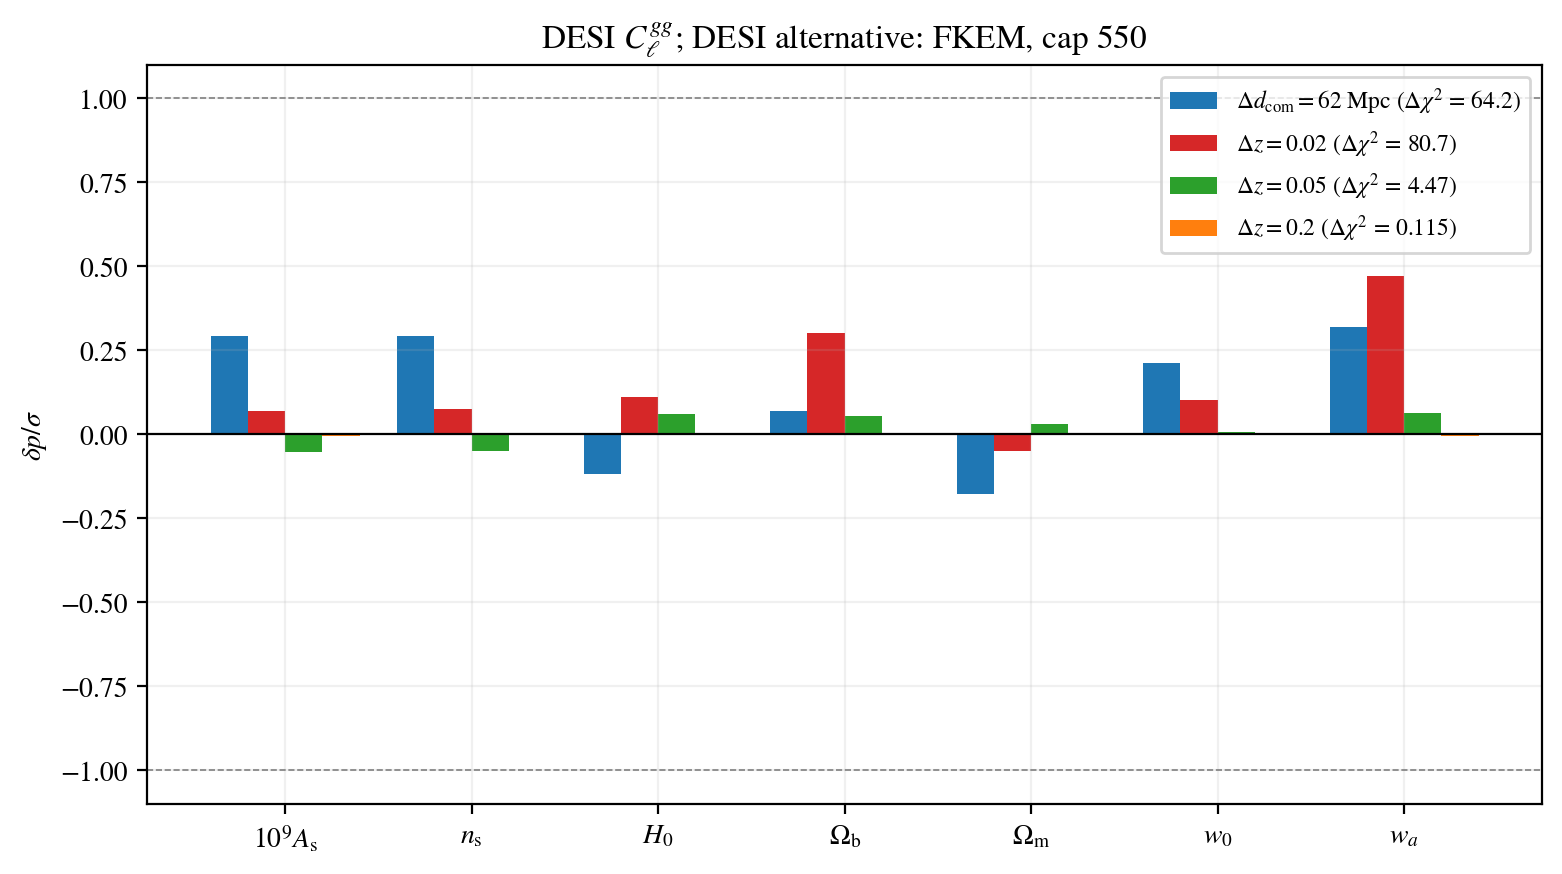

In [14]:
draw_bias_bars(DESI_PROBE, 'FKEM, cap 550')

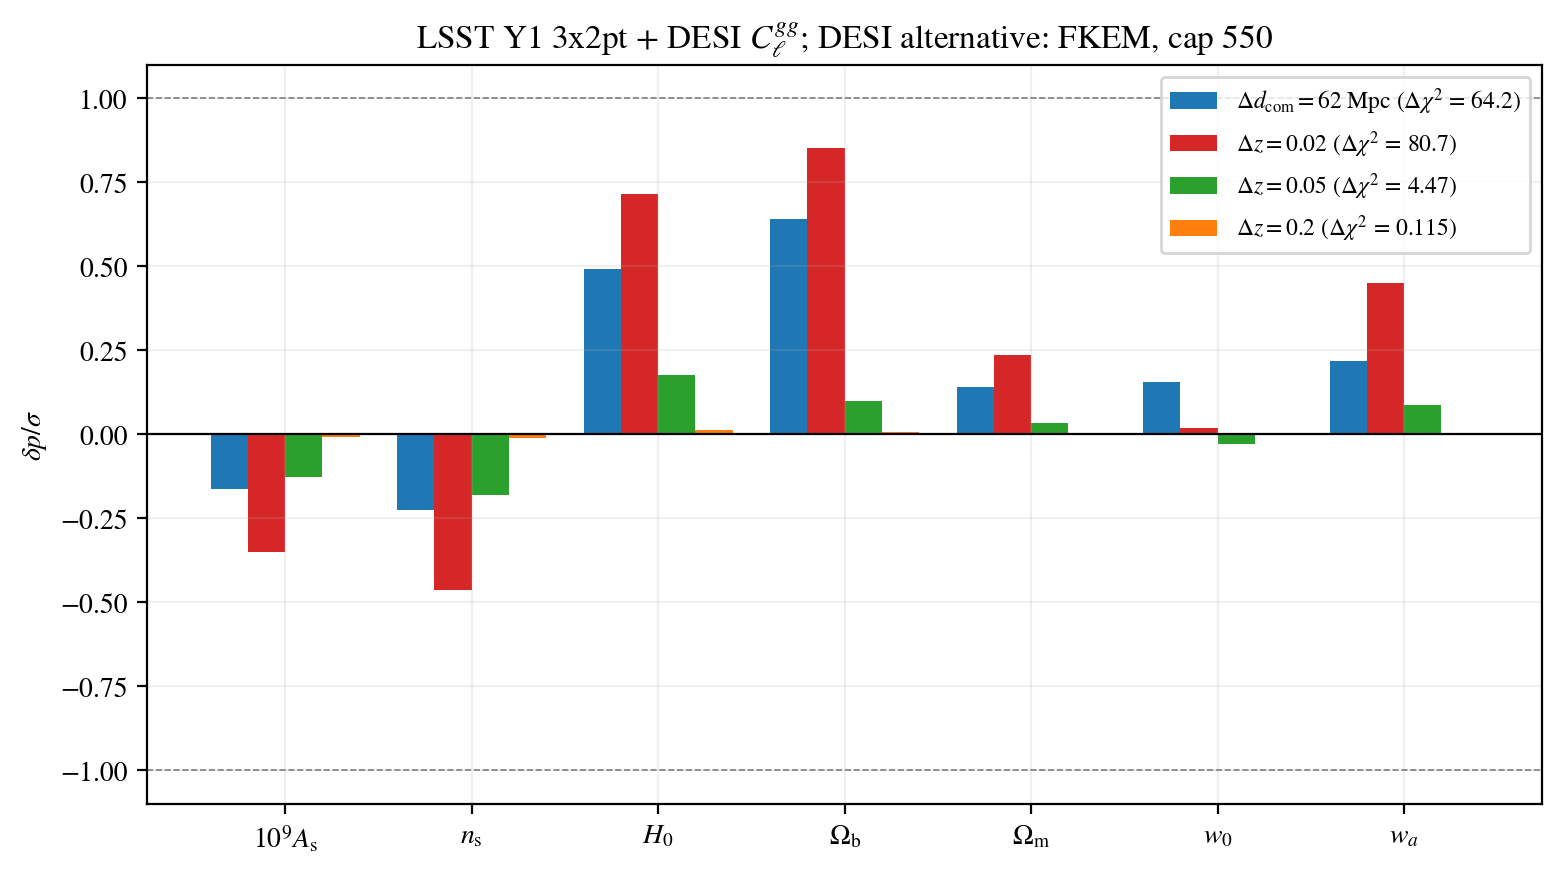

In [15]:
draw_bias_bars(JOINT_PROBE, 'FKEM, cap 550')

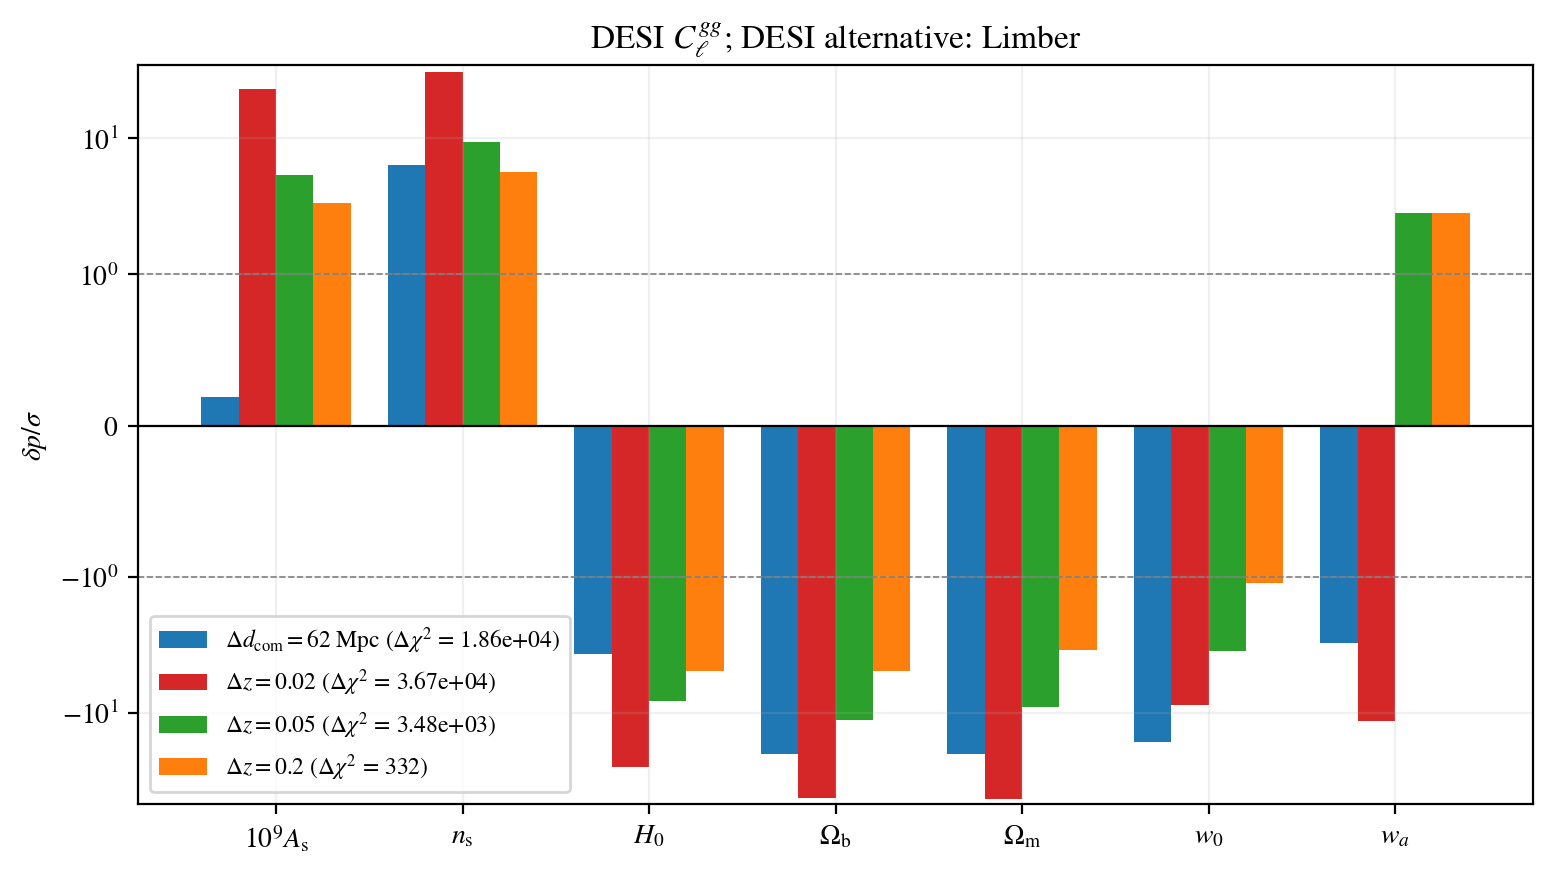

In [16]:
draw_bias_bars(DESI_PROBE, 'Limber')

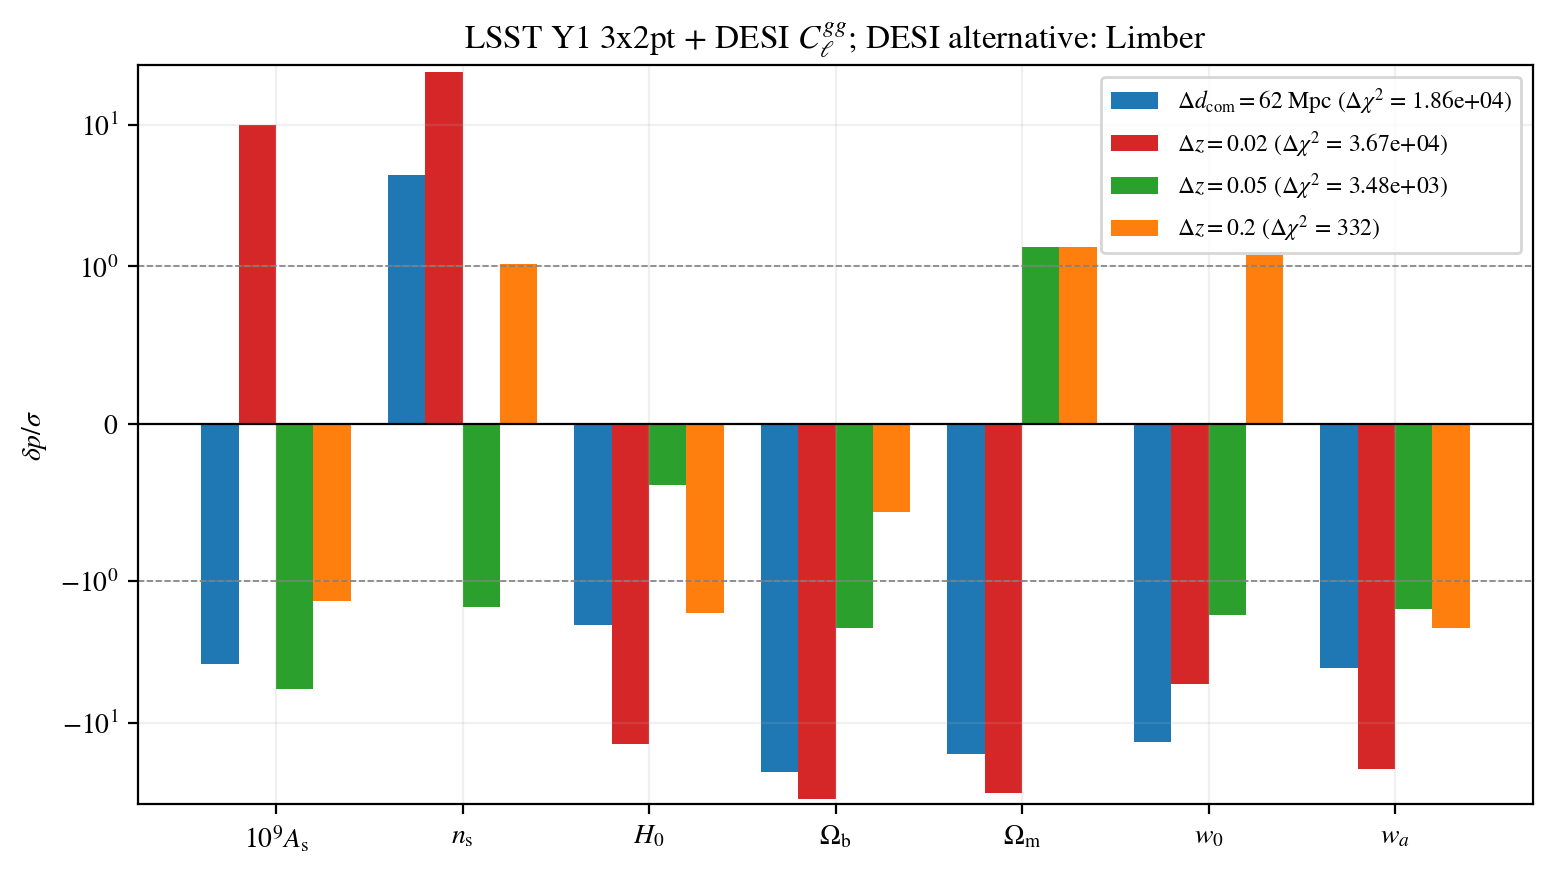

In [17]:
draw_bias_bars(JOINT_PROBE, 'Limber')

### Fisher-bias stability against $h$

The shifts depend on the derivatives too, so they carry the same step dependence as
the errors. The table repeats every $\Delta z = 0.2$ shift at each step of
`H_SCAN` = 0.01, 0.02, 0.03 and 0.05; only this layout has a step scan.

The heatmap below draws the same table. The rows are the (forecast, alternative)
pairs in the order of the section 7 tables, the columns the seven cosmological
parameters, and the color is $\delta p/\sigma$ at `H_MAIN` = 0.02, on a
symmetric-log color scale that is linear within $\pm 0.01$. Each cell's text gives
the value and, below it, the spread (max - min over `H_SCAN`). Every spread is at
most 0.02, against shifts that range from $10^{-4}$ to 5.6: the biases are
step-independent.

In [18]:
rows = {}
for h in H_SCAN:
    for probe, frame in bias_tables(h).items():
        for label, row in frame.iterrows():
            rows[(probe, label, h)] = row
pd.DataFrame(rows).T.sort_index()

As_1e9         ns  \
DESI C_gg                 FKEM, cap 550      0.01  -0.004613  -0.002774   
                                             0.02  -0.004455  -0.002627   
                                             0.03  -0.004531    -0.0027   
                                             0.05  -0.004538   -0.00272   
                          Limber             0.01      3.361      5.613   
                                             0.02      3.366      5.614   
                                             0.03      3.368      5.614   
                                             0.05      3.365      5.612   
LSST Y1 3x2pt             Limber             0.01    -0.4056     0.2676   
                                             0.02    -0.4048     0.2673   
                                             0.03    -0.4051     0.2673   
                                             0.05    -0.4049     0.2674   
                          SVD engine         0.01 -0.0001294  0.0009737   
                                             0.02 -0.0001273  0.0009722   
                                             0.03 -0.0001276  0.0009726   
                                             0.05 -0.0001267  0.0009733   
LSST Y1 3x2pt + DESI C_gg DESI FKEM, cap 550 0.01  -0.006312   -0.01163   
                                             0.02  -0.006262   -0.01162   
                                             0.03  -0.006286   -0.01162   
                                             0.05  -0.006251   -0.01163   
                          DESI Limber        0.01     -1.377      1.036   
                                             0.02     -1.384      1.034   
                                             0.03     -1.386      1.035   
                                             0.05     -1.384      1.036   
                          LSST SVD engine    0.01 -0.0008337 -0.0004411   
                                             0.02 -0.0008323 -0.0004413   
                                             0.03 -0.0008324  -0.000441   
                                             0.05  -0.000832 -0.0004405   
                          Limber in both     0.01     -1.409      1.083   
                                             0.02     -1.415      1.081   
                                             0.03     -1.417      1.082   
                                             0.05     -1.415      1.083   

                                                          H0    omegab  \
DESI C_gg                 FKEM, cap 550      0.01   0.005889  0.003186   
                                             0.02   0.005789  0.003009   
                                             0.03    0.00584  0.003095   
                                             0.05   0.005923  0.003023   
                          Limber             0.01     -4.925     -4.92   
                                             0.02     -4.928    -4.919   
                                             0.03     -4.932    -4.917   
                                             0.05     -4.929    -4.915   
LSST Y1 3x2pt             Limber             0.01    -0.2479   -0.2034   
                                             0.02    -0.2471   -0.2042   
                                             0.03    -0.2473   -0.2039   
                                             0.05     -0.247   -0.2042   
                          SVD engine         0.01  -0.002423 -0.001003   
                                             0.02   -0.00242 -0.001006   
                                             0.03   -0.00242 -0.001005   
                                             0.05  -0.002421 -0.001006   
LSST Y1 3x2pt + DESI C_gg DESI FKEM, cap 550 0.01    0.01303  0.005957   
                                             0.02    0.01308  0.005894   
                                             0.03    0.01305  0.005927   
                                             0.05    0.01314  0.005857   
                        

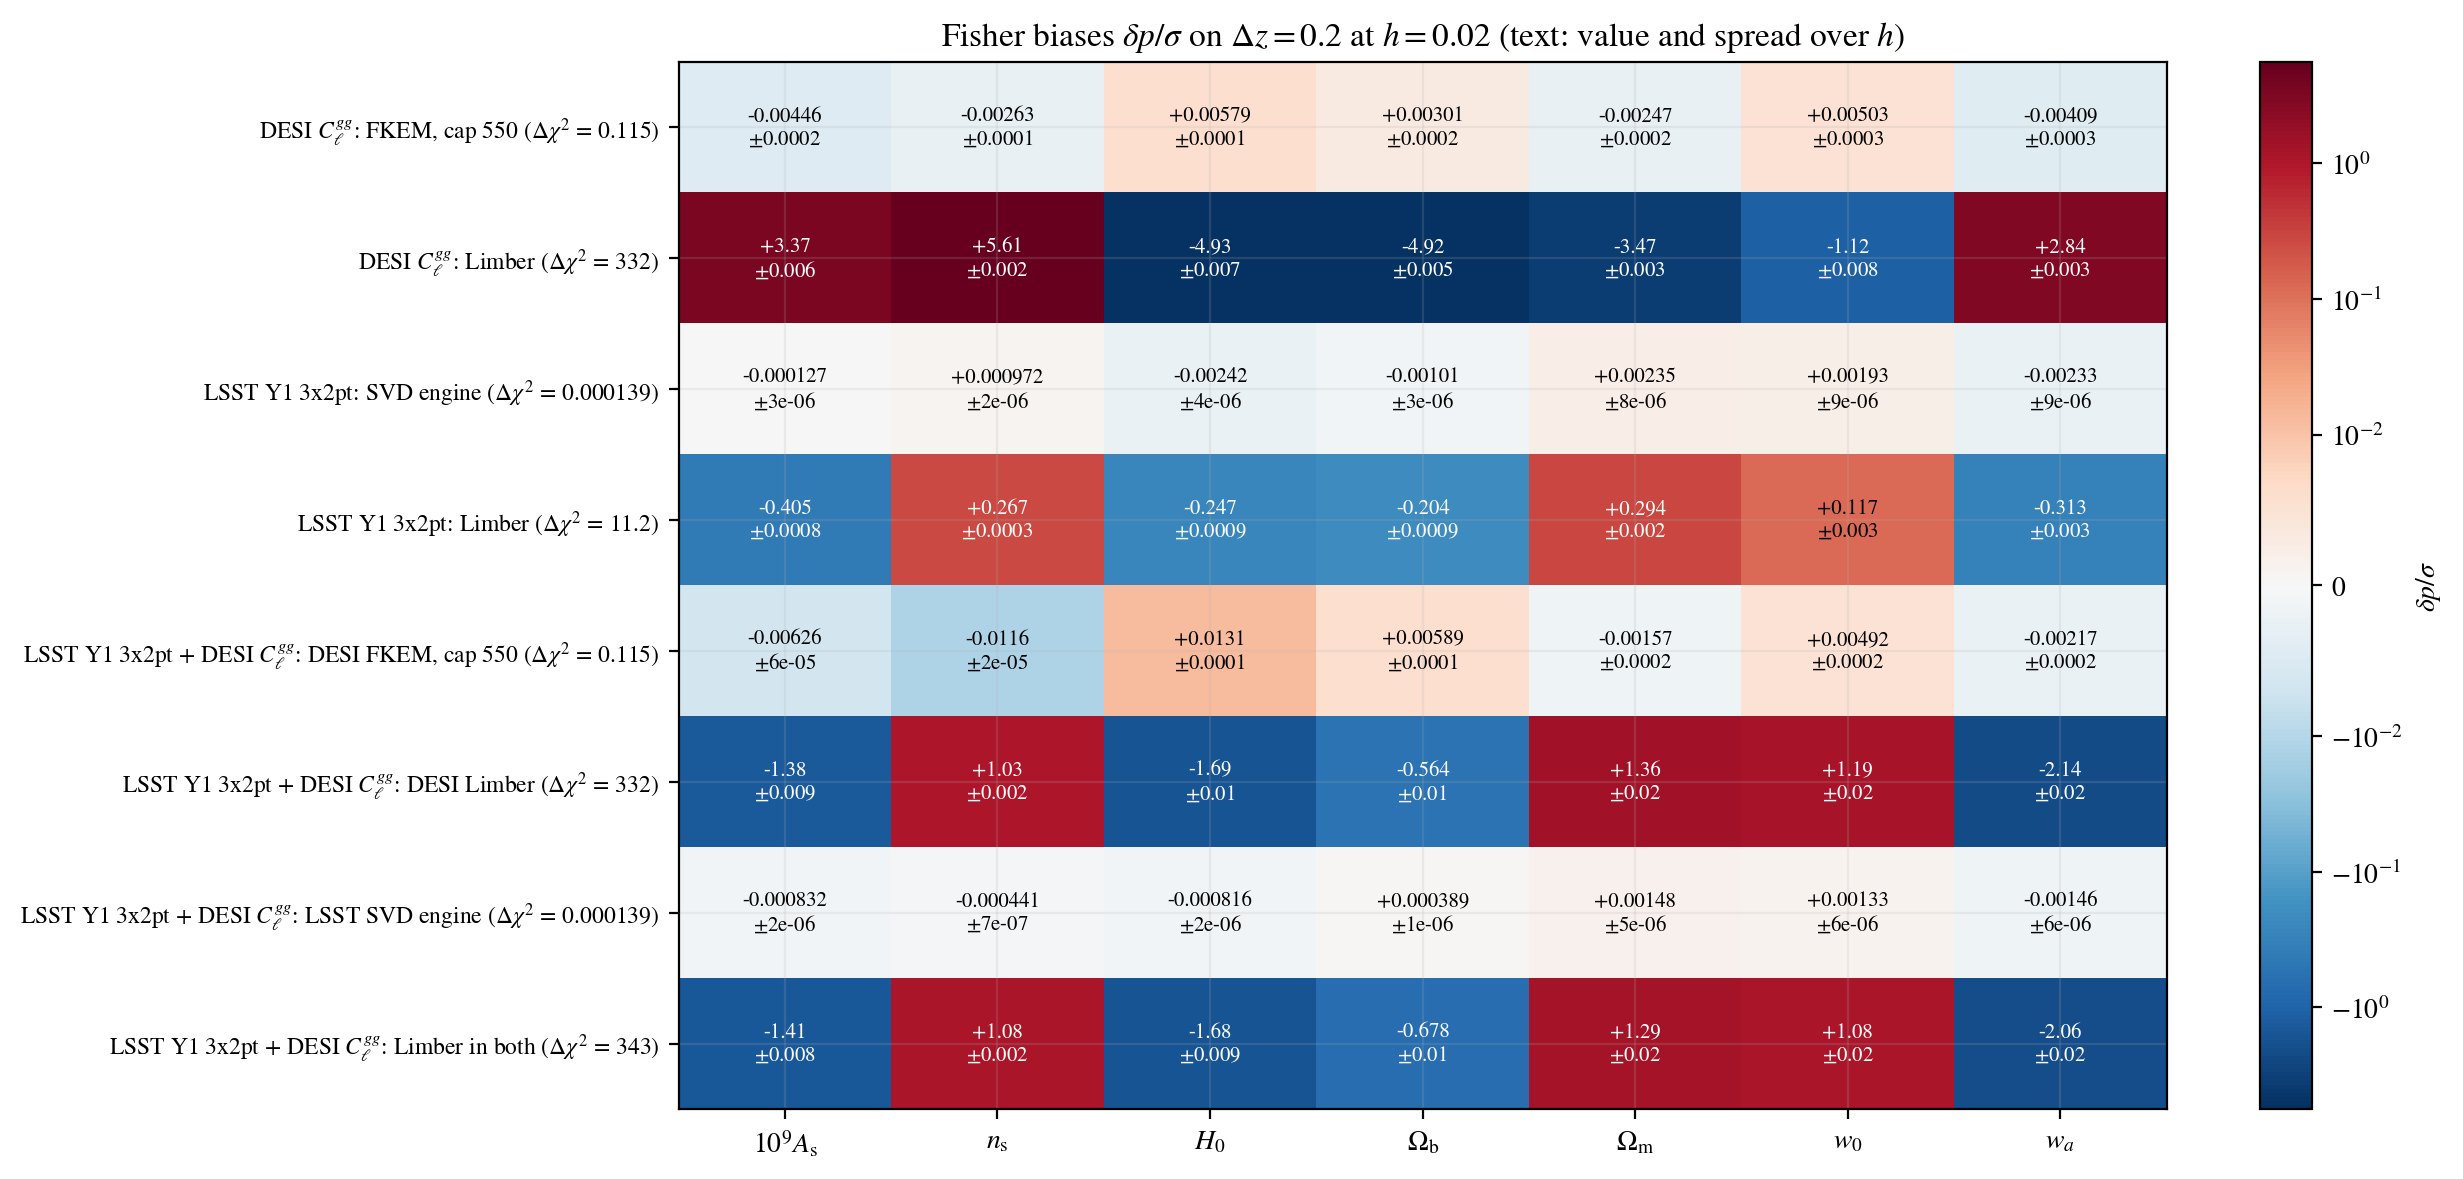

In [19]:
# One picture of the table above (Delta z = 0.2, the layout with the step
# scan): each cell is the shift delta_p/sigma of one parameter (column) for
# one probe and alternative (row) at the step H_MAIN, colored on a
# symmetric log scale; the text gives the value and, below it, the spread
# max - min over the steps of H_SCAN.
from matplotlib.colors import SymLogNorm

stability_bias = pd.DataFrame(rows).T.sort_index()
# rows in the order of the tables of section 7
row_keys = []
for probe, frame in biases.items():
    for label in frame.index:
        row_keys.append((probe, label))
at_main = np.zeros((len(row_keys), len(COSMO)))
spread = np.zeros((len(row_keys), len(COSMO)))
row_labels = []
for r, (probe, label) in enumerate(row_keys):
    for c, p in enumerate(COSMO):
        over_h = []
        for h in H_SCAN:
            over_h.append(stability_bias.loc[(probe, label, h), p])
        at_main[r, c] = stability_bias.loc[(probe, label, H_MAIN), p]
        spread[r, c] = max(over_h) - min(over_h)
    dchi2 = stability_bias.loc[(probe, label, H_MAIN), 'delta chi2']
    row_labels.append(f'{probe_label(probe)}: {label} '
                      f'($\\Delta\\chi^2$ = {dchi2:.3g})')

largest = max(1.0, float(np.abs(at_main).max()))
fig, ax = plt.subplots(figsize=(12, 0.65*len(row_keys) + 1.6))
image = ax.imshow(at_main, cmap='RdBu_r', aspect='auto',
                  norm=SymLogNorm(linthresh=0.01, vmin=-largest, vmax=largest))
for r in range(len(row_keys)):
    for c in range(len(COSMO)):
        shade = image.norm(at_main[r, c])
        color = 'white' if shade < 0.2 or shade > 0.8 else 'black'
        ax.text(c, r, f'{at_main[r, c]:+.3g}\n$\\pm${spread[r, c]:.1g}',
                ha='center', va='center', fontsize=7.5, color=color)
ax.set_xticks(range(len(COSMO)))
ax.set_xticklabels(['$%s$' % s for s in COSMO_LABELS])
ax.set_yticks(range(len(row_keys)))
ax.set_yticklabels(row_labels, fontsize=8.5)
ax.set_title(rf'Fisher biases $\delta p/\sigma$ on $\Delta z = 0.2$ at $h = {H_MAIN}$ '
             r'(text: value and spread over $h$)')
fig.colorbar(image, ax=ax, label=r'$\delta p/\sigma$')
plt.show()

## 8. The amplitude cut against the Fisher forecast

The galaxy power of a lens bin is proportional to $A_s b_i^2$. The flat priors let
$10^9 A_s$ range over $[0.5, 5]$ and every bias amplitude over $[0.8, 4]$, so without
a cut the amplitude ratio $A_s b_i^2/(A_s b_i^2)_\mathrm{fid}$ reaches about 50 for
the ELG groups, whose fiducial bias is 0.84. There a fixed relative numerical error
of the data vector costs many units of $\chi^2$ against the fiducial covariance (the
cost grows as the ratio squared): the N-random-models check of the
[data-vector tests](tests/data_vector/README.md#nmodels_check) fails on every layout
through that corner of the box.

Cutting the boxes at a ratio `AMPLITUDE_CUT` removes that corner, and it can only move
an inference if the data allow points near the cut. This section draws, for every DESI
layout of the project, the cut against that layout's own DESI $C_{gg}$ Fisher
forecast. The triangle shades the excluded region gray and draws the Fisher $1\sigma$
and $2\sigma$ contours (68.3% and 95.4% of a two-dimensional Gaussian) about the
fiducial, every other parameter marginalized:

- an $A_s$ – $b_i$ panel shades bin $i$'s own cut;
- a $b_i$ – $b_j$ panel shades the region either bin excludes at the fiducial $A_s$;
- a diagonal panel shades the part of the box excluded with the other parameters at
  the fiducial, and draws each forecast's marginal Gaussian.

A cut far outside the $2\sigma$ contours removes only prior volume the data already
exclude. The DESI $2\sigma$ contours reach a ratio of 1.33 on $\Delta d_\mathrm{com} = 62$ Mpc, 1.36 on
$\Delta z = 0.02$, 1.54 on $\Delta z = 0.05$ and 2.11 on $\Delta z = 0.2$, so the default
cut of 8 keeps a wide margin on every layout while bounding the amplitude, and with
it the numerical error, of every bin. The value 8 is
the cut shared by all cosmolike projects in this group, and every example yaml carries
it as the cobaya prior `amplitude_cut`. Set `AMPLITUDE_CUT` and rerun the cells to
test another cut.

The Fisher matrices of the four layouts are those of section 4 (`layout_desi`),
at the step `H_MAIN`.

In [20]:
def draw_amplitude_cut(key):
    '''Draw the amplitude cut against one layout's DESI C_gg forecast.

    The A_s box comes from the layout's example yaml, the bias boxes from
    its likelihood parameter file (a mapping with one entry per
    parameter); the contours are the DESI C_gg Fisher matrix at H_MAIN.

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    bias_labels = {}
    for leader, label in zip(layout['bias_leaders'], BIAS_GROUP_LABELS):
        bias_labels[f'DESI_B1_{leader}'] = label
    as_prior = yaml_load_file(layout['yaml'])['params']['As_1e9']['prior']
    bias_params = yaml_load_file(layout['bias_params'])
    boxes = {'As_1e9': (as_prior['min'], as_prior['max'])}
    for name in bias_labels:
        prior = bias_params[name]['prior']
        boxes[name] = (prior['min'], prior['max'])
    labels = dict(bias_labels)
    labels['As_1e9'] = COSMO_LABELS[0]
    fig, axes = cnu.plot_Fisher_amplitude_cut(
        F=[res['F'][H_MAIN]], names=[res['names']],
        fiducial=dict(zip(res['names'], res['fiducial'])),
        amplitude='As_1e9', biases=list(bias_labels), boxes=boxes,
        labels=labels, cut=AMPLITUDE_CUT,
        chain_names=[probe_label(DESI_PROBE)], show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### The cosmological prior walls

The examples' flat prior also has walls in the cosmology: $\Omega_m \in [0.2, 0.5]$,
$w_0 \le -1/3$ (an accelerating universe today), $-3 \le w_0 + w_a \le -0.01$ and
$H_0 \in [55, 91]$ km/s/Mpc. Beyond the $w_0 + w_a = -3$ wall (an early phantom
regime) and at low $\Omega_m$ the numerical error of the data vector grows - the
low-$\Omega_m$ corner is why every likelihood ships `kmax_boltzmann: 20`, as the
[data-vector tests](tests/data_vector/README.md#nmodels_check) record. For each
layout a second triangle draws the Fisher contours of DESI clustering alone and of
LSST Y1 3x2pt + DESI $C_\ell^{gg}$ against the $\Omega_m$, $w_0$ and $w_0 + w_a$
walls. The cells
read the walls from each example yaml, so they redraw whatever prior the yamls hold.

In [21]:
def draw_prior_walls(key):
    '''Draw the cosmological prior walls against one layout's forecasts.

    The walls are the omegam and w0 (`w`) boxes and the w0 + wa (`w0pwa`)
    box of the layout's example yaml; the contours are its DESI C_gg and
    LSST Y1 3x2pt + DESI C_gg Fisher matrices at H_MAIN (layout_probes).

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    example_params = yaml_load_file(layout['yaml'])['params']
    wall_boxes = {}
    for name, yaml_name in (('omegam', 'omegam'), ('w0', 'w')):
        prior = example_params[yaml_name]['prior']
        wall_boxes[name] = (prior['min'], prior['max'])
    w0pwa_prior = example_params['w0pwa']['prior']
    walls = [({'w0': 1.0, 'wa': 1.0}, w0pwa_prior['min'], w0pwa_prior['max'])]
    forecasts = layout_probes(key)
    wall_labels = [DESI_PROBE, JOINT_PROBE]
    matrices = []
    name_lists = []
    for label in wall_labels:
        matrices.append(forecasts[label][0])
        name_lists.append(forecasts[label][1])
    fig, axes = cnu.plot_Fisher_prior_walls(
        F=matrices, names=name_lists,
        fiducial=dict(zip(res['names'], res['fiducial'])),
        params=['omegam', 'w0', 'wa'],
        ranges={'omegam': (0.1, 0.6), 'w0': (-3.2, 0.2), 'wa': (-5.0, 5.0)},
        boxes=wall_boxes, walls=walls, labels=dict(zip(COSMO, COSMO_LABELS)),
        chain_names=[probe_label(p) for p in wall_labels], show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### $\Delta d_\mathrm{com} = 62$ Mpc

76 comoving bins about 62 Mpc wide, at accuracy boost 1 with a combined
$\chi$-grid factor of 64. The matrix is cached in
`chains/EXAMPLE_EVALUATE1_FISHER_AB1.pkl`; a first run without the cache builds it
in about 45 minutes on a laptop with 4 threads. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.33, far inside the
  cut at 8; the ratio is nearly the same for every bias group (1.324-1.328 across
  the six groups), because the $A_s$ error dominates it;
- no $2\sigma$ contour of DESI alone or of LSST Y1 3x2pt + DESI $C_\ell^{gg}$
  touches a prior wall: the DESI $2\sigma$ ranges
  are $\Omega_m$ 0.275-0.325, $w_0$ from $-1.16$ to $-0.84$ and $w_0 + w_a$ from
  $-1.40$ to $-0.60$;
- DESI alone reaches $\sigma(\Omega_m) = 0.0100$, $\sigma(w_0) = 0.065$ and
  $\sigma(w_a) = 0.210$, with FoM$(w_0, w_a) = 135$; the combination tightens
  them to 0.0066, 0.062 and 0.193, with FoM $= 203$.

The bias errors are so small ($\sigma_b \approx 0.008$-$0.02$) that the bias-bias
$2\sigma$ ellipses of the amplitude-cut triangle are invisible at the plotted box
ranges: only the fiducial stars show in those panels.

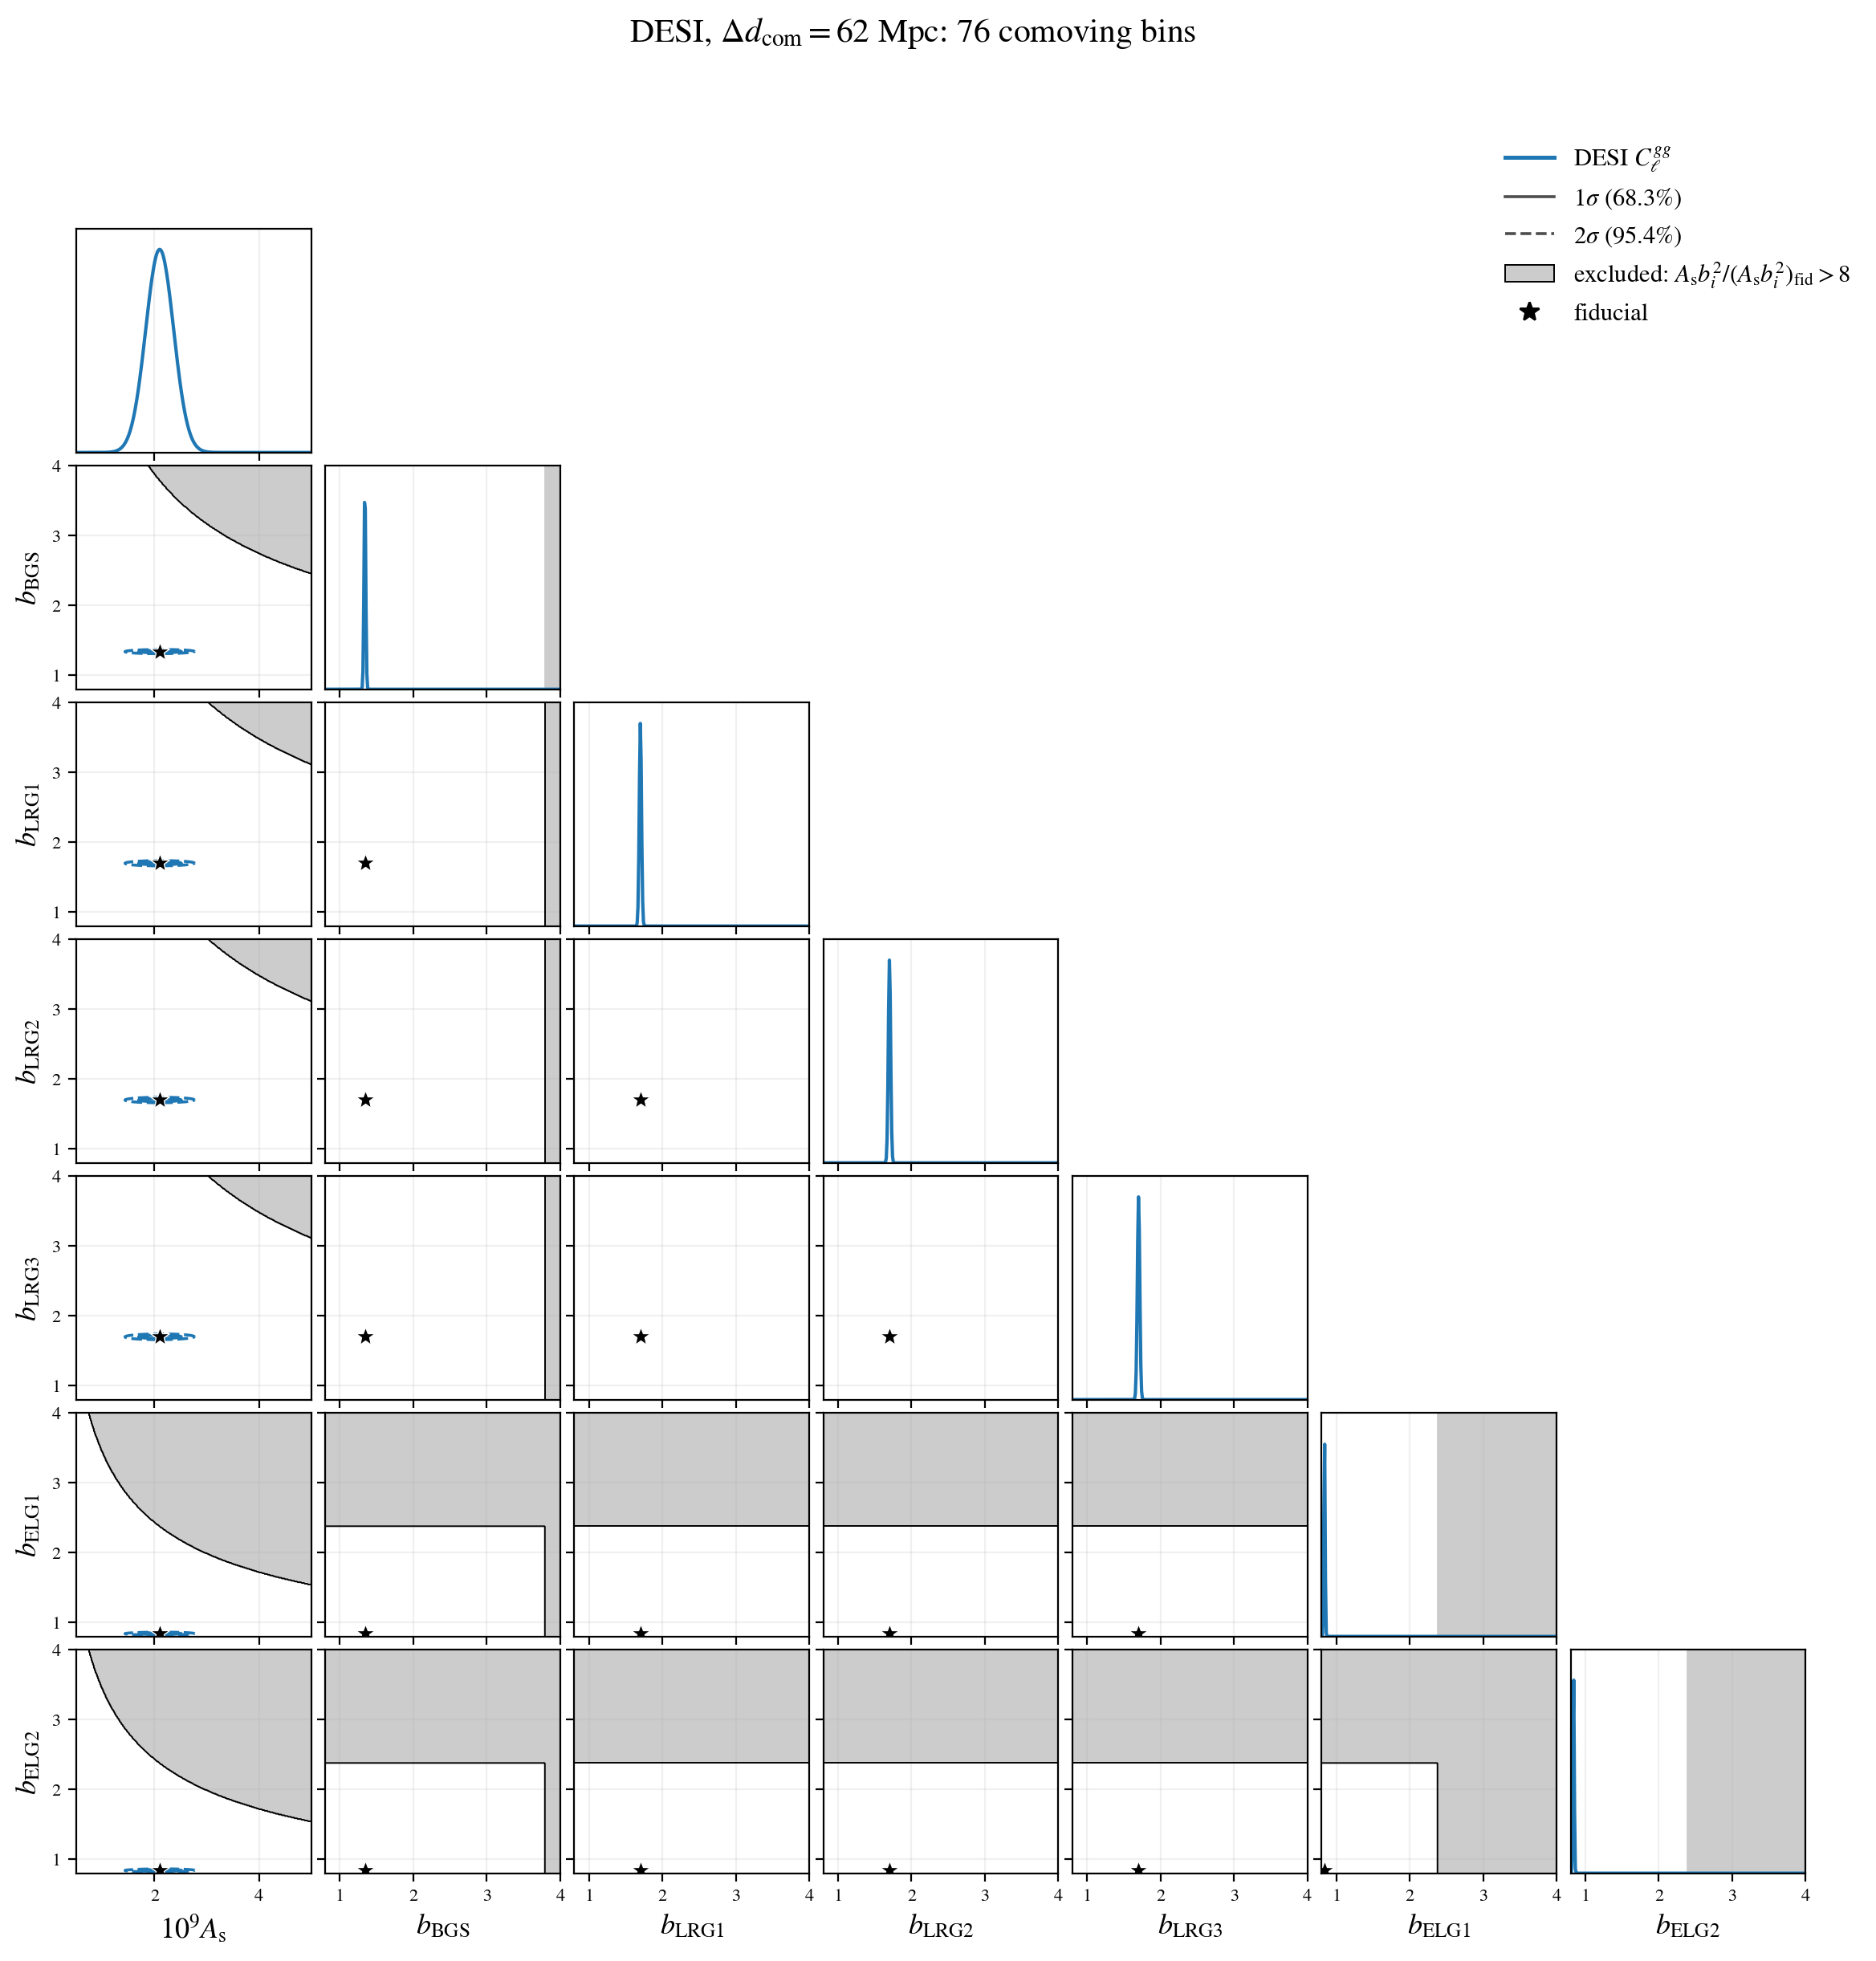

In [22]:
draw_amplitude_cut('Delta d_com = 62 Mpc')

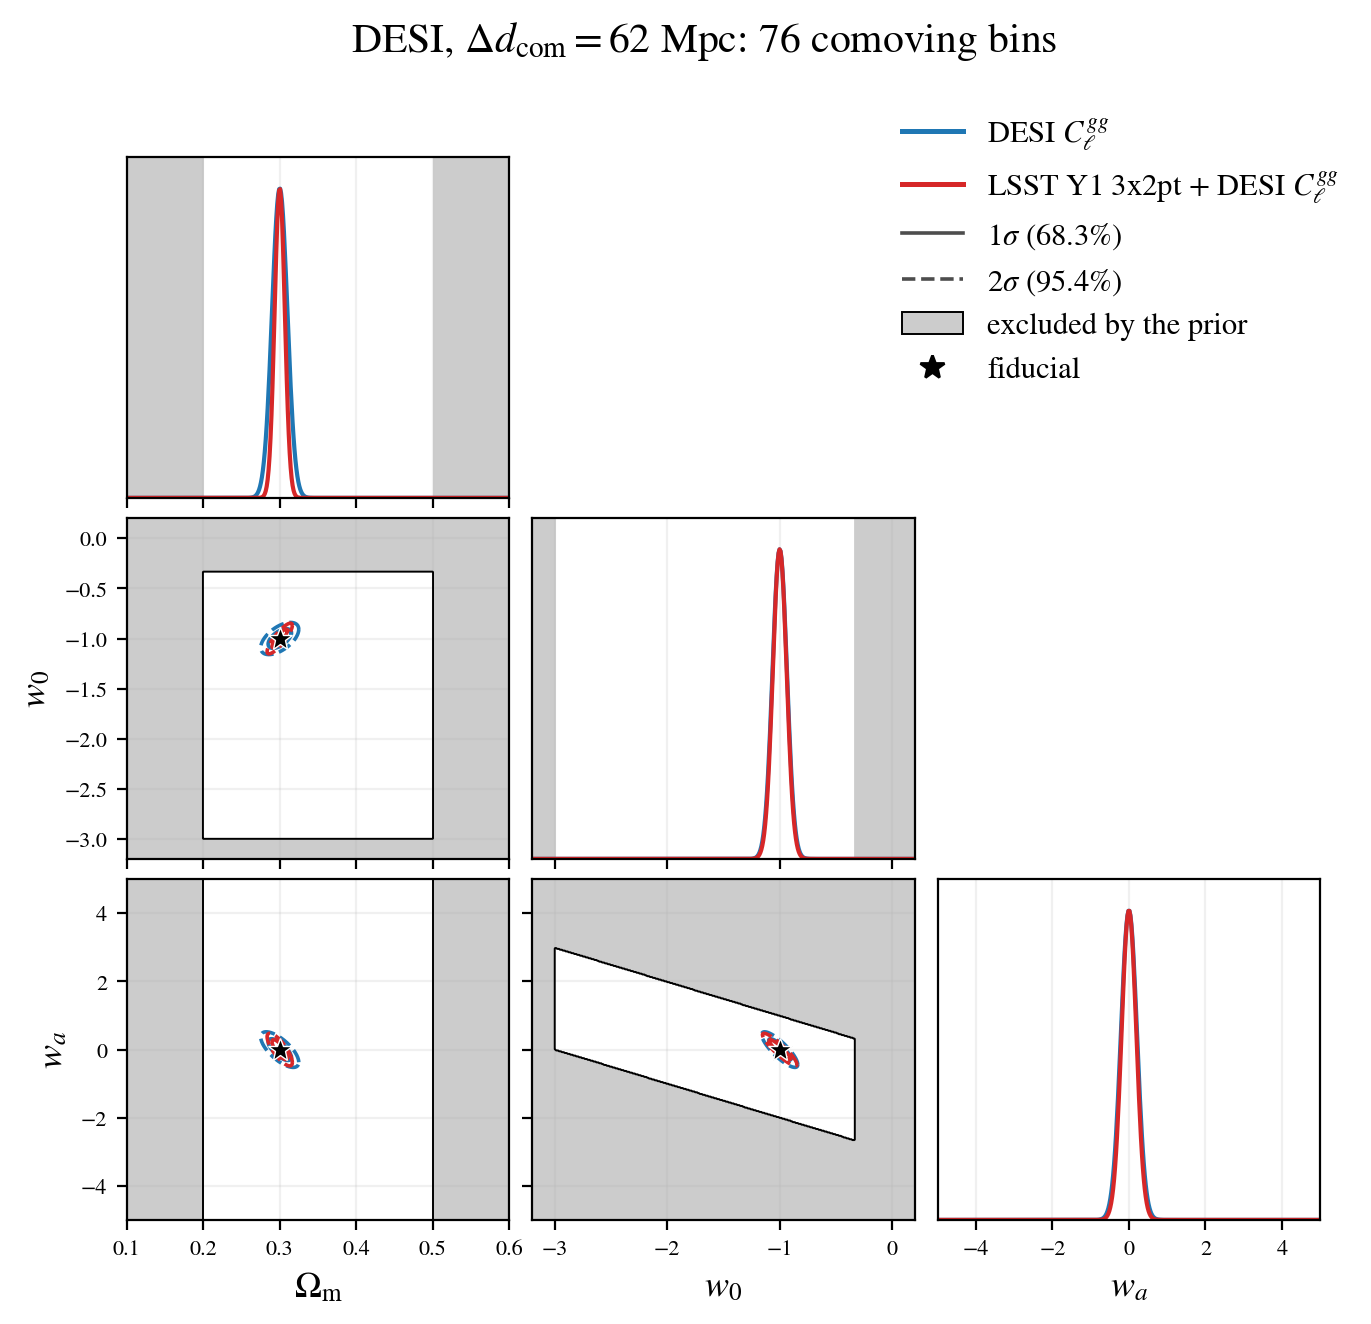

In [23]:
draw_prior_walls('Delta d_com = 62 Mpc')

### $\Delta z = 0.02$

90 bins of width $\Delta z = 0.02$, at accuracy boost 1 with a combined
$\chi$-grid factor of 64. The matrix is cached in
`chains/EXAMPLE_EVALUATE2_FISHER_AB1.pkl`; a first run without the cache builds it
in about 65 minutes on a laptop with 4 threads. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.36, far inside the
  cut at 8;
- no $2\sigma$ contour of DESI alone or of LSST Y1 3x2pt + DESI $C_\ell^{gg}$
  touches a prior wall;
- DESI alone reaches $\sigma(\Omega_m) = 0.0104$, $\sigma(w_0) = 0.063$ and
  $\sigma(w_a) = 0.206$, with FoM$(w_0, w_a) = 126$; the combination tightens
  them to 0.0066, 0.060 and 0.187, with FoM $= 198$. The errors shrink as the
  binning gets finer, and this layout and $\Delta d_\mathrm{com} = 62$ Mpc agree to about 7%.

Here too the bias-bias $2\sigma$ ellipses of the amplitude-cut triangle are too
small to see at the plotted box ranges: only the fiducial stars show.

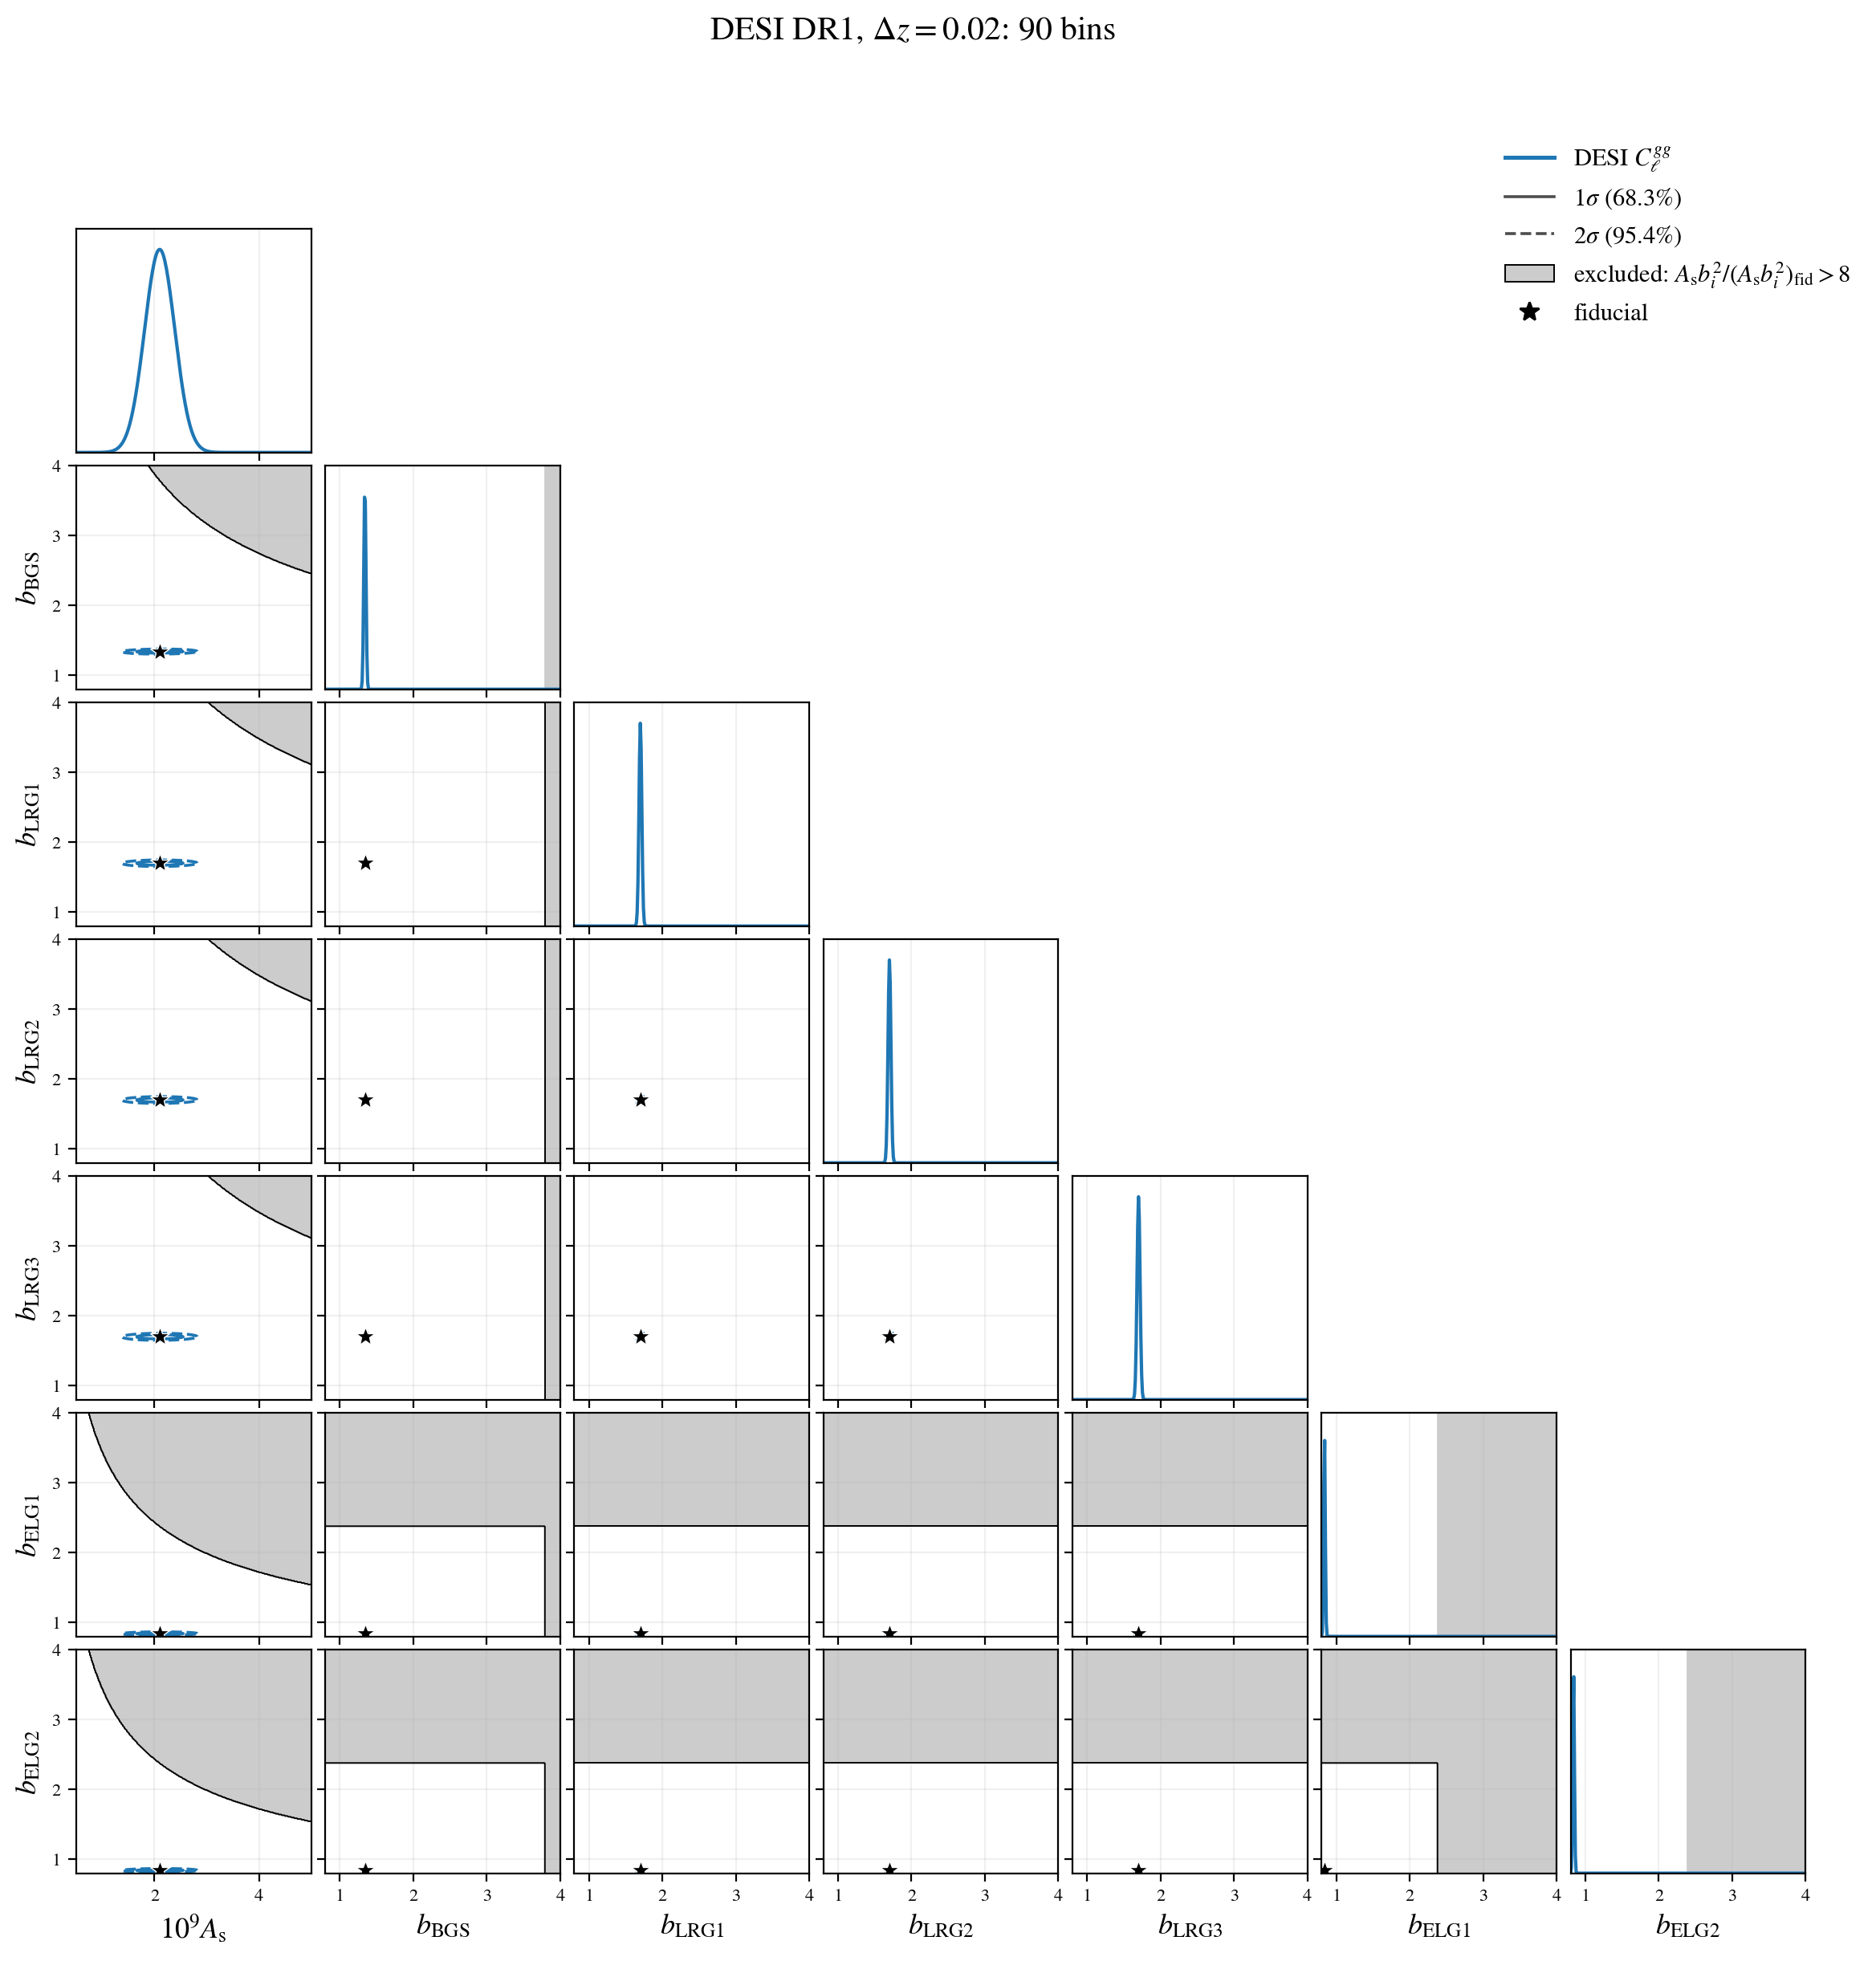

In [24]:
draw_amplitude_cut('Delta z = 0.02')

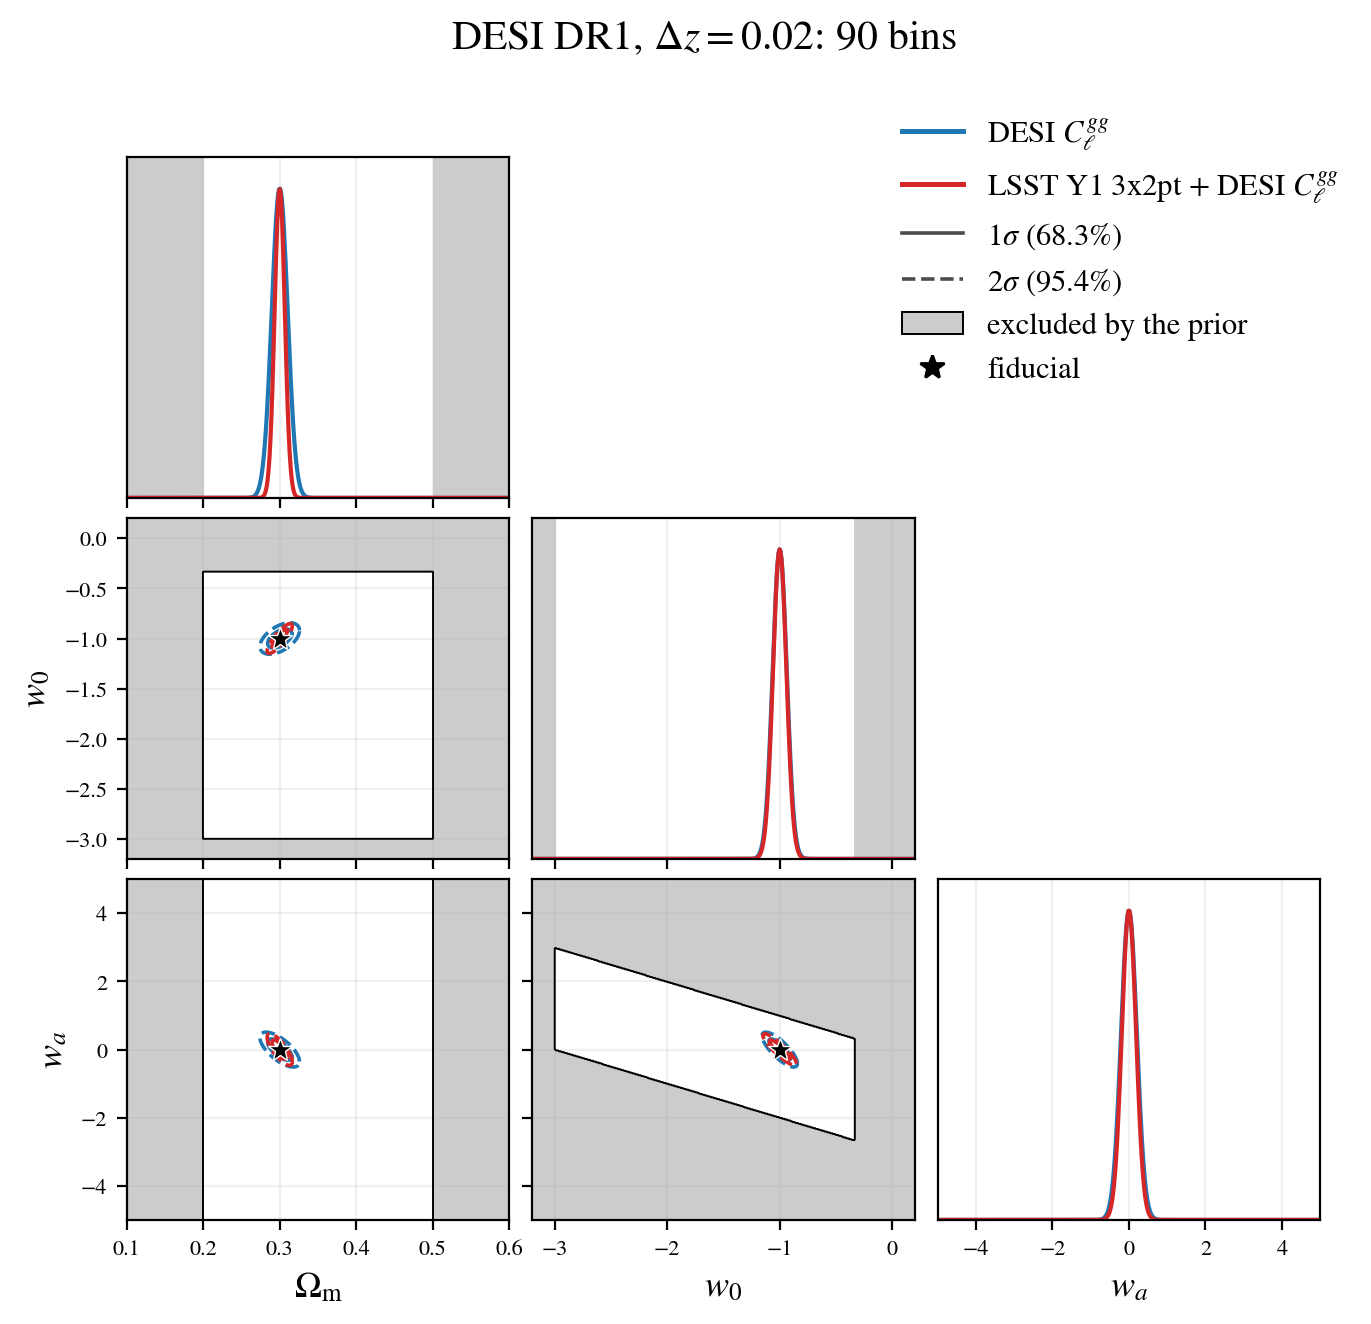

In [25]:
draw_prior_walls('Delta z = 0.02')

### $\Delta z = 0.05$

36 bins of width $\Delta z = 0.05$, computed with the $\chi$-grid override
`nonlimber_accuracyboost: 32` of `LAYOUT_FISHER_OVERRIDES` (a derivative needs a
denser grid than the 16 the likelihood ships). Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.54, far inside the
  cut at 8;
- no $2\sigma$ contour of DESI alone or of LSST Y1 3x2pt + DESI $C_\ell^{gg}$
  touches a prior wall: the DESI $2\sigma$ ranges
  are $\Omega_m$ 0.254-0.346, $w_0$ up to $-0.66$ and $w_0 + w_a$ from $-1.81$ to
  $-0.19$;
- DESI alone reaches $\sigma(\Omega_m) = 0.0186$, $\sigma(w_0) = 0.138$ and
  $\sigma(w_a) = 0.437$, with FoM$(w_0, w_a) = 32$; the combination reaches
  FoM $= 72.5$.

Here too the bias-bias $2\sigma$ ellipses of the amplitude-cut triangle are too
small to see at the plotted box ranges: only the fiducial stars show.

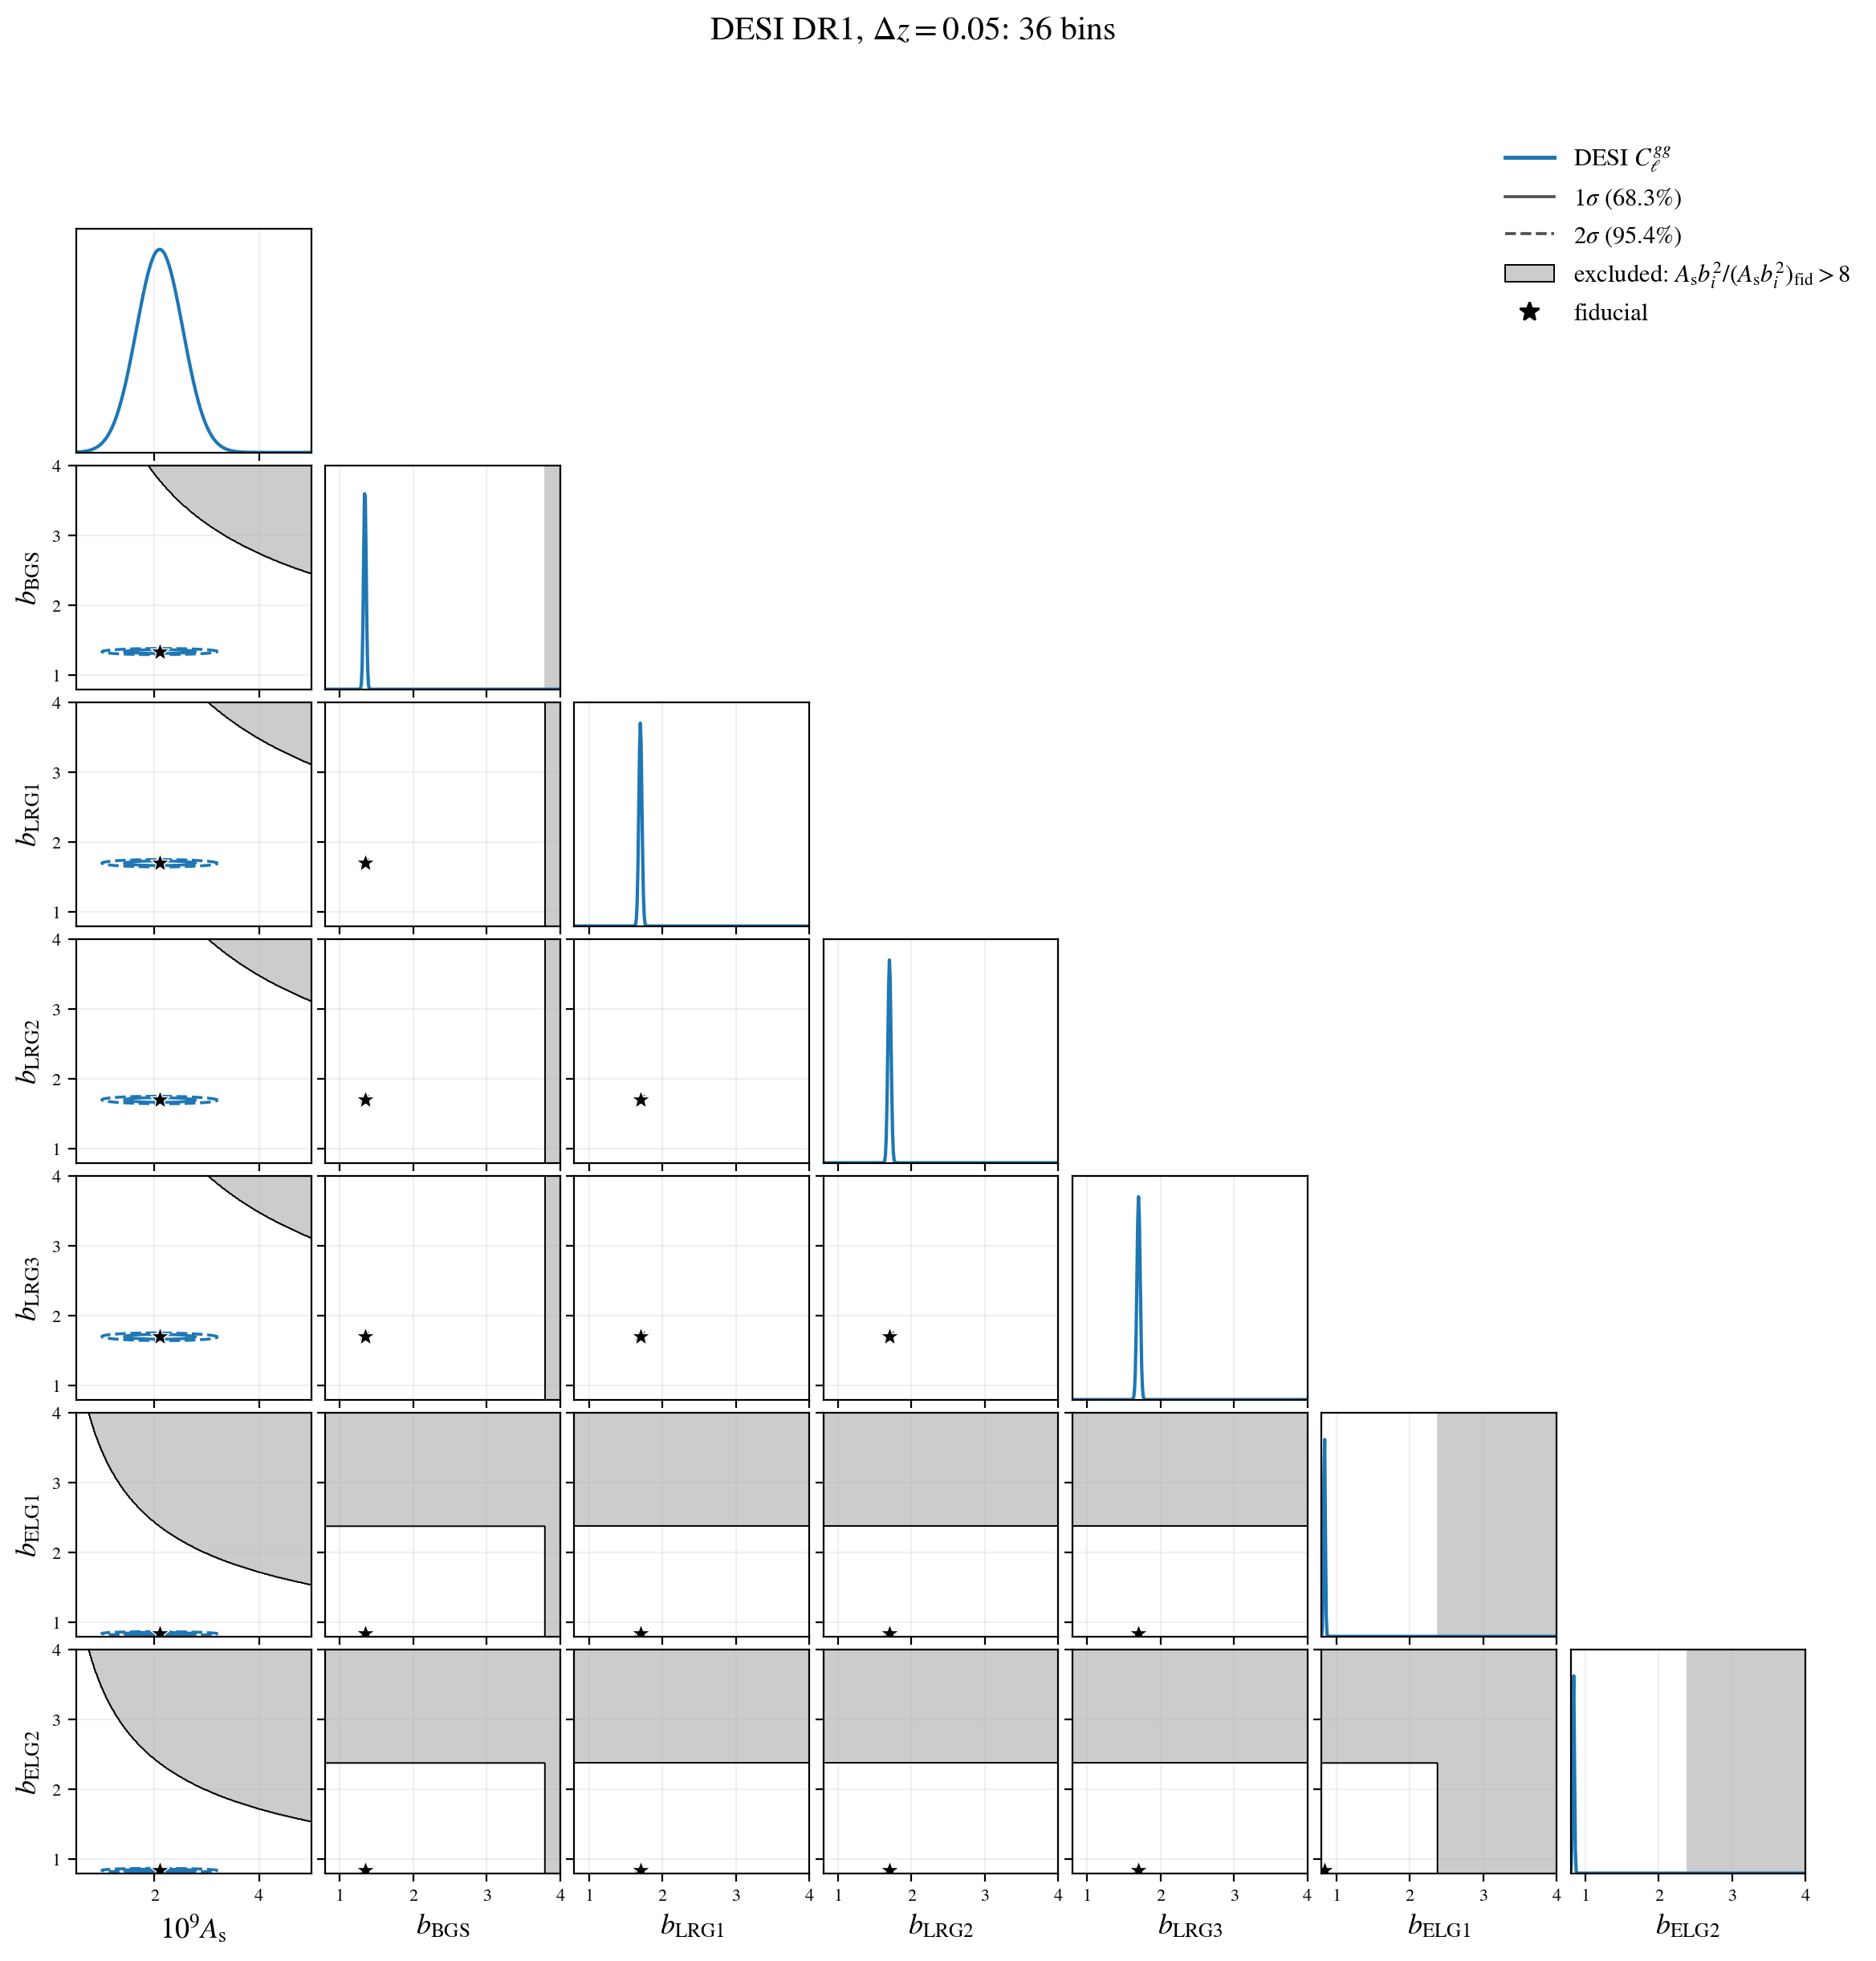

In [26]:
draw_amplitude_cut('Delta z = 0.05')

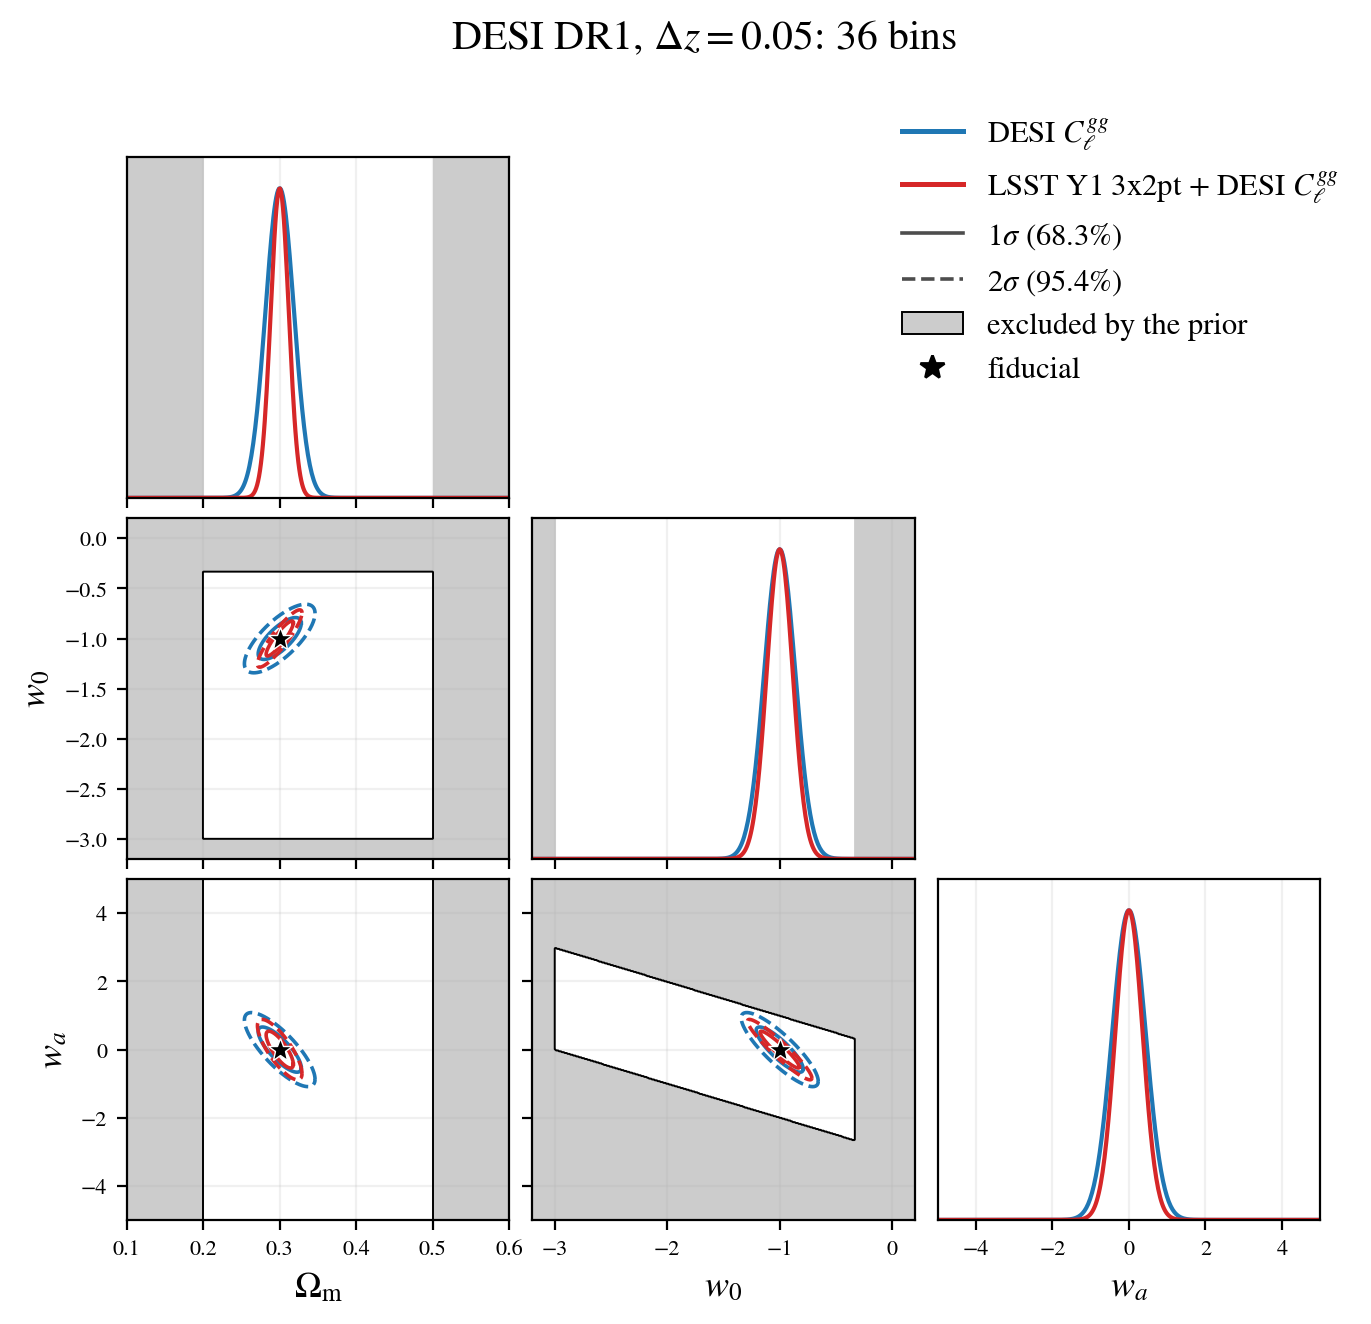

In [27]:
draw_prior_walls('Delta z = 0.05')

### $\Delta z = 0.2$

The ten wide bins of the main forecast; the matrices are those of section 3, at the
overall accuracy boost `ACCURACY_BOOST` = 3 that `fm.boost_accuracy` splits between
CAMB and cosmolike. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 2.11, still far
  inside the cut at 8;
- the DESI-alone $2\sigma$ contours cross the $w_0 = -1/3$ wall and both $w_0 + w_a$
  walls ($w_0 + w_a$ spans $-3.11$ to $1.11$): on these wide bins DESI clustering
  alone is partly prior-bounded in the $w_0$ - $w_a$ plane;
- the $2\sigma$ contour of LSST Y1 3x2pt + DESI $C_\ell^{gg}$ crosses only the
  $w_0 + w_a = -0.01$ wall, reaching
  0.10, and $\Omega_m$ stays inside $[0.2, 0.5]$ for both probes;
- FoM$(w_0, w_a)$: DESI alone 5.7, the combination 32.2.

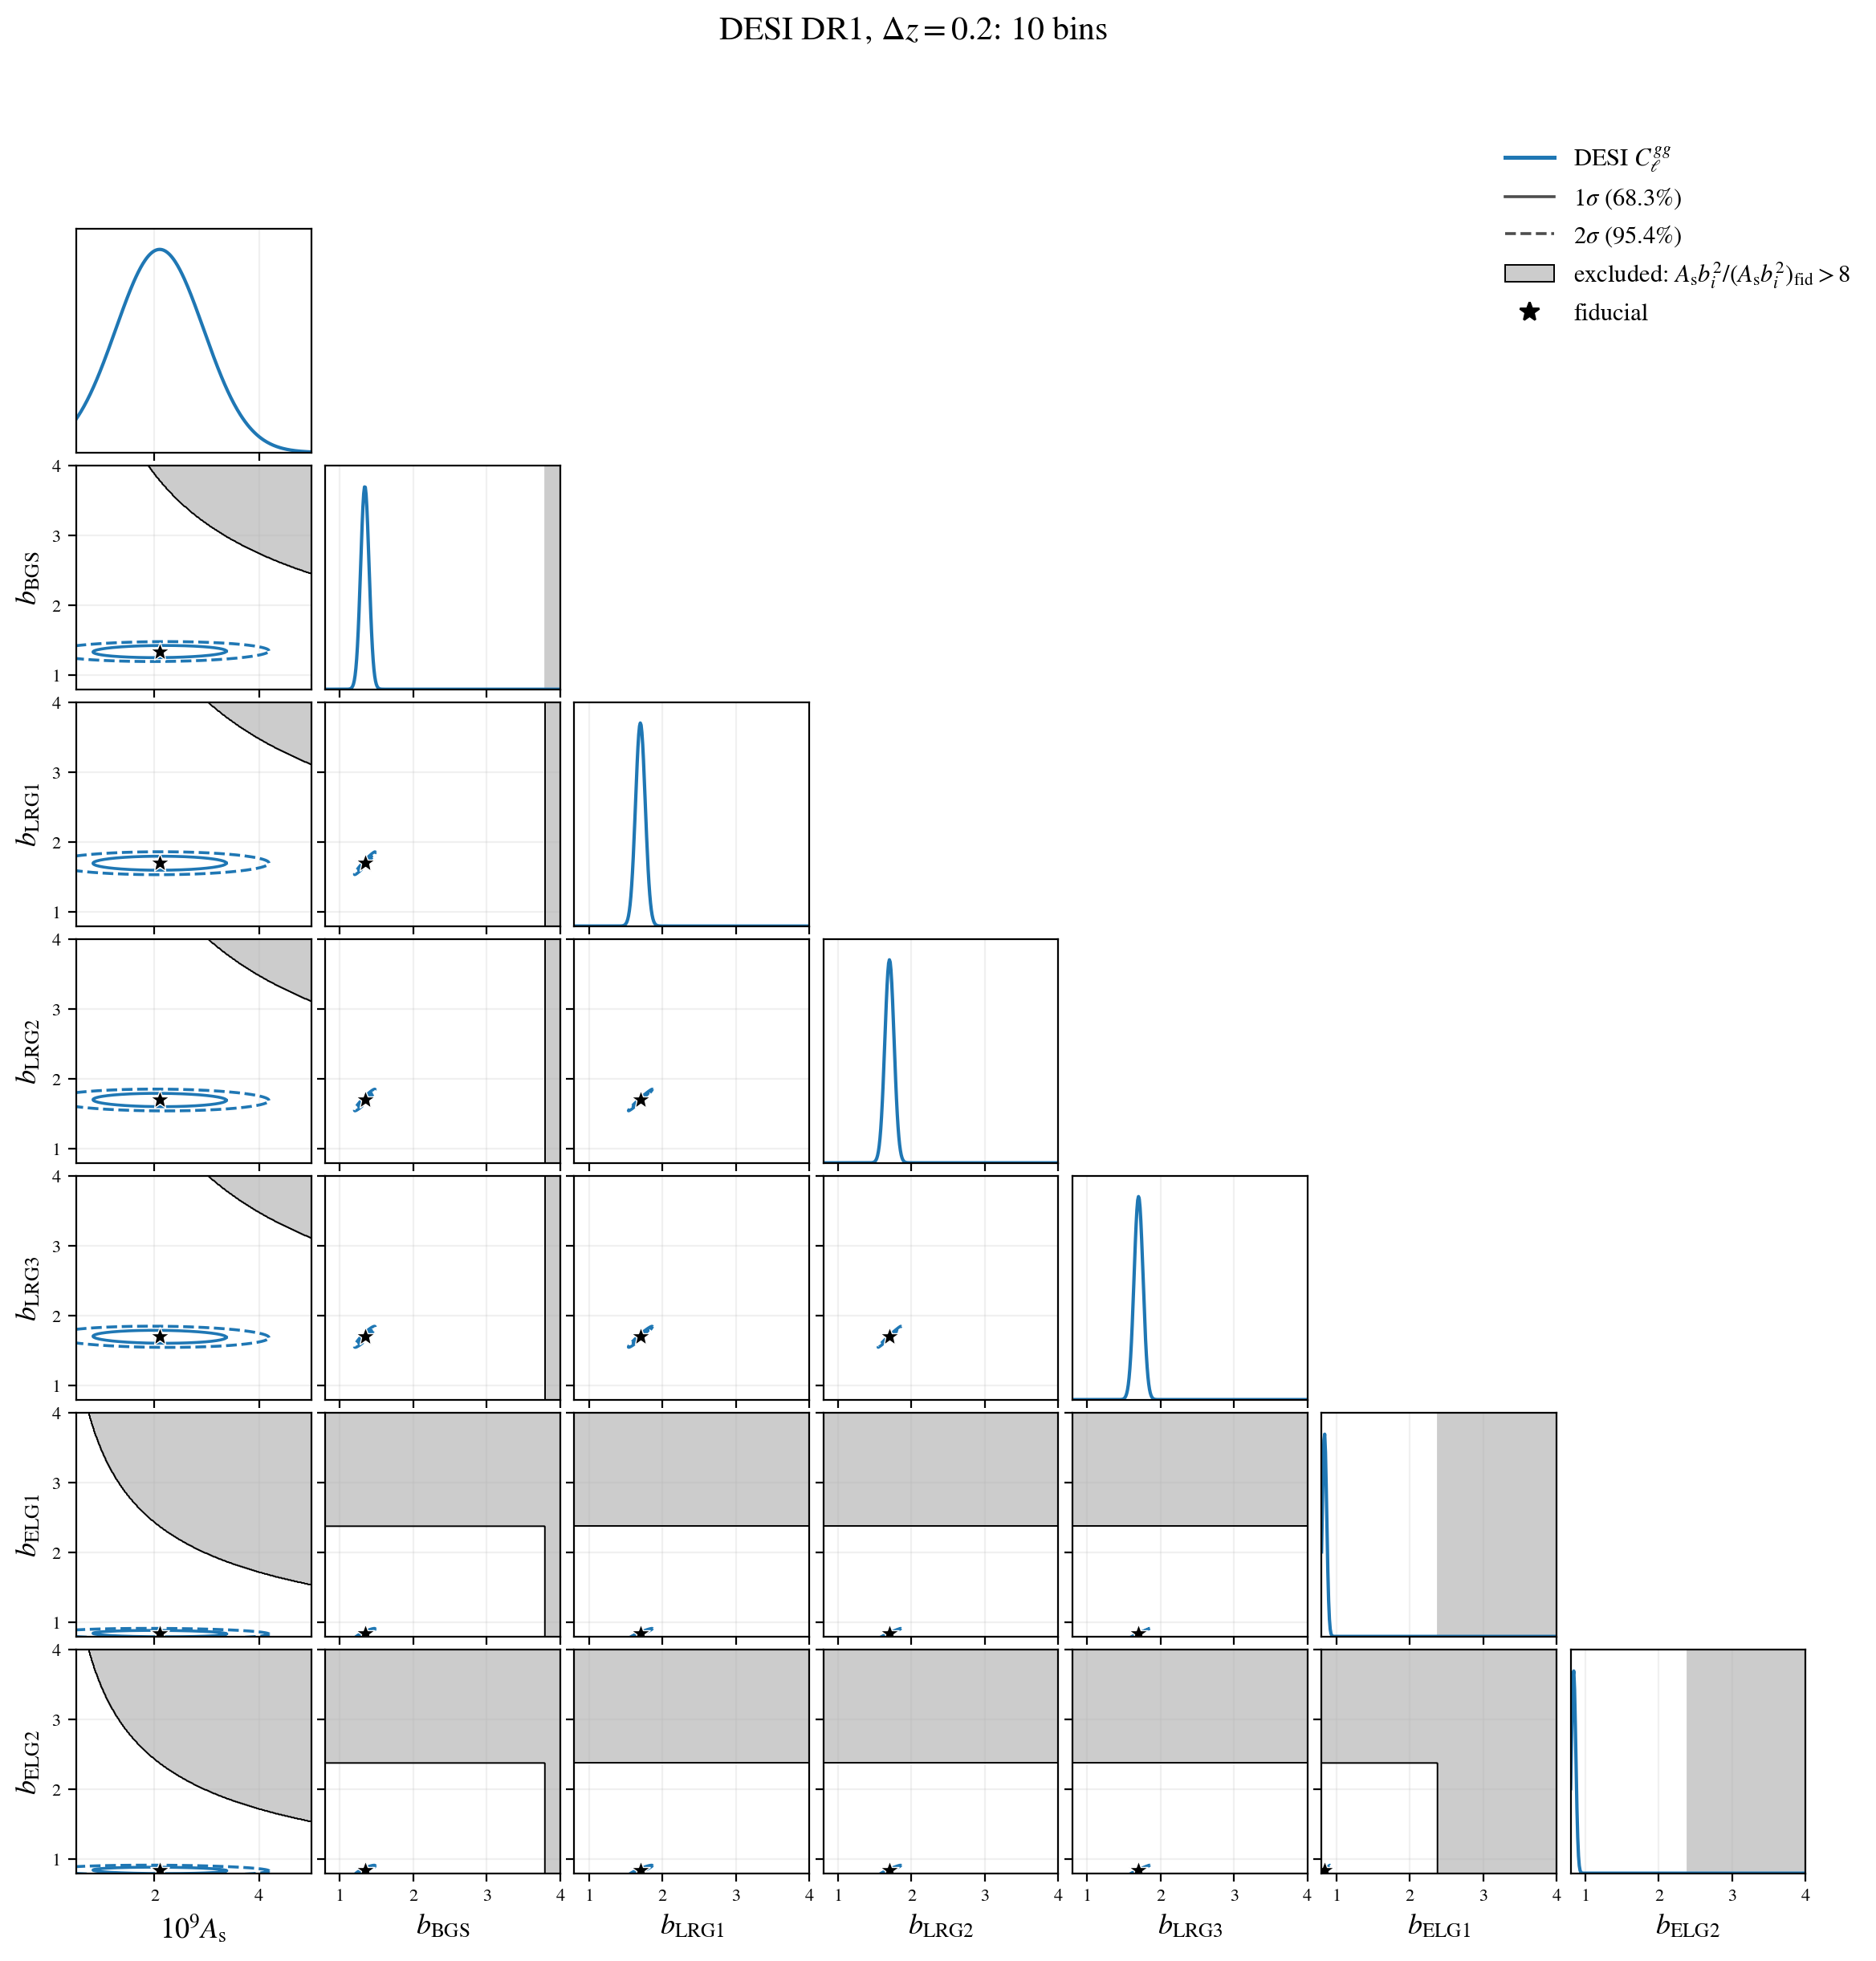

In [28]:
draw_amplitude_cut('Delta z = 0.2')

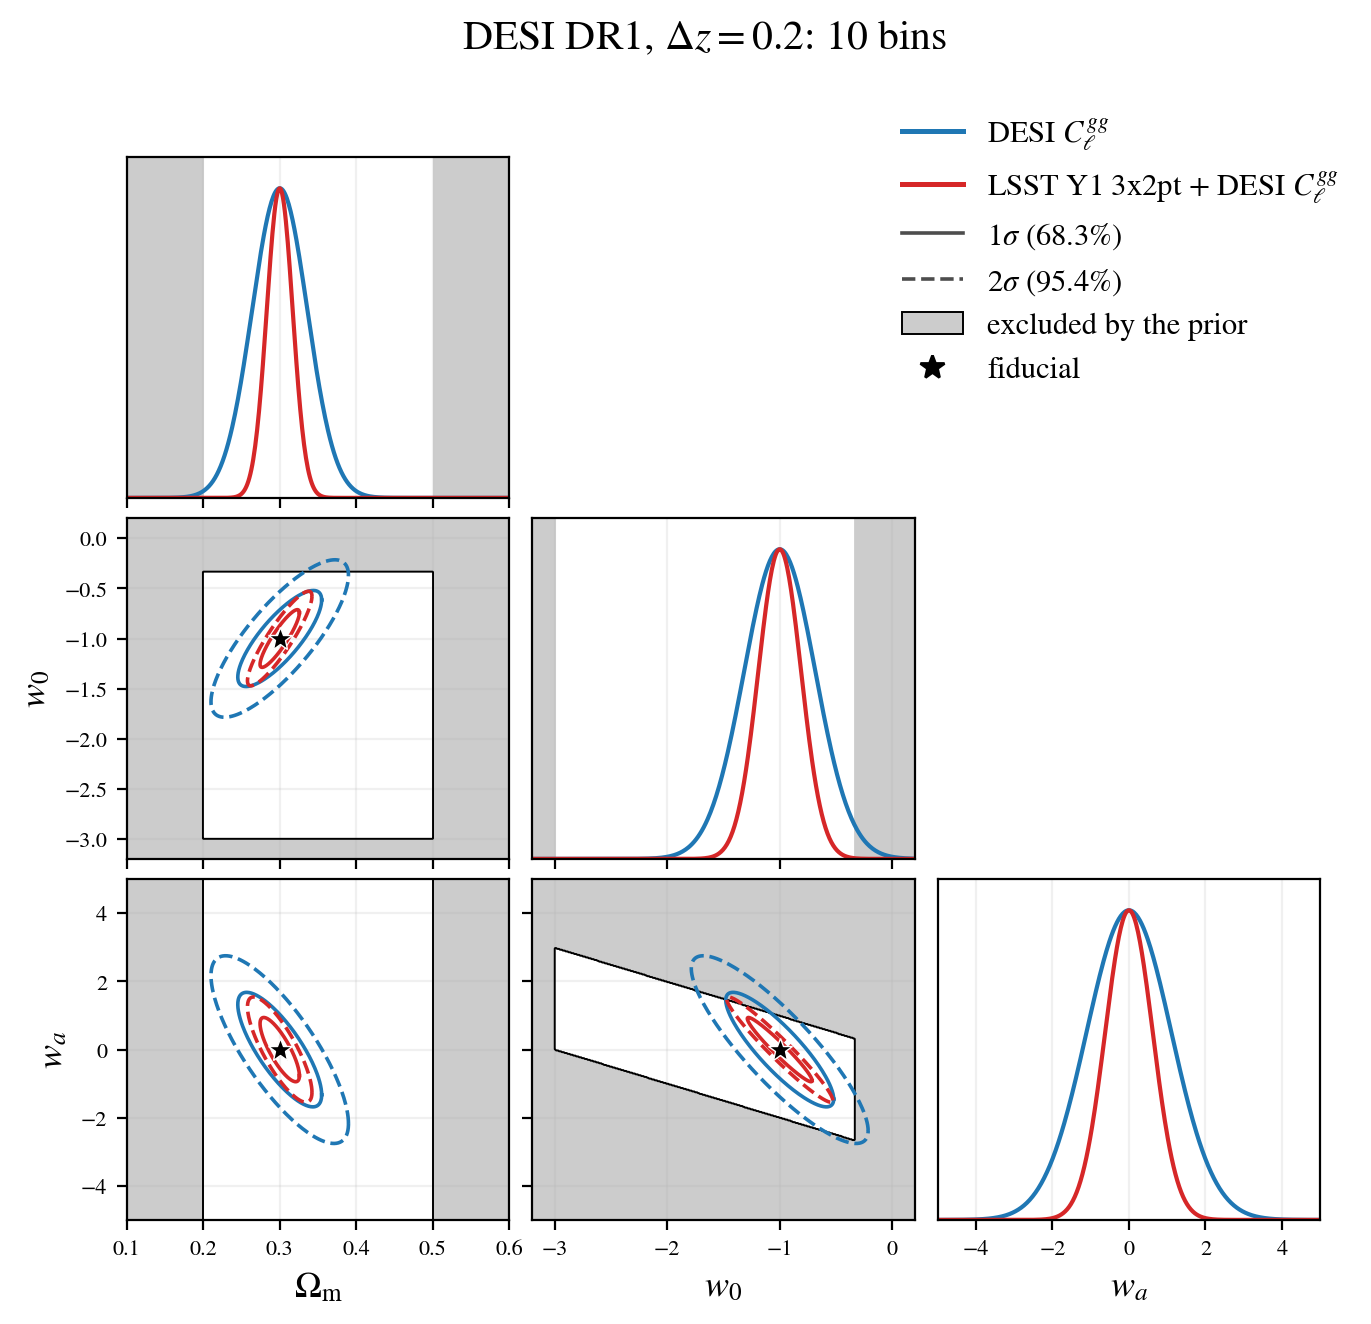

In [29]:
draw_prior_walls('Delta z = 0.2')

### The figure of merit against the scale cut

**Preliminary: linear bias only.** The galaxy model is linear bias times the
nonlinear matter power spectrum; the FoM values of this subsection are a
preliminary read of the information content until the higher-order bias model
is in place, and the absolute values also carry the covariance mismatch of
section 9.

A scale cut drops the small scales the model cannot be trusted to predict. The
cut here is the non-Limber UV-fraction scale cut, following
arXiv:2603.13031. Each band power $C_\ell$ is split in two by a step on
the 3D power spectrum:
$C_\ell^\mathrm{IR}$ is computed with $P(k)$ multiplied by a step that keeps
only $k \le k_\mathrm{max}/D(z)$, and $C_\ell^\mathrm{UV} = C_\ell -
C_\ell^\mathrm{IR}$ is the rest. Here $D(z)$ is the linear growth factor,
normalized to $D(0) = 1$, and $k_\mathrm{max}$ is quoted in $h$ Mpc$^{-1}$ at
$z = 0$. A band is kept while its UV fraction stays below $\alpha$,

$$\frac{|C_\ell^\mathrm{UV}|}{|C_\ell^\mathrm{UV}| + |C_\ell^\mathrm{IR}|}
< \alpha, \qquad \alpha = 0.05,$$

the paper's baseline (it also uses 0.01).

Why divide by the growth factor? Nonlinear structure forms late: at redshift
$z$ the density fluctuations are smaller than today's by $D(z)$, so the scale
where linear bias and perturbation theory degrade sits at a higher $k$ than at
$z = 0$. Cutting at $k_\mathrm{max}/D(z)$ keeps a roughly constant degree of
nonlinearity at every redshift, instead of a fixed comoving scale.

Because the criterion is a step on the power spectrum, not a relation between
$\ell$ and $k$, it needs no Limber approximation: the step multiplies $P(k)$
inside every $C_\ell^{gg}$ engine of the compiled code - the Limber integral,
the FKEM split and the low-rank non-Limber engine the DESI layouts use. That
is decisive for thin bins. A bin of comoving width $\Delta\chi$ collects
radial modes up to $k_\parallel \sim 2\pi/\Delta\chi$, and for the thin
layouts those lie beyond the cut at every multipole, so even the lowest bands
have a large UV part. The Limber relation
$\ell \le k_\mathrm{max}\,\chi(\bar z) - 1/2$ counts only the transverse
modes and misses this completely: a Limber-based cut would keep low-$\ell$
bands whose value the model does not actually predict.

The cross spectra of adjacent thin bins are the sharpest case. Their signal
comes mostly from galaxy pairs that straddle the shared bin edge - close
pairs, small radial separations, large $k_\parallel$ - so they are strongly
UV-dominated and lose most of their bands at every $k_\mathrm{max}$ of the
scan.

The kept bands of a spectrum form a prefix in $\ell$: every band up to the
first that fails the criterion. Where the UV fraction is not monotonic in
$k_\mathrm{max}$, each prefix is shortened to the prefix of the next larger
$k_\mathrm{max}$, so the cut can only tighten as $k_\mathrm{max}$ falls.

The shipped masks still apply on top of the cut: the covariance files have
entries only inside them, and they stop every bin at the fixed
$k = 0.1185$ Mpc$^{-1}$ ($\approx 0.176\,h$ Mpc$^{-1}$), with no growth
scaling. The fit therefore uses (shipped mask) AND (UV-fraction cut), and the
shipped mask caps every band count and every curve below.

The next cell computes the cuts of every layout with the compiled interface
(`gg_scale_cuts_tomo`) and counts the kept band powers; each cell of its table
is autos / cross pairs. Down a column the counts grow with $k_\mathrm{max}$
until the shipped mask saturates them; across a row the thin layouts keep the
smallest fraction of their bands, the cross pairs most of all. At
$k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$ the $\Delta z = 0.02$ layout keeps
nothing, and the $\Delta d_\mathrm{com} = 62$ Mpc layout keeps only the bins above
$z \approx 0.9$, where the $1/D(z)$ scaling raises the cut the most.

In [30]:
# The non-Limber UV-fraction scale cuts (arXiv:2603.13031) of every DESI layout,
# computed by the compiled interface (gg_scale_cuts_tomo). Each C_gg band
# power splits into the part sourced by modes k <= k_max/D(z) (IR) and the
# rest (UV): the step multiplies the 3D power spectrum inside every gg
# engine, Limber and non-Limber alike, so a thin bin's radial modes count.
# A band is kept while |C_UV|/(|C_UV| + |C_IR|) < ALPHA_UV, and the kept
# bands of each spectrum are a prefix in ell that tightens as k_max falls.
# k_max is quoted in h/Mpc at z = 0.
#
# Each layout's model is built at its Fisher settings (section 4) and
# evaluated at the fiducial point; the cuts are cached, and RECOMPUTE_CUTS
# = True rebuilds them.
KMAX_CUTS = np.round(np.arange(0.05, 0.2501, 0.025), 3)  # h/Mpc at z = 0
ALPHA_UV = 0.05
CUTS_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
              'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl')
RECOMPUTE_CUTS = False


def cut_settings(key):
    '''The model settings of one layout's scale cuts: its Fisher settings.'''
    if key in LAYOUT_FISHER_OVERRIDES:
        overrides = dict(LAYOUT_FISHER_OVERRIDES[key])
        boost = LAYOUT_ACCURACY_BOOST
    else:
        overrides = dict(DESI_FISHER_OVERRIDES)
        boost = 1.0
    return {'yaml': LAYOUTS[key]['yaml'], 'likelihood_overrides': overrides,
            'accuracy_boost': boost, 'kmax': [float(k) for k in KMAX_CUTS],
            'alpha': ALPHA_UV}


def layout_scale_cuts(key):
    '''The UV-fraction scale cuts of one layout at KMAX_CUTS.

    Returns:
      dict of gg_scale_cuts_tomo (rows: the autos, then the cross pairs,
      in the data-vector order of the gg and gg-cross blocks), with numpy
      arrays: 'lmax' (nspec, nk), 'mask' and 'uv_fraction' (nspec, nell,
      nk), 'ell', 'kmax' and 'nautos'.
    '''
    settings = cut_settings(key)
    model = fm.ModelFisher(settings['yaml'], COSMO,
                           likelihood_overrides=settings['likelihood_overrides'],
                           accuracy_boost=settings['accuracy_boost'])
    model.dv()  # the fiducial point sets the interface's cosmology
    cuts = fm.ci.gg_scale_cuts_tomo(np.array(KMAX_CUTS, dtype=float), ALPHA_UV)
    out = {}
    for name in ('kmax', 'ell', 'lmax', 'mask', 'uv_fraction'):
        out[name] = np.array(cuts[name])
    out['nautos'] = int(cuts['nautos'])
    del model
    return out


settings_now = {key: cut_settings(key) for key in LAYOUT_DATASETS}
if RECOMPUTE_CUTS or not os.path.exists(CUTS_CACHE):
    scale_cuts = {}
    for key in LAYOUT_DATASETS:
        start = time.time()
        scale_cuts[key] = layout_scale_cuts(key)
        print(f'{key}: {time.time() - start:.0f} s', flush=True)
    with open(CUTS_CACHE, 'wb') as f:
        pickle.dump({'cuts': scale_cuts, 'settings': settings_now}, f)
else:
    with open(CUTS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] != settings_now:
        raise RuntimeError(f'{CUTS_CACHE} holds other settings: set '
                           'RECOMPUTE_CUTS = True to rebuild it')
    scale_cuts = cached['cuts']


def combined_mask(key, k_index):
    '''The shipped mask AND the UV-fraction cut at KMAX_CUTS[k_index].

    Returns:
      (mask over the full data vector, the layout_covariance dict).
    '''
    cov = layout_covariance(key)
    cuts = scale_cuts[key]
    eq11 = cuts['mask'][:, :, k_index].ravel() > 0
    mask = cov['mask'].copy()
    mask[cov['n_ee']:] &= eq11
    return mask, cov


summary = {}
for key in LAYOUT_DATASETS:
    cov = layout_covariance(key)
    nautos = scale_cuts[key]['nautos']
    nell = len(scale_cuts[key]['ell'])
    split = cov['n_ee'] + nautos*nell
    for m, kmax in enumerate(KMAX_CUTS):
        mask, _ = combined_mask(key, m)
        summary[(key, 'autos')] = summary.get((key, 'autos'), {})
        summary[(key, 'pairs')] = summary.get((key, 'pairs'), {})
        summary[(key, 'autos')][kmax] = int(mask[cov['n_ee']:split].sum())
        summary[(key, 'pairs')][kmax] = int(mask[split:].sum())
    summary[(key, 'autos')]['shipped'] = int(cov['mask'][cov['n_ee']:split].sum())
    summary[(key, 'pairs')]['shipped'] = int(cov['mask'][split:].sum())
print(f'band powers kept (shipped mask AND the non-Limber UV-fraction cut, '
      f'alpha = {ALPHA_UV}); '
      'rows: k_max [h/Mpc at z = 0]')
display(pd.DataFrame(summary))

band powers kept (shipped mask AND the non-Limber UV-fraction cut, alpha = 0.05); rows: k_max [h/Mpc at z = 0]


Delta d_com = 62 Mpc       Delta z = 0.02       Delta z = 0.05        \
                        autos pairs          autos pairs          autos pairs   
0.05                      167    74              0     0            367    70   
0.075                     903   750            904   952            663   184   
0.1                      1585  1124           1928  2471            945   269   
0.125                    2049  1432           2755  3062           1148   522   
0.15                     2220  2038           2982  3118           1195   623   
0.175                    2268  2657           3016  3557           1204  1091   
0.2                      2276  2889           3016  4496           1205  1240   
0.225                    2276  2982           3016  4605           1205  1558   
0.25                     2276  3025           3016  4605           1205  1560   
 shipped                 2276  3033           3016  4605           1205  1777   

         Delta z = 0.2        
                 autos pairs  
0.05               122    44  
0.075              198    82  
0.1                267   111  
0.125              307   138  
0.15               319   156  
0.175              325   238  
0.2                325   306  
0.225              326   341  
0.25               327   415  
 shipped           329   415

The figure below turns the same cuts into a per-bin
$\ell_\mathrm{max}$: for every bin's auto spectrum, the highest multipole
the criterion keeps, against the bin's mean redshift. One panel per layout,
one color per $k_\mathrm{max}$, one marker per sample (BGS, LRG, ELG); the
black dashed line is the shipped mask's own $\ell_\mathrm{max}$, which caps
every colored curve because the covariance has no entries beyond it. A bin
with no band left sits at $\ell_\mathrm{max} = 0$.

Two trends to read. First, $\ell_\mathrm{max}$ rises with redshift, for two
compounding reasons: a fixed comoving scale subtends a smaller angle at a
larger distance, so it sits at a higher $\ell$, and the cut itself grows as
$k_\mathrm{max}/D(z)$. Second, on the thin layouts the curves sit far below
where the Limber relation $\ell \le k_\mathrm{max}\,\chi(\bar z) - 1/2$
would put them: the radial modes of a thin bin dominate the UV part already
at low $\ell$, so the criterion removes bands that relation would keep.

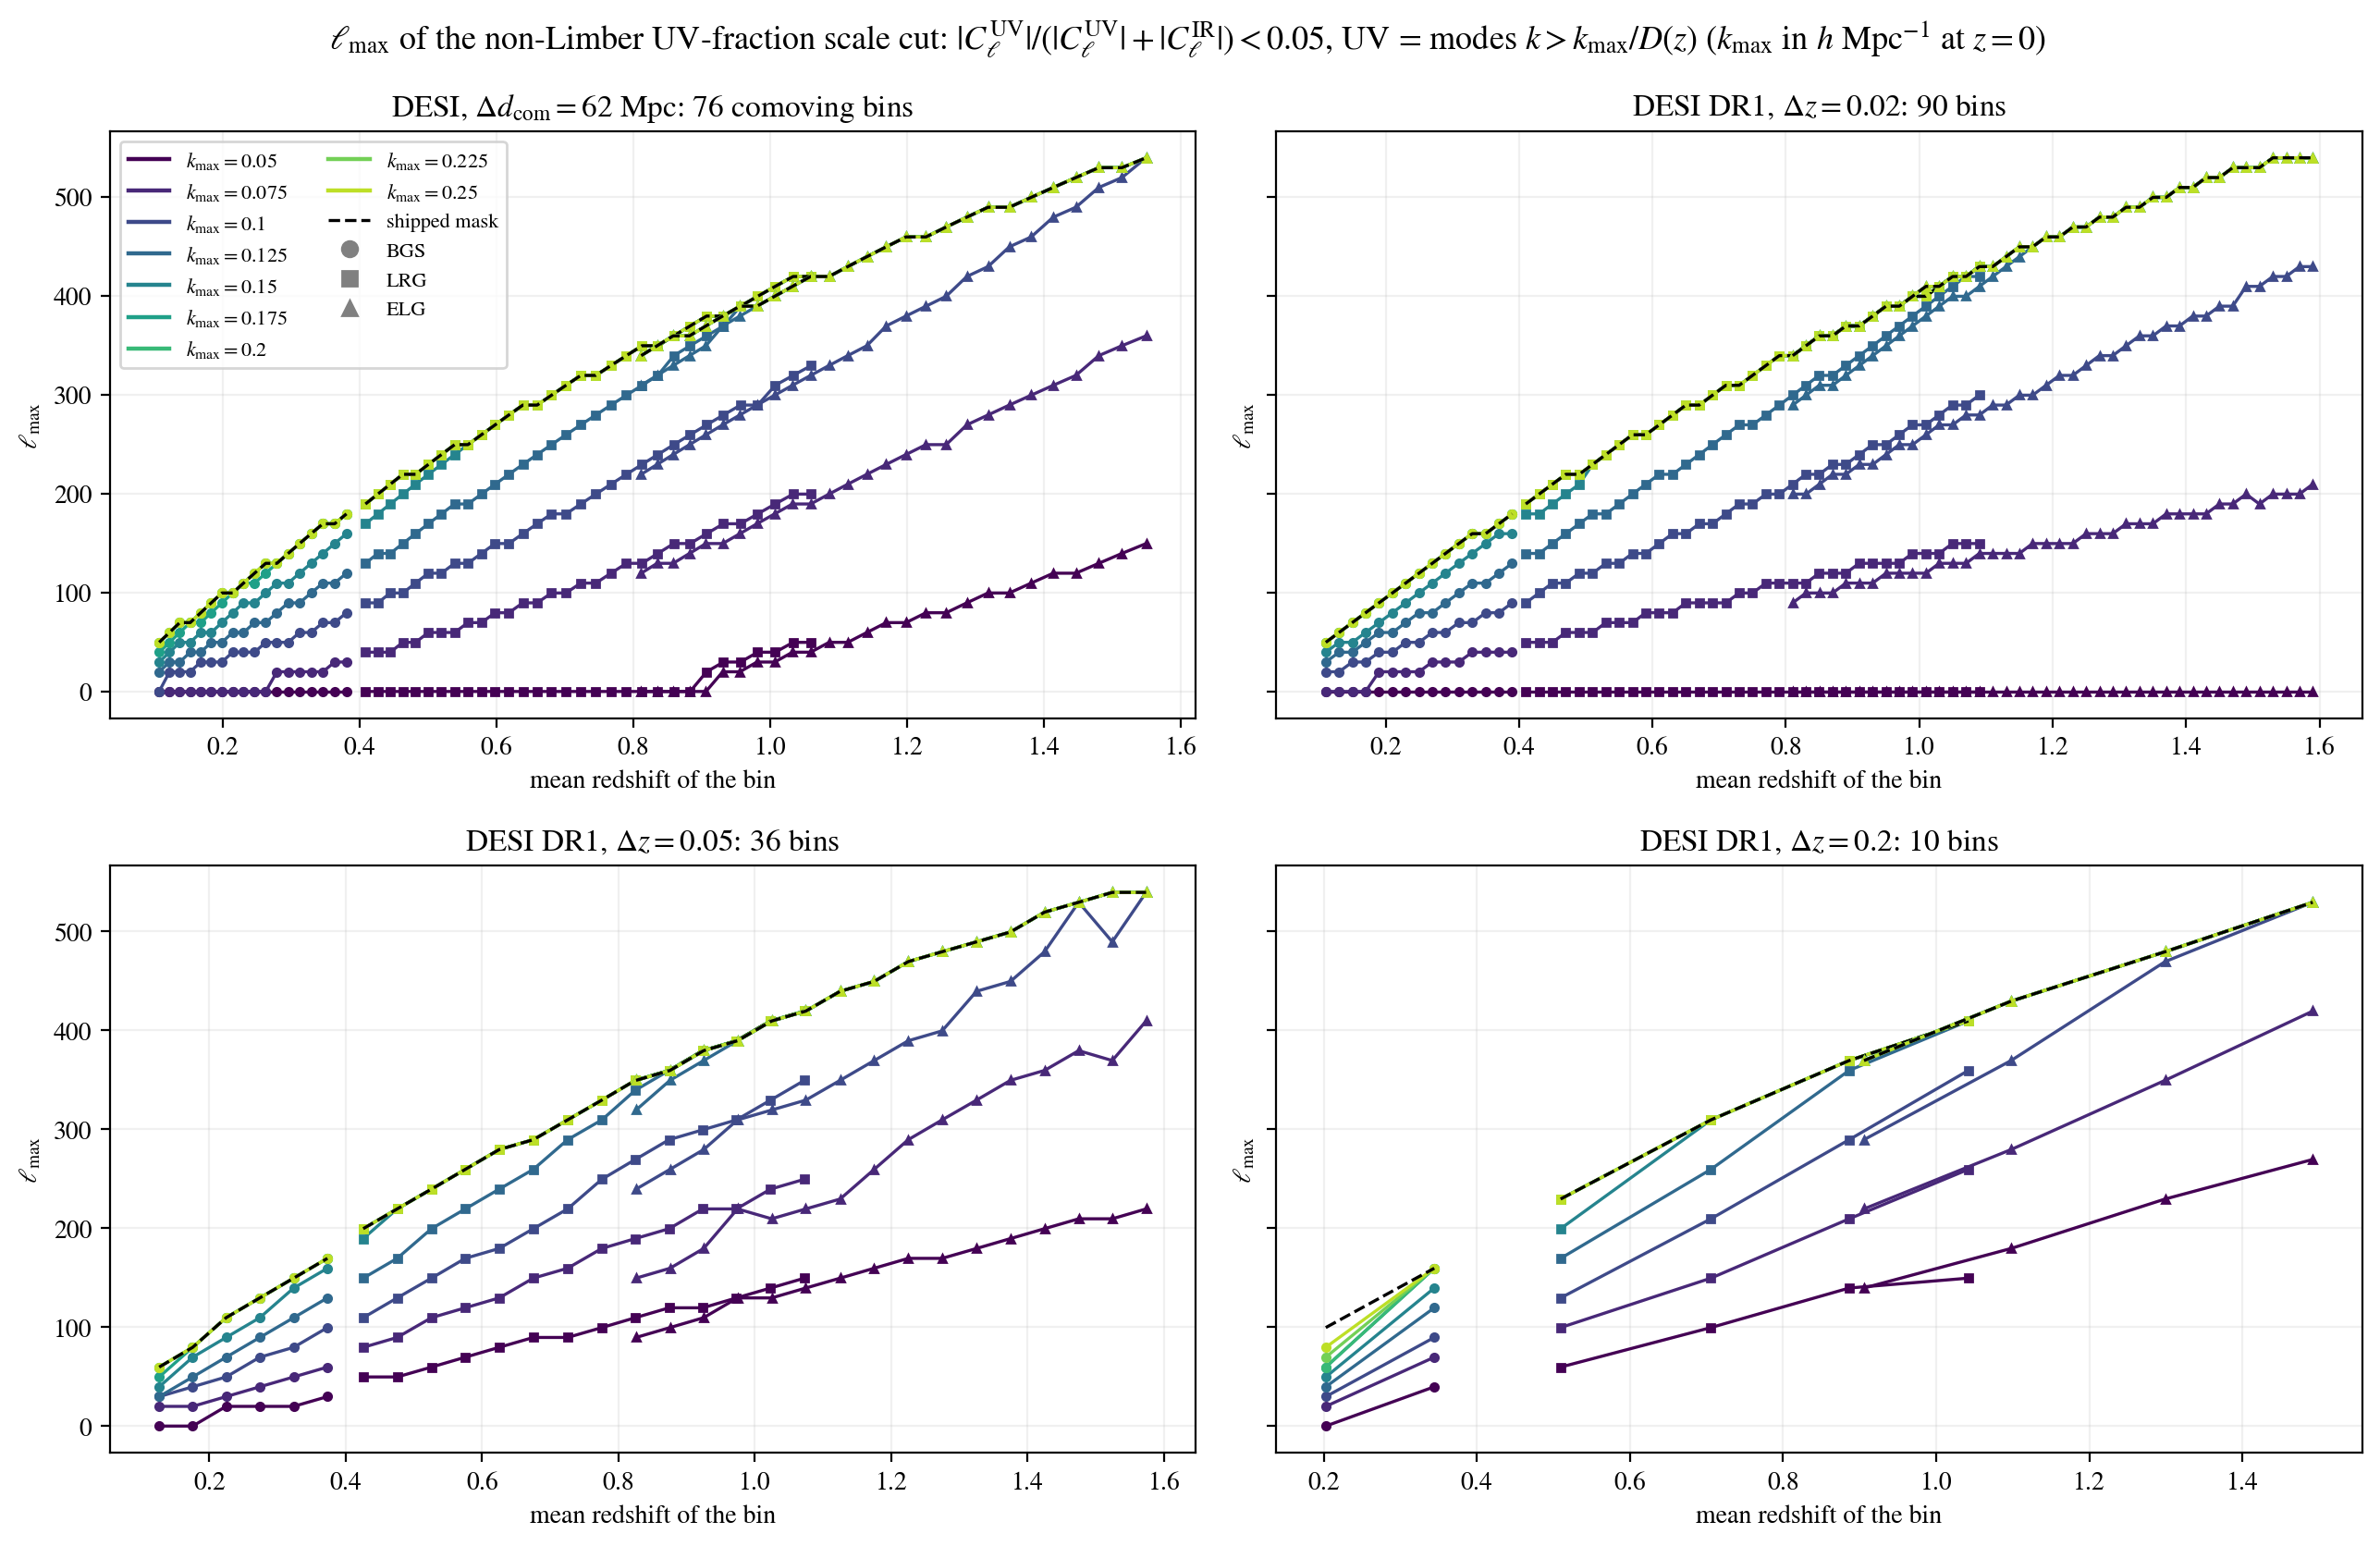

In [31]:
# ell_max of every bin's auto spectrum against the bin's mean redshift:
# one panel per layout, one color per k_max of KMAX_CUTS, and the shipped
# mask's own ell_max (the covariance has no entries beyond it, so it caps
# every cut). The samples overlap in redshift and differ in bias, so each
# sample gets its own line and marker. A bin with no band left sits at
# ell_max = 0.
from matplotlib import cm
from matplotlib.lines import Line2D

SAMPLE_MARKERS = {'bgs': 'o', 'lrg': 's', 'elg': '^'}

colors = cm.viridis(np.linspace(0.0, 0.9, len(KMAX_CUTS)))
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for ax, key in zip(axes.ravel(), LAYOUT_DATASETS):
    cuts = scale_cuts[key]
    cov = layout_covariance(key)
    nautos = cuts['nautos']
    ells = cuts['ell']
    zbar = np.array([float(row[4]) for row in cov['bins']])
    sample = np.array([row[1].lower() for row in cov['bins']])
    shipped = cov['mask'][cov['n_ee']:cov['n_ee'] + nautos*len(ells)]
    shipped = shipped.reshape(nautos, len(ells))
    shipped_lmax = np.array([ells[row].max() if row.any() else 0.0 for row in shipped])
    for s, marker in SAMPLE_MARKERS.items():
        rows = np.where(sample == s)[0]
        if len(rows) == 0:
            continue
        rows = rows[np.argsort(zbar[rows])]
        for m, kmax in enumerate(KMAX_CUTS):
            lmax = np.minimum(cuts['lmax'][rows, m], shipped_lmax[rows])
            ax.plot(zbar[rows], lmax, color=colors[m], marker=marker, ms=3,
                    lw=1.2)
        ax.plot(zbar[rows], shipped_lmax[rows], color='black', ls='--', lw=1.2)
    ax.set_title(LAYOUTS[key]['title'])
    ax.set_xlabel(r'mean redshift of the bin')
    ax.set_ylabel(r'$\ell_\mathrm{max}$')
handles = []
for m, kmax in enumerate(KMAX_CUTS):
    handles.append(Line2D([], [], color=colors[m], lw=1.6,
                          label=f'$k_{{\\max}} = {kmax:g}$'))
handles.append(Line2D([], [], color='black', ls='--', lw=1.2,
                      label='shipped mask'))
for s, marker in SAMPLE_MARKERS.items():
    handles.append(Line2D([], [], color='gray', marker=marker, ls='none',
                          label=s.upper()))
axes[0][0].legend(handles=handles, fontsize=8, ncol=2)
fig.suptitle(rf'$\ell_\mathrm{{max}}$ of the non-Limber UV-fraction scale cut: '
             rf'$|C_\ell^\mathrm{{UV}}|/(|C_\ell^\mathrm{{UV}}| + |C_\ell^\mathrm{{IR}}|) < {ALPHA_UV}$, '
             r'UV = modes $k > k_\mathrm{max}/D(z)$ '
             r'($k_\mathrm{max}$ in $h$ Mpc$^{-1}$ at $z = 0$)', fontsize=13)
fig.tight_layout()
plt.show()

The last step rebuilds the Fisher matrix of DESI $C_\ell^{gg}$
alone at each $k_\mathrm{max}$, from the cached derivatives and the inverse
of the kept block of the covariance - the cut removes rows and columns of the
covariance before inverting it, which is not the same as truncating the full
inverse - keeping the Gaussian priors on the velocity dispersions. A
galaxy-bias parameter whose bins lost every band has a flat prior and no
data, so its Fisher row is zero: the fit drops it, and the cosmology is
unchanged. When no band power survives at all there is no
$w_0$ - $w_a$ constraint left, so the figure of merit is reported as 0:
$\Delta z = 0.02$ at $k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$.

Read the figure as information against scale. The model is linear galaxy bias
times the nonlinear matter power, and that model is accurate only up to about
$k = 0.08$-$0.12\,h$ Mpc$^{-1}$; on smaller scales the neglected
second-order bias, counterterms and stochastic terms matter, and holding them
at zero turns modeling error into apparent information. The left part of each
curve is therefore the defensible region for this model; using the full
shipped range requires the higher-order galaxy bias model, the next modeling
step. Inside the defensible window, at $k_\mathrm{max} = 0.1\,h$
Mpc$^{-1}$, the FoM is 54.9 on $\Delta d_\mathrm{com} = 62$ Mpc, 57.0 on $\Delta z = 0.02$, 14.2 on
$\Delta z = 0.05$ and 3.06 on $\Delta z = 0.2$. The figure stops at
$k_\mathrm{max} = 0.2\,h$ Mpc$^{-1}$, where the FoM reaches 132, 125, 30.9 and
5.19; the table above carries the values at 0.25 and at the shipped masks
(135, 126, 32.0 and 5.67). The $y$ axis is logarithmic, from 0.3
to 300; a FoM of 0 has no place on a log axis, so the $\Delta z = 0.02$ point at
$k_\mathrm{max} = 0.05\,h$ Mpc$^{-1}$ is left off its curve and marked "no band
left". The dashed gray line is a fixed reference, not cut in $k_\mathrm{max}$:
LSST Y1 3x2pt at FoM$(w_0, w_a) = 17.3$, the lsst_y1 project's real-space Fisher
forecast of the SRD Y1 setup with that project's own scale cuts (section 18 of
its EXAMPLE_EVALUATE2.ipynb reports 17.26; its fiducial has $w_0 = -0.9$ against
$-1$ here, and this notebook's own LSST Y1 3x2pt in band powers gives 17.4 in
section 4, so the reference is consistent). DESI $C_\ell^{gg}$ alone passes it
near $k_\mathrm{max} = 0.075\,h$ Mpc$^{-1}$ on the two finest layouts (FoM 32.9
and 19.9 there); $\Delta z = 0.05$, at 8.29 there, stays below it until about
$k_\mathrm{max} = 0.11\,h$ Mpc$^{-1}$, and $\Delta z = 0.2$, at 1.91, never
passes it. The absolute values are still inflated
by the covariance bias mismatch of section 9 (a factor of about 2.4-3.2); the
ratios between the layouts and the shape of each curve against
$k_\mathrm{max}$ are the meaningful read.

FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]


,0.05,0.075,0.1,0.125,0.15,0.175,0.2,0.225,0.25,shipped
Delta d_com = 62 Mpc,2.17,32.94,54.88,84.69,113.8,127.9,131.7,133.6,135,135.2
Delta z = 0.02,0,19.93,57,88.99,111.4,118.9,124.6,125.6,125.6,125.6
Delta z = 0.05,1.898,8.288,14.15,23.3,27.83,30.31,30.92,31.6,31.62,32.02
Delta z = 0.2,0.733,1.908,3.064,3.936,4.732,5.144,5.187,5.365,5.51,5.666


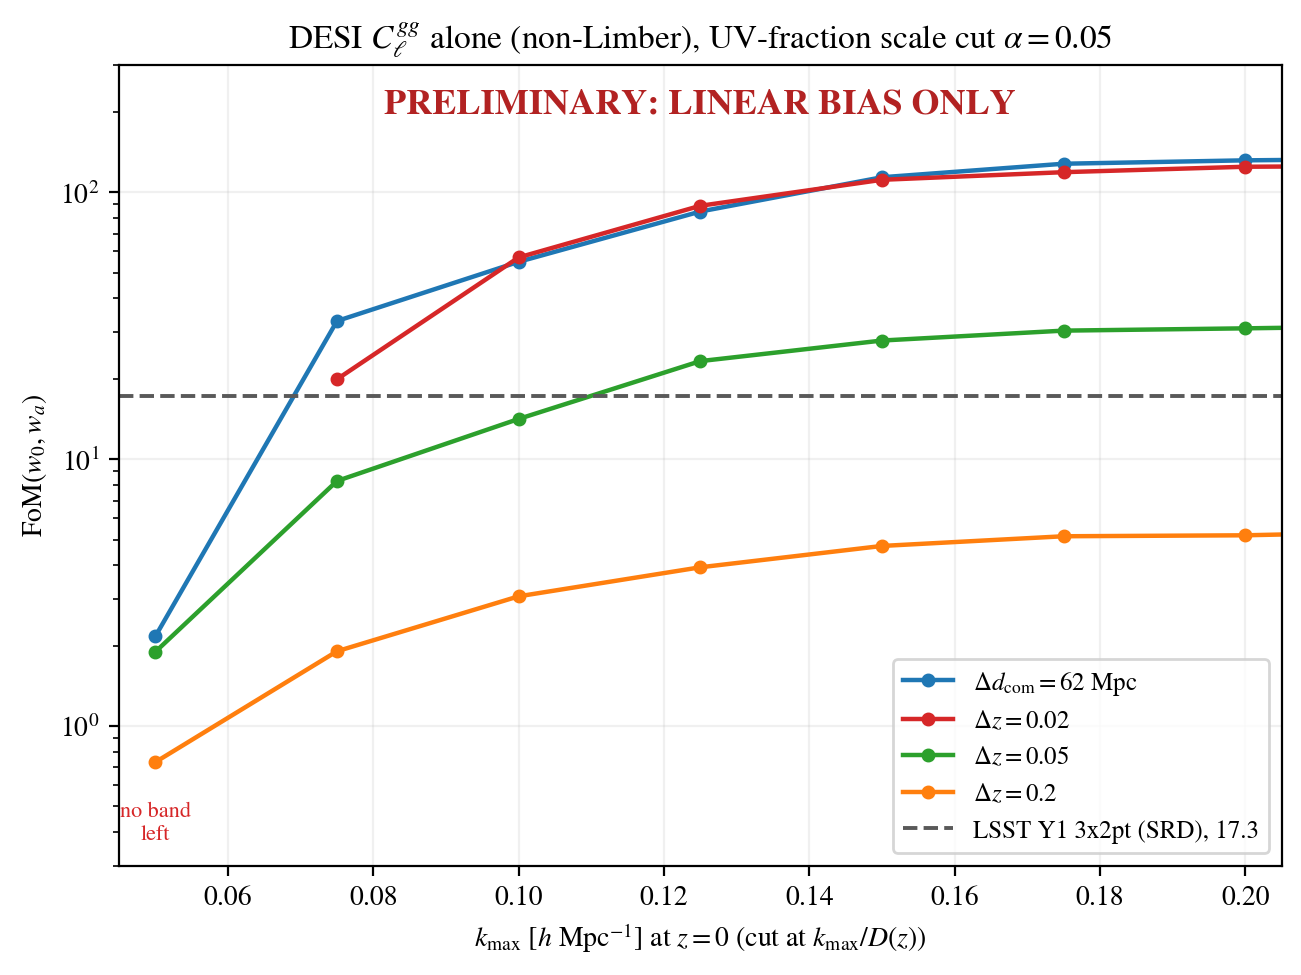

In [32]:
# FoM(w0, wa) of DESI C_gg alone at each k_max of KMAX_CUTS. The Fisher
# matrix is rebuilt from the cached derivatives with the inverse of the
# kept block of the covariance (shipped mask AND the UV-fraction cut): the cut
# removes rows and columns of the covariance before inverting it. The
# Gaussian priors on the velocity dispersions are kept.
FOM_CUTS_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                  'EXAMPLE_EVALUATE_FISHER_FOM_SCALE_CUTS.pkl')
RECOMPUTE_FOM_CUTS = RECOMPUTE_CUTS


def scale_cut_fom(key):
    '''FoM(w0, wa) of DESI C_gg alone at every k_max of KMAX_CUTS.'''
    res = layout_desi[key]
    D = np.array(res['D'][H_MAIN])
    names = list(res['names'])
    F_full = np.array(res['F'][H_MAIN])
    scale = AREA_DEG2/DESI_COV_AREA_DEG2
    cov = layout_covariance(key)
    kept = np.where(cov['mask'])[0]
    F_data = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*scale
    # the Gaussian priors on the velocity dispersions: F_full minus the data
    # part, keeping only the entries well above round-off (every other
    # parameter has a flat prior)
    prior_diag = np.diag(F_full - F_data)
    prior_diag = np.where(np.abs(prior_diag) > 1e-8*np.abs(np.diag(F_full)),
                          prior_diag, 0.0)
    priors = np.diag(prior_diag)
    out = {'fom': [], 'entries': []}
    for m in range(len(KMAX_CUTS)):
        mask, _ = combined_mask(key, m)
        kept = np.where(mask)[0]
        F = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*scale + priors
        # a galaxy bias whose bins lost every band power has no data and a
        # flat prior: its Fisher row is zero. It no longer affects any kept
        # entry, so dropping it leaves the cosmology unchanged; without it
        # the matrix would be singular.
        live = [j for j in range(len(names)) if np.any(F[j] != 0.0)]
        F_live = F[np.ix_(live, live)]
        names_live = [names[j] for j in live]
        if all(p in names_live for p in COSMO):
            out['fom'].append(cosmo_errors(F_live, names_live)[1])
        else:
            # no band power left: nothing constrains the cosmology, FoM = 0
            out['fom'].append(0.0)
        out['entries'].append(len(kept))
    out['fom_shipped'] = cosmo_errors(F_full, names)[1]
    return out


if RECOMPUTE_FOM_CUTS or not os.path.exists(FOM_CUTS_CACHE):
    fom_cuts = {}
    for key in LAYOUT_DATASETS:
        start = time.time()
        fom_cuts[key] = scale_cut_fom(key)
        print(f'{key}: {time.time() - start:.0f} s', flush=True)
    with open(FOM_CUTS_CACHE, 'wb') as f:
        pickle.dump({'fom': fom_cuts, 'settings': settings_now}, f)
else:
    with open(FOM_CUTS_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] != settings_now:
        raise RuntimeError(f'{FOM_CUTS_CACHE} holds other settings: set '
                           'RECOMPUTE_FOM_CUTS = True to rebuild it')
    fom_cuts = cached['fom']

fom_table = {}
for key in LAYOUT_DATASETS:
    row = {}
    for m, kmax in enumerate(KMAX_CUTS):
        row[kmax] = fom_cuts[key]['fom'][m]
    row['shipped'] = fom_cuts[key]['fom_shipped']
    fom_table[key] = row
print('FoM(w0, wa) of DESI C_gg alone; columns: k_max [h/Mpc at z = 0]')
display(pd.DataFrame(fom_table).T)

# LSST Y1 3x2pt in real space, the SRD Y1 setup with its own scale cuts: the
# Fisher forecast of the lsst_y1 project (EXAMPLE_EVALUATE2.ipynb, section
# 18; fiducial w0 = -0.9). A fixed reference, not cut in k_max; this
# notebook's own LSST Y1 3x2pt in band powers gives 17.4 (section 4).
LSST_Y1_SRD_FOM = 17.26

fiducial = dict(zip(desi['names'], desi['fiducial']))
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for key in LAYOUT_DATASETS:
    fom = np.array(fom_cuts[key]['fom'], dtype=float)
    # a FoM of 0 (no band power left) has no place on a log axis: the
    # curve skips it and a note marks the k_max
    ax.plot(KMAX_CUTS, np.where(fom > 0.0, fom, np.nan),
            color=LAYOUT_COLORS[key], marker='o', ms=4, lw=1.6,
            label=LAYOUT_LABELS[key])
    for kmax, value in zip(KMAX_CUTS, fom):
        if value == 0.0:
            ax.text(kmax, 0.36, 'no band\nleft', color=LAYOUT_COLORS[key],
                    fontsize=8, ha='center', va='bottom')
ax.axhline(LSST_Y1_SRD_FOM, color='0.35', ls='--', lw=1.4,
           label=f'LSST Y1 3x2pt (SRD), {LSST_Y1_SRD_FOM:.1f}')
ax.set_yscale('log')
ax.set_ylim(0.3, 300.0)
# the k_max range of the figure stops at 0.2 h/Mpc
ax.set_xlim(0.045, 0.205)
# the galaxy model is linear bias times the nonlinear matter power: a
# preliminary read until the higher-order bias model is in place
ax.text(0.5, 0.97, 'PRELIMINARY: LINEAR BIAS ONLY', transform=ax.transAxes,
        ha='center', va='top', fontsize=13, fontweight='bold',
        color='firebrick')
ax.set_xlabel(r'$k_\mathrm{max}$ [$h$ Mpc$^{-1}$] at $z = 0$ (cut at $k_\mathrm{max}/D(z)$)')
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_title(rf'DESI $C_\ell^{{gg}}$ alone (non-Limber), UV-fraction scale cut '
             rf'$\alpha = {ALPHA_UV}$')
ax.legend(fontsize=9)
plt.show()

### The $w_0$ - $w_a$ ellipses of every layout

The DESI $C_\ell^{gg}$ forecasts of the four layouts on one panel, every other
parameter marginalized; the gray region is excluded by the example prior
($w_0 \le -1/3$ and $-3 \le w_0 + w_a \le -0.01$).

Thinner bins shrink the ellipse mostly through the radial modes: a bin of comoving
width $\Delta\chi$ resolves line-of-sight wavenumbers only up to
$k_\parallel \sim \pi/\Delta\chi$, about $0.006$ Mpc$^{-1}$ at $\Delta z = 0.2$
against $0.06$ Mpc$^{-1}$ at $\Delta z = 0.02$. Those radial modes carry the Kaiser
redshift-space distortions and the radial baryon acoustic oscillations, which break
the degeneracies between the dark-energy parameters and the galaxy bias and which
wide bins average away. The gain saturates once the bins resolve the useful radial
scales - the $\Delta d_\mathrm{com} = 62$ Mpc and $\Delta z = 0.02$ ellipses nearly coincide - as Asorey et al.
2012 ([arXiv:1207.6487](https://arxiv.org/abs/1207.6487)) found for angular
clustering.

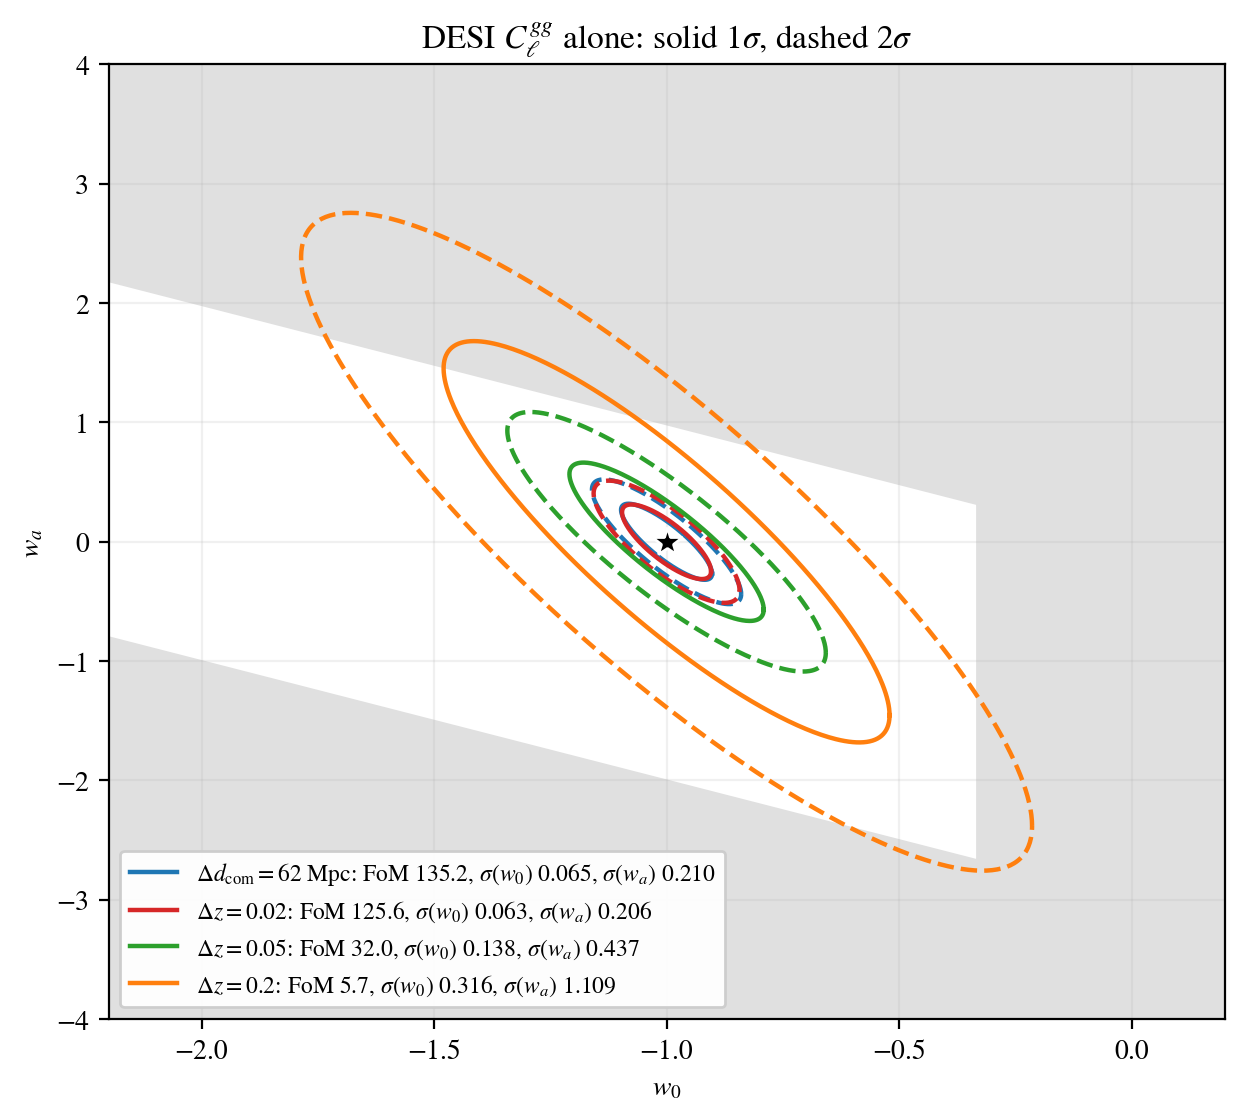

In [33]:
fig, ax = plt.subplots(figsize=(7.2, 6.2))
w0_grid = np.linspace(-2.2, 0.2, 400)
ax.axvspan(-1.0/3.0, 0.2, color='0.88', zorder=0)
ax.fill_between(w0_grid, -0.01 - w0_grid, 4.0, color='0.88', zorder=0)
ax.fill_between(w0_grid, -4.0, -3.0 - w0_grid, color='0.88', zorder=0)
angle = np.linspace(0.0, 2.0*np.pi, 400)
circle = np.vstack([np.cos(angle), np.sin(angle)])
for key in LAYOUT_DATASETS:
    F = np.array(layout_desi[key]['F'][H_MAIN])
    names = list(layout_desi[key]['names'])
    covariance = np.linalg.inv(0.5*(F + F.T))
    rows = [names.index('w0'), names.index('wa')]
    c2 = covariance[np.ix_(rows, rows)]
    center = np.array([fiducial['w0'], fiducial['wa']])
    cholesky = np.linalg.cholesky(c2)
    fom = cosmo_errors(F, names)[1]
    for level, style in ((2.30, '-'), (6.18, '--')):
        contour = center[:, None] + np.sqrt(level)*(cholesky @ circle)
        label = None
        if style == '-':
            label = (f'{LAYOUT_LABELS[key]}: FoM {fom:.1f}, $\\sigma(w_0)$ {np.sqrt(c2[0, 0]):.3f}, '
                     f'$\\sigma(w_a)$ {np.sqrt(c2[1, 1]):.3f}')
        ax.plot(contour[0], contour[1], color=LAYOUT_COLORS[key], ls=style,
                lw=1.6, label=label)
ax.plot([fiducial['w0']], [fiducial['wa']], marker='*', color='k', ms=11,
        mec='white', zorder=5)
ax.set_xlim(-2.2, 0.2)
ax.set_ylim(-4.0, 4.0)
ax.set_xlabel(r'$w_0$')
ax.set_ylabel(r'$w_a$')
ax.set_title(r'DESI $C_\ell^{gg}$ alone: solid $1\sigma$, dashed $2\sigma$')
ax.legend(loc='lower left', fontsize=8.5, framealpha=0.95)
plt.show()

## 9. Limits of this forecast

- **The covariance bias mismatch.** The DESI covariance files set each bin's
  linear bias to its group's raw value (1.34 / 1.70 / 0.84), while the likelihood's
  data vector uses $b_i = B_1/D(\bar z_i)$: the group amplitude $B_1$ (`DESI_B1`)
  divided by the growth factor $D$ at the bin's mean redshift $\bar z_i$. At high
  redshift the covariance's signal term is therefore too small by $D(\bar z_i)^2$,
  which understates the variances and inflates every layout's FoM by a factor of
  about 2.4-3.2: a self-consistent Gaussian covariance gives DESI $C_\ell^{gg}$
  alone FoM about 2.3 ($\Delta z = 0.2$), 13 ($\Delta z = 0.05$), 52
  ($\Delta z = 0.02$) and 42 ($\Delta d_\mathrm{com} = 62$ Mpc) instead of 5.7 / 32 / 126 / 135; the ratios
  between the layouts are unchanged. The fix will be made together with the
  higher-order galaxy bias model, the next modeling step. Until then the absolute
  FoM values of sections 4 and 8 are upper bounds of a rigid linear-bias model,
  not forecasts; the UV-fraction scale cuts of section 8 locate the model's
  defensible range, $k_\mathrm{max} \approx 0.08$-$0.12\,h$ Mpc$^{-1}$, but do
  not repair the covariance.
- **Gaussian covariance only.** Super-sample covariance and the connected trispectrum
  are left out; the shear and galaxy-galaxy lensing signal inside the Gaussian term
  carries NLA with the power law evaluated at each source bin's mean redshift.
- **Independent probes.** The LSST Y1 3x2pt + DESI $C_\ell^{gg}$ sum ignores the
  LSST×DESI cross spectra and the covariance between the two data vectors, although
  the footprints overlap.
- **Linear Fisher biases.** Shifts of order one $\sigma$ or more are outside the linear
  regime; a chain fitted to the alternative vector measures them properly.
- **The numerical floor.** With the halofit patch and the DESI $\chi$-grid boost, the
  vectors are smooth to about $10^{-3}\sqrt{\chi^2}$ per evaluation; section 5 shows
  what is left of the step and accuracy dependence.
- **Completed-survey densities.** The DESI galaxy densities (0.62 per arcmin$^2$
  over $f_\mathrm{sky} \approx 0.3$, about 28 million tracers) correspond to the
  completed DESI survey, not to DR1.